# Health

In [45]:
import requests

r = requests.get("http://127.0.0.1:5000/v2/health")

print(r.status_code)
print(r.text)

200
{"status":"OK","api":"fastapi"}


# Helpers

In [126]:
"""
Client helpers for the FastAPI v2 AI Analytic Engine.

Supported transports
--------------------
FastAPI REST:
    /v2/process-data/...
    /v2/health

FastAPI WebSocket:
    /v2/ws/optimize
    /v2/ws/scenario
    /v2/ws/recommendations

Diagnosis can be added later by extending WEBSOCKET_ENDPOINTS.

WebSocket dependency:
    pip install websocket-client
"""

from __future__ import annotations

import io
import json
import zipfile

import requests


WEBSOCKET_ENDPOINTS = {
    "optimize": "/v2/ws/optimize",
    "scenario": "/v2/ws/scenario",
    "recommendations": "/v2/ws/recommendations",
    "shap": "/v2/ws/shap",
    "diagnosis": "/v2/ws/diagnosis",
    "cost-drivers": "/v2/ws/cost-drivers",
    "scenario": "/v2/ws/scenario",
    "ask-card": "/v2/ws/ask-card"
}


# ======================================================================
# URL helpers
# ======================================================================

def _clean_base_url(endpoint_url: str) -> str:
    return endpoint_url.rstrip("/")


def _http_url(base_url: str, path: str) -> str:
    return f"{_clean_base_url(base_url)}/{path.strip('/')}"


def _ws_url(base_url: str, path: str) -> str:
    """
    Convert an HTTP base URL into a WebSocket URL.

    Examples
    --------
    http://127.0.0.1:5000 -> ws://127.0.0.1:5000
    https://engine/...     -> wss://engine/...
    """
    base = _clean_base_url(base_url)

    if base.startswith("https://"):
        base = "wss://" + base[len("https://") :]
    elif base.startswith("http://"):
        base = "ws://" + base[len("http://") :]
    elif not base.startswith(("ws://", "wss://")):
        base = "ws://" + base

    return f"{base}/{path.strip('/')}"


def _v2_process_data_endpoint(endpoint: str) -> str:
    endpoint = endpoint.strip("/")

    if endpoint.startswith("v2/"):
        return endpoint

    if not endpoint.startswith("process-data"):
        raise ValueError(
            f"{endpoint!r} is not a FastAPI process-data endpoint."
        )

    return f"v2/{endpoint}"


# ======================================================================
# DataFrame / artifact extraction
# ======================================================================

def _dataframe_from_split(payload: dict, name: str):
    """
    Reconstruct a pandas DataFrame from a pandas 'split' payload.
    """
    import pandas as pd

    if not isinstance(payload, dict):
        raise ValueError(
            f"{name!r} must be an object containing "
            "'columns', 'index', and 'data'."
        )

    required = {"columns", "data"}
    missing = required - set(payload)

    if missing:
        raise ValueError(
            f"{name!r} is missing fields: {sorted(missing)}."
        )

    columns = payload["columns"]
    data = payload["data"]
    index = payload.get("index")

    if index is None:
        return pd.DataFrame(
            data=data,
            columns=columns,
        )

    return pd.DataFrame(
        data=data,
        columns=columns,
        index=index,
    )


def _extract_grouped_json(
    out: dict,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /v2/process-data/grouped with output_format='json'.
    """
    from IPython.display import display

    if not isinstance(out, dict):
        raise ValueError(
            "The grouped process-data response must be a JSON object."
        )

    if "data" not in out:
        raise ValueError(
            "The grouped response does not contain 'data'."
        )

    if "grouped" not in out:
        raise ValueError(
            "The grouped response does not contain 'grouped'."
        )

    process_df = _dataframe_from_split(
        out["data"],
        "data",
    )

    grouped_df = _dataframe_from_split(
        out["grouped"],
        "grouped",
    )

    metadata = out.get("metadata", {})

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata


def _extract_grouped_parquet(
    response,
    show_tables: bool = False,
):
    """
    Extract the two DataFrames returned by
    POST /v2/process-data/grouped with output_format='parquet'.

    Expected ZIP members:
        process_data.parquet
        process_grouped.parquet
        metadata.json
    """
    import pandas as pd
    from IPython.display import display

    try:
        archive_buffer = io.BytesIO(response.content)

        with zipfile.ZipFile(archive_buffer) as archive:
            members = set(archive.namelist())

            required = {
                "process_data.parquet",
                "process_grouped.parquet",
            }

            missing = required - members

            if missing:
                raise ValueError(
                    "The grouped Parquet response is missing ZIP members: "
                    f"{sorted(missing)}."
                )

            with archive.open(
                "process_data.parquet"
            ) as parquet_file:
                process_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            with archive.open(
                "process_grouped.parquet"
            ) as parquet_file:
                grouped_df = pd.read_parquet(
                    io.BytesIO(parquet_file.read())
                )

            if "metadata.json" in members:
                with archive.open(
                    "metadata.json"
                ) as metadata_file:
                    metadata = json.load(metadata_file)
            else:
                metadata = {}

    except zipfile.BadZipFile as exc:
        raise ValueError(
            "The server response is not a valid grouped Parquet ZIP file."
        ) from exc

    tables = {
        "process": process_df,
        "grouped": grouped_df,
    }

    if show_tables:
        print("process")
        display(process_df.head())

        print("grouped")
        display(grouped_df.head())

        if metadata:
            print("metadata")
            print(metadata)

    return tables, {}, metadata


def extract(
    out,
    download_artifacts,
    show_text=True,
    show_tables=False,
    show_figures=False,
    base_url="http://127.0.0.1:5000",
):
    """
    Extract tables and Plotly figures from an analytical FastAPI/WebSocket
    result payload.
    """
    import pandas as pd
    import plotly.graph_objects as go
    from IPython.display import display, Markdown

    if not isinstance(out, dict):
        raise ValueError(
            "The analytical response must be a dictionary."
        )

    if show_text and out.get("text"):
        display(Markdown(out["text"]))

    tables = {}
    figures = {}

    if download_artifacts:
        for table in out.get("tables", []):
            table_url = (
                base_url.rstrip("/")
                + table["artifact"]["url"]
            )

            rt = requests.get(
                table_url,
                timeout=120,
            )
            rt.raise_for_status()

            df = pd.read_parquet(
                io.BytesIO(rt.content)
            )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig_url = (
                base_url.rstrip("/")
                + fig_payload["artifact"]["url"]
            )

            rf = requests.get(
                fig_url,
                timeout=120,
            )
            rf.raise_for_status()

            fig = go.Figure(rf.json())
            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    else:
        for table in out.get("tables", []):
            inline = table.get("inline", {})

            if {
                "columns",
                "data",
            }.issubset(inline):
                df = _dataframe_from_split(
                    inline,
                    table.get("id", "table"),
                )
            else:
                df = pd.DataFrame(
                    inline.get("data", [])
                )

            tables[table["id"]] = df

            if show_tables:
                print(table["id"])
                display(df.head())

        for fig_payload in out.get("figures", []):
            fig = go.Figure(
                fig_payload["plotly_json"]
            )

            figures[fig_payload["id"]] = fig

            if show_figures:
                fig.show()

    return tables, figures


# ======================================================================
# WebSocket analytical endpoints
# ======================================================================

def run_websocket_job(
    endpoint: str,
    params: dict,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 30 * 60,
):
    """
    Run one FastAPI analytical WebSocket job and return its final result.

    Current supported endpoint values:
        optimize
        scenario
        recommendations
    """
    try:
        import websocket
    except ImportError as exc:
        raise ImportError(
            "Install WebSocket client support with:\n"
            "    pip install websocket-client"
        ) from exc

    endpoint = endpoint.strip("/")

    if endpoint not in WEBSOCKET_ENDPOINTS:
        raise ValueError(
            f"{endpoint!r} is not configured as a WebSocket endpoint. "
            f"Available endpoints: {sorted(WEBSOCKET_ENDPOINTS)}"
        )

    ws_url = _ws_url(
        endpoint_url,
        WEBSOCKET_ENDPOINTS[endpoint],
    )

    print(f"Connecting: {ws_url}")

    ws = websocket.create_connection(
        ws_url,
        timeout=timeout,
    )

    try:
        ws.send(json.dumps(params))

        previous_status = None
        job_id = None

        while True:
            raw_message = ws.recv()

            if raw_message is None:
                raise RuntimeError(
                    "The WebSocket closed before receiving a final result."
                )

            message = json.loads(raw_message)

            if message.get("job_id"):
                job_id = message["job_id"]

            status = message.get("status")

            if status != previous_status:
                if job_id:
                    print(f"Job {job_id}: {status}")
                else:
                    print(f"Job status: {status}")

                previous_status = status

            if status == "completed":
                if "result" not in message:
                    raise RuntimeError(
                        f"Job {job_id} completed but returned no result."
                    )

                return message["result"]

            if status == "failed":
                error = message.get(
                    "error",
                    "Unknown engine error",
                )

                raise RuntimeError(
                    f"Job {job_id} failed: {error}"
                )

            if status not in {
                "accepted",
                "queued",
                "running",
            }:
                raise RuntimeError(
                    f"Unexpected WebSocket message:\n{message}"
                )

    finally:
        try:
            ws.close()
        except Exception:
            pass


def ask_engine(
    params: dict,
    endpoint: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000",
    job_timeout: float = 30 * 60,
    figures:bool = False
):
    """
    Call a FastAPI analytical WebSocket endpoint and extract its result.

    Example
    -------
    tables, figures = ask_engine(
        params=params,
        endpoint="optimize",
    )
    """
    request_params = dict(params)

    request_params["download_artifacts"] = (
        download_artifacts
    )

    request_params["figures"] = (
            figures
        )

    result = run_websocket_job(
        endpoint=endpoint,
        params=request_params,
        endpoint_url=endpoint_url,
        timeout=job_timeout,
    )

    return extract(
        result,
        download_artifacts,
        show_tables=True,
        show_figures=True,
        base_url=endpoint_url.rstrip("/"),
    )


# ======================================================================
# FastAPI process-data REST endpoints
# ======================================================================

def get_process_data(
    endpoint: str,
    params: dict | None = None,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 120,
):
    """
    Generic GET helper for FastAPI /v2/process-data/... endpoints.

    Examples
    --------
    get_process_data("process-data/grades")

    get_process_data(
        "process-data/reels",
        {
            "start": "2026-08-25T00:00:00",
            "end": "2026-08-26T00:00:00",
        },
    )
    """
    path = _v2_process_data_endpoint(endpoint)
    url = _http_url(endpoint_url, path)

    print(f"Calling: {url}")

    response = requests.get(
        url,
        params=params or {},
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    return response.json()


def get_process_data_parquet(
    params: dict | None = None,
    endpoint_url: str = "http://127.0.0.1:5000",
    timeout: float = 120,
):
    """
    GET /v2/process-data/parquet and return a DataFrame.
    """
    import pandas as pd

    url = _http_url(
        endpoint_url,
        "v2/process-data/parquet",
    )

    print(f"Calling: {url}")

    response = requests.get(
        url,
        params=params or {},
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    return pd.read_parquet(
        io.BytesIO(response.content)
    )


def get_grouped_process_data(
    params: dict,
    endpoint_url: str = "http://127.0.0.1:5000",
    show_tables: bool = True,
    timeout: float = 30 * 60,
):
    """
    POST /v2/process-data/grouped.

    Supports:
        output_format='json'
        output_format='parquet'
    """
    request_params = dict(params)

    output_format = request_params.get(
        "output_format",
        "json",
    )

    if not isinstance(output_format, str):
        raise ValueError(
            "output_format must be 'json' or 'parquet'."
        )

    output_format = output_format.strip().lower()

    if output_format not in {
        "json",
        "parquet",
    }:
        raise ValueError(
            f"Unsupported output_format={output_format!r}."
        )

    request_params["output_format"] = output_format

    url = _http_url(
        endpoint_url,
        "v2/process-data/grouped",
    )

    print(f"Calling: {url}")
    print(f"Output format: {output_format}")

    response = requests.post(
        url,
        json=request_params,
        timeout=timeout,
    )

    print("HTTP status:", response.status_code)
    response.raise_for_status()

    if output_format == "parquet":
        tables, figures, metadata = (
            _extract_grouped_parquet(
                response,
                show_tables=show_tables,
            )
        )
    else:
        payload = response.json()

        tables, figures, metadata = (
            _extract_grouped_json(
                payload,
                show_tables=show_tables,
            )
        )

    return tables, figures, metadata


def run_query(
    query: str,
    download_artifacts: bool = True,
    endpoint_url: str = "http://127.0.0.1:5000",
):
    params = {
        "query": query,
        "download_artifacts": download_artifacts,
        "diagnosis_summary": True,
        "cost_driver_summary": False,
        "translate": True,
    }

    result = run_websocket_job(
        endpoint="ask-card",
        params=params,
        endpoint_url=endpoint_url,
    )

    return extract(
        result,
        download_artifacts,
        show_tables=True,
        show_figures=True,
        base_url=endpoint_url.rstrip("/"),
    )

# Process data

## Raw

### Reels

In [129]:
import requests
import pandas as pd

response = requests.get(
    "http://localhost:5000/v2/process-data/reels",
    params={
        "start": "2026-09-01T00:00:00",
        "end": "2026-09-10T00:00:00"
    }
)
response.raise_for_status()
data = response.json()
pd.DataFrame(data["items"])

,reel_id,timestamp
0,12606177,2026-09-01T02:13:00
1,12606178,2026-09-01T03:12:00
2,12606179,2026-09-01T04:11:00
3,12606180,2026-09-01T05:09:00
4,12606181,2026-09-01T06:08:00
...,...,...
188,12606376,2026-09-09T21:10:00
189,12606377,2026-09-09T22:04:00
190,12606378,2026-09-09T22:57:00
191,12606379,2026-09-09T23:51:00


### Snapshot

#### by timestamp

In [48]:
response = requests.get(
    "http://localhost:5000/v2/process-data/snapshot",
    params={"timestamp": "2026-03-11T15:50:00"},
)

response.raise_for_status()
data = response.json()
pd.DataFrame([data["snapshot"]])

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_Burst,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1
0,2026-03-11T16:08:00,12601838,6010120,2.18,3.97,281.470001,0.0,885.701538,1280.162964,47174.457031,...,None,-38.0,0.733334,-18.633333,0.0,37.0,4.01,2.16,280.130005,0.0


#### by reel id

In [19]:
response = requests.get(
    "http://localhost:5000/v2/process-data/snapshot",
    params={"reel_id": "12601843"},
)

response.raise_for_status()
data = response.json()
pd.DataFrame([data["snapshot"]])

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_Burst,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1
0,2026-03-11T19:40:00,12601843,6010100,2.2,4.01,292.549988,0.0,804.787354,1310.183594,45960.039062,...,None,-31.0,5.666667,-12.666666,4.666667,30.0,4.01,2.28,290.679993,0.0


### Grades

In [21]:
response = requests.get(
    "http://localhost:5000/v2/process-data/grades",
)

response.raise_for_status()
data = response.json()
data["grades"]

['3200115',
 '3300085',
 '3300100',
 '3300110',
 '3300115',
 '3300120',
 '3300125',
 '6010085',
 '6010090',
 '6010100',
 '6010120']

### Variables

#### All variables

In [22]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":None
        },
    )

response.raise_for_status()
data = response.json()
data["variables"]

['3200',
 '3300',
 '6010',
 'AB_Grade_ID',
 'AD6_fabric_tension',
 'AD6_speed',
 'AD7_fabric_tension_bottom',
 'AD7_speed_bottom',
 'AD7_speed_top',
 'APA_400V__-1..10_MW_',
 'APA_660V__-1..10_MW_',
 'APA_660V__-1..10_MW_~^0',
 'APA_6KV__-1..10_MW_',
 'ATS1_differential_pressure',
 'ATS1_light_reject_flow',
 'ATS1_power',
 'ATS2_differential_pressure',
 'ATS2_light_reject_flow',
 'ATS2_power',
 'Act_Deaerator_mass_flow__g/T_',
 'Act_Deaerator_mass_flow__l/h_',
 'Act_Production_Rate_Gross',
 'Actual_moisture',
 'Afterdryers_sensor_1_to_9',
 'Aggregated_cost__€/T_',
 'AirTurn_Temperature',
 'Air_pressure_of_rod_clamping_hose_Bottom_Roll',
 'Air_pressure_of_rod_clamping_hose_Top_Roll',
 'Airturn_pillow_pressure',
 'Aktuelle_Arbeitsbreite_in_cm~^0',
 'Approach_flow_returns',
 'Arbeit_0,7kV_RSM2_und_RTA_(Ab)__MWh_',
 'Arbeit_DSS_P5_Eigenbedarf_Werk_gesamt__MWh_',
 'Ash_measurement_HC-line',
 'Auftrag_Stärkeslurry_BW',
 'Auftrag_Stärkeslurry_FW',
 'BSW_2_sigma',
 'Backflow_cross-flow_distrib

#### by function

In [23]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["SCT CD"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Current_basis_weight',
 'Current_reel_moisture_average(reel)',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'grammage']

In [24]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["SCT CD","steam"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Current_basis_weight',
 'Current_reel_moisture_average(reel)',
 'Current_reel_width',
 'DG1_temperature_Inlet_Air',
 'DG2_temperature_Inlet_Air',
 'DG3_temperature_Inlet_Air',
 'DG4_Temperature_Inlet_Air',
 'DG5_Temperature_Inlet_Air',
 'Dewatering_First_Press_Roll',
 'Dewatering_Shoe_press',
 'Dewatering_Suction_Press_Roll',
 'Dewatering_top_wire_suction_box_zone_2',
 'Dissolved_gas_after_stock_deculator_measurement_1',
 'Dissolved_gas_after_stock_deculator_measurement_2',
 'Dissolved_gas_before_dilution_water_deculator',
 'Draw_PD3-PD4',
 'Fixative_2_mass_flow__g/T_',
 'Free_gas_after_stock_deculator~^0',
 'Free_gas_before_dilution_water_deculator_measurement_1~^0',
 'Free_gas_before_dilution_water_deculator_measurement_2',
 'Headbox_consistency',
 'Jet/wire_ratio',
 'Lip_settings',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Moisture_out_of_PreDryer',
 'PickUp_Tension',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Speed',
 'Starch_uptake_by_pap

In [26]:
response = requests.get(
        "http://localhost:5000/v2/process-data/variables",
        params={
            "functions":["starch uptake"]
        },
    )
response.raise_for_status()
data = response.json()
data["variables"]

['Conductivity_white_water_B46',
 'Current_reel_moisture_average(SpeedSizer)',
 'Moisture_after_SpeedSizer',
 'Moisture_out_of_PreDryer',
 'Rod_Pressure_Bottom_Roll',
 'Rod_pressure_Top_Roll',
 'Speed_Size_Press',
 'Temperature_starch_working_tank_2',
 'Top_wire_tenstion',
 'concentration_starch_working_tank_1',
 'concentration_starch_working_tank_2',
 'grammage']

### Cost label

In [27]:
response = requests.get(
        "http://localhost:5000/v2/process-data/cost-label",
    )
response.raise_for_status()
data = response.json()
data["cost_label"]

'Combined_cost__€/T_'

### Cost components

In [83]:
response = requests.get(
        "http://localhost:5000/v2/process-data/components",
    )
response.raise_for_status()
data = response.json()
data["components"]

{'cost': ['Steam__€/T_',
  'Electricity__€/T_',
  'Starch__€/T_',
  'Chemicals__€/T_',
  'Fibre_cost__€/T_'],
 'consumption': ['Steam__kWh/T_',
  'Electricity__kWh/T_',
  'Starch_mass_flow__kg/T_',
  'Fibre_usage__T/T_'],
 'price': ['Fibre_price',
  'Steam_price',
  'Electricity_price',
  'Starch_price',
  'Natriumhydroxide_price',
  'Defoamer_price',
  'Deaerator_price',
  'Sizing_Agent_price',
  'Dry_Strength_Agent_price',
  'Retention_Aid_price',
  'Bentonite_price',
  'Fixative_2_price']}

### Cost Subcomponents

In [28]:
response = requests.get(
        "http://localhost:5000/v2/process-data/chemical-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["chemical_subcomponents"]

{'cost': ['Retention_Aid__€/T_',
  'Bentonite_1__€/T_',
  'Bentonite_2__€/T_',
  'Fixative_2__€/T_',
  'Deaerator__€/T_',
  'Defoamer__€/T_',
  'Sizing_Agent__€/T_',
  'Dry_Strength_Agent__€/T_',
  'Natriumhydroxide__€/T_'],
 'consumption': ['Retention_Aid_mass_flow__g/T_',
  'Bentonite_1_mass_flow__g/T_',
  'Bentonite_2_mass_flow__g/T_',
  'Fixative_2_mass_flow__g/T_',
  'Act_Deaerator_mass_flow__g/T_',
  'Defoamer_mass_flow__g/T_',
  'Sizing_Agent__g/T_',
  'Dry_Strength_Agent_mass_flow__g/T_',
  'Natriumhydroxide_mass_flow__g/T_']}

In [31]:
response = requests.get(
        "http://localhost:5000/v2/process-data/steam-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["steam_subcomponents"]

{'cost': ['Steam_Predryers__€/T_',
  'Steam_Afterdryers__€/T_',
  'Steam_Starchkitchen__€/T_',
  'Steam_Heatexchangers__€/T_',
  'Steam_Whitewater__€/T_'],
 'consumption': ['Steam_Predryers__kWh/T_',
  'Steam_Afterdryers__kWh/T_',
  'Steam_Starchkitchen__kWh/T_',
  'Steam_Heatexchangers__kWh/T_',
  'Steam_Whitewater__kWh/T_']}

In [32]:
response = requests.get(
        "http://localhost:5000/v2/process-data/electricity-subcomponents",
    )
response.raise_for_status()
data = response.json()
data["electricity_subcomponents"]

{'cost': ['Electricity_Wiresection__€/T_',
  'Electricity_Press_and_Steambox__€/T_',
  'Electricity_Freqconverters__€/T_',
  'Electricity_Other__€/T_',
  'Electricity_Predryer__€/T_',
  'Electricity_Afterdryer__€/T_',
  'Electricity_Specific__€/T_'],
 'consumption': ['Electricity_Wiresection__kWh/T_',
  'Electricity_Press_and_Steambox__kWh/T_',
  'Electricity_Freqconverters__kWh/T_',
  'Electricity_Other__kWh/T_',
  'Electricity_Predryer__kWh/T_',
  'Electricity_Afterdryer__kWh/T_',
  'Electricity_Specific__kWh/T_']}

### Variable bounds

In [42]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            'Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_'      
        ],
        #"grade": "6010120",
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)
response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Steam__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,79.663860,99.325542,None,None,None,None
1,Electricity__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,32.445215,42.859491,None,None,None,None
2,Starch__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,17.990190,26.511199,None,None,None,None
3,Chemicals__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,2.575141,8.868206,None,None,None,None
4,Fibre_cost__€/T_,True,ALL,marginal_quantile,marginal_quantile,None,126.512737,129.643153,None,None,None,None


In [43]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "grades": ["6010120","6010100"],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Current_basis_weight,True,6010120,marginal_quantile,marginal_quantile,None,118.001073,121.293686,None,None,None,None
1,Current_reel_moisture_average(reel),True,6010120,marginal_quantile,marginal_quantile,None,7.798764,8.383088,None,None,None,None
2,Current_basis_weight,True,6010100,marginal_quantile,marginal_quantile,None,99.502520,101.890709,None,None,None,None
3,Current_reel_moisture_average(reel),True,6010100,marginal_quantile,marginal_quantile,None,7.590360,8.214874,None,None,None,None


In [45]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            ['Steam__€/T_','Electricity__€/T_','Starch__€/T_','Chemicals__€/T_','Fibre_cost__€/T_']   
        ],
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)
response.raise_for_status()
df = pd.DataFrame(response.json()["bounds"])[["lower_bound","upper_bound","variable"]]
df["median"] = df["lower_bound"] + df["upper_bound"]
df["weight"] = df["median"] / df["median"] .sum()
df[["weight","variable"]]

,weight,variable
0,0.316015,Steam__€/T_
1,0.132954,Electricity__€/T_
2,0.078570,Starch__€/T_
3,0.020204,Chemicals__€/T_
4,0.452257,Fibre_cost__€/T_


In [46]:
response = requests.get(
    "http://localhost:5000/v2/process-data/variable-bounds",
    params={
        "variables": [
            "Current_basis_weight", 'Current_reel_moisture_average(reel)'      
        ],
        "reel_id": 12602792,
        "lower_percentile": 0.05,
        "upper_percentile": 0.95
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["bounds"])

,variable,available,grade,method,mode,current_value,lower_bound,upper_bound,conditional_lower_bound,conditional_upper_bound,conditional_median,conditional_error
0,Current_basis_weight,True,6010120,joint_conditional,conditional_joint_distribution,118.834610,117.925124,121.177685,117.925124,121.177685,118.899438,None
1,Current_reel_moisture_average(reel),True,6010120,joint_conditional,conditional_joint_distribution,8.308628,7.808433,8.408472,7.808433,8.408472,8.273570,None


### Function (cost or strength) evaluation

In [47]:
import requests

response = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD"]
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["predictions"])

,function,available,prediction,features,n_features
0,SCT CD,True,2.187086,"[Current_reel_moisture_average(reel), Short_fi...",13


In [48]:
pd.DataFrame(response.json()["predictions"]).iloc[0]["features"]

['Current_reel_moisture_average(reel)',
 'Short_fibre_flow',
 'Long_fibre_consistency_B07',
 'Starch_uptake_by_paper_Top_Roll__g/m2_',
 'Jet/wire_ratio',
 'Headbox_consistency',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Long_fibre_flow',
 'MBS_SCT_CD_L1',
 'Current_basis_weight',
 'grammage',
 'Lip_settings',
 'Short_fibre_B06_consistency']

In [60]:
import requests

response = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reel_id": 12602792,
        "functions": ["SCT CD", "steam", "electricity"]
    }
)

response.raise_for_status()
data = response.json()
pd.DataFrame(data["predictions"])

,function,available,prediction,features,n_features
0,SCT CD,True,2.168723,"[Current_reel_moisture_average(reel), Short_fi...",13
1,steam,True,79.985772,"[Vacuum_suction_box_9, Vacuum_uhle-box_bottom_...",43
2,electricity,True,33.984969,"[Speed, Vacuum_wire_suction_box_2, Vacuum_uhle...",38


### Process Data

In [83]:
table = get_process_data_parquet(params = {
    "grade": "6010120",
    "start": "2026-01-01",
    "end": "2026-08-01",
    "variables": "MBS_SCT_CD,Combined_cost__€/T_",
})

table

Calling: http://127.0.0.1:5000/v2/process-data/parquet
HTTP status: 200


,Wedge_Time,AB_Grade_ID,MBS_Current_reel_ID,MBS_SCT_CD,Combined_cost__€/T_
0,2026-01-02 20:28:00,6010120,12600001,2.21,291.020346
1,2026-01-02 20:50:00,6010120,12600002,2.16,287.617430
2,2026-01-02 21:54:00,6010120,12600003,2.16,284.360049
3,2026-01-02 22:51:00,6010120,12600004,2.32,284.873316
4,2026-01-02 23:48:00,6010120,12600005,2.33,285.790492
...,...,...,...,...,...
1729,2026-07-30 07:23:00,6010120,12605385,2.07,272.342885
1730,2026-07-30 08:56:00,6010120,12605387,2.15,273.615530
1731,2026-07-30 12:22:00,6010120,12605388,2.22,273.112193
1732,2026-07-30 13:19:00,6010120,12605389,2.25,277.808141


In [22]:
import pandas as pd

### Grouped Process Data

#### Weekly cost grouped by grade. Output format JSON

In [113]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": 'Chemicals__€/T_',
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    # "grades": [
    #     "3300110",
    #     "6010100",
    # ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "output_format": "json",
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Chemicals__€/T_,AB_Grade_ID
6036,12601665,85,6010,2026,10,2.840678,6010085
6037,12601666,85,6010,2026,10,2.896048,6010085
6038,12601667,85,6010,2026,10,3.034857,6010085
6039,12601668,85,6010,2026,10,2.983574,6010085
6040,12601669,85,6010,2026,10,2.986245,6010085


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Chemicals__€/T_,n
0,2026,9,3200115,8.009626,12
1,2026,9,3300120,7.614721,5
2,2026,9,6010120,2.589042,8
3,2026,10,3200115,8.068110,32
4,2026,10,3300100,7.872999,12


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '3300100': 'rgb(42, 184, 232)', '6010100': 'rgb(51, 240, 151)', '3300110': 'rgb(164, 252, 59)', '3200115': 'rgb(235, 206, 57)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 1562, 'grouped_rows': 68}


In [114]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": ['Retention_Aid__g/T_','Bentonite_1__g/T_','Bentonite_2__g/T_','Fixative_2__g/T_', 'Act_Deaerator__g/T_','Defoamer__g/T_','Sizing_Agent__g/T_','Dry_Strength_Agent__g/T_','Natriumhydroxide__g/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "parquet",
})

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: parquet
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__g/T_,200.538544
1,12601628,2026,10,6010100,100,6010,Retention_Aid__g/T_,205.352402
2,12601629,2026,10,6010100,100,6010,Retention_Aid__g/T_,202.695282
3,12601630,2026,10,6010100,100,6010,Retention_Aid__g/T_,230.961426
4,12601631,2026,10,6010100,100,6010,Retention_Aid__g/T_,201.281677


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Act_Deaerator__g/T_,136.039734,8
1,2026,9,6010120,Bentonite_1__g/T_,1774.449585,8
2,2026,9,6010120,Bentonite_2__g/T_,1267.459229,8
3,2026,9,6010120,Defoamer__g/T_,75.124191,8
4,2026,9,6010120,Dry_Strength_Agent__g/T_,0.000000,8


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'variable', 'color_map': {'Retention_Aid__g/T_': '#636EFA', 'Bentonite_1__g/T_': '#EF553B', 'Bentonite_2__g/T_': '#00CC96', 'Fixative_2__g/T_': '#AB63FA', 'Act_Deaerator__g/T_': '#FFA15A', 'Defoamer__g/T_': '#19D3F3', 'Sizing_Agent__g/T_': '#FF6692', 'Dry_Strength_Agent__g/T_': '#B6E880', 'Natriumhydroxide__g/T_': '#FF97FF'}, 'prepared_rows': 6489, 'grouped_rows': 162}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__g/T_,200.538544
1,12601628,2026,10,6010100,100,6010,Retention_Aid__g/T_,205.352402
2,12601629,2026,10,6010100,100,6010,Retention_Aid__g/T_,202.695282
3,12601630,2026,10,6010100,100,6010,Retention_Aid__g/T_,230.961426
4,12601631,2026,10,6010100,100,6010,Retention_Aid__g/T_,201.281677


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Act_Deaerator__g/T_,136.039734,8
1,2026,9,6010120,Bentonite_1__g/T_,1774.449585,8
2,2026,9,6010120,Bentonite_2__g/T_,1267.459229,8
3,2026,9,6010120,Defoamer__g/T_,75.124191,8
4,2026,9,6010120,Dry_Strength_Agent__g/T_,0.000000,8


In [86]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": ['Retention_Aid__€/T_','Bentonite_1__€/T_','Bentonite_2__€/T_','Fixative_2__€/T_','Deaerator__€/T_','Defoamer__€/T_','Sizing_Agent__€/T_','Dry_Strength_Agent__€/T_','Natriumhydroxide__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
})

df = tables["process"]
dfg = tables["grouped"]

display(df.head())
display(dfg.head())

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8
2,2026,9,6010120,Deaerator__€/T_,0.208141,8
3,2026,9,6010120,Defoamer__€/T_,0.317024,8
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'variable', 'color_map': {'Retention_Aid__€/T_': '#636EFA', 'Bentonite_1__€/T_': '#EF553B', 'Bentonite_2__€/T_': '#00CC96', 'Fixative_2__€/T_': '#AB63FA', 'Deaerator__€/T_': '#FFA15A', 'Defoamer__€/T_': '#19D3F3', 'Sizing_Agent__€/T_': '#FF6692', 'Dry_Strength_Agent__€/T_': '#B6E880', 'Natriumhydroxide__€/T_': '#FF97FF'}, 'prepared_rows': 6489, 'grouped_rows': 162}


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,variable,value
0,12601627,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.818197
1,12601628,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.837838
2,12601629,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.826997
3,12601630,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.942323
4,12601631,2026,10,6010100,100,6010,Retention_Aid__€/T_,0.821229


,Wedge_Year,Wedge_Week,AB_Grade_ID,variable,value,n
0,2026,9,6010120,Bentonite_1__€/T_,0.496846,8
1,2026,9,6010120,Bentonite_2__€/T_,0.354889,8
2,2026,9,6010120,Deaerator__€/T_,0.208141,8
3,2026,9,6010120,Defoamer__€/T_,0.317024,8
4,2026,9,6010120,Dry_Strength_Agent__€/T_,0.000000,8


#### Weekly cost grouped by grade. Output format zipped parquet files

In [87]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Combined_cost__€/T_,AB_Grade_ID
5998,12601627,100,6010,2026,10,286.645849,6010100
5999,12601628,100,6010,2026,10,285.998090,6010100
6000,12601629,100,6010,2026,10,286.479808,6010100
6001,12601630,100,6010,2026,10,300.151970,6010100
6002,12601631,100,6010,2026,10,285.234605,6010100


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Combined_cost__€/T_,n
0,2026,9,6010120,277.834288,8
1,2026,10,6010100,285.976041,30
2,2026,10,6010120,274.692096,62
3,2026,11,6010100,285.514637,18
4,2026,11,6010120,274.375505,89


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 18}


#### Daily SCT CD

In [88]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "day",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Date,MBS_SCT_CD,AB_Grade_ID
5998,12601627,100,6010,2026-03-04,1.82,6010100
5999,12601628,100,6010,2026-03-04,1.85,6010100
6000,12601629,100,6010,2026-03-04,1.85,6010100
6001,12601630,100,6010,2026-03-04,1.84,6010100
6002,12601631,100,6010,2026-03-04,1.77,6010100


grouped


,Wedge_Date,AB_Grade_ID,MBS_SCT_CD,n
0,2026-03-01,6010120,2.135000,8
1,2026-03-02,6010120,2.146875,32
2,2026-03-03,6010120,2.140400,25
3,2026-03-04,6010100,1.849231,13
4,2026-03-04,6010120,2.088000,5


metadata
{'x_variable': 'Wedge_Date', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 47}


#### Average SCT CD by grade

In [89]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "MBS_SCT_CD",
    "x_variable_summary": "grade",
    "color_variable_summary": None,
    "grades": [
        "6010120",
        "6010100",
        "6010085",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,MBS_SCT_CD
6036,12601665,85,6010,6010085,1.55
6037,12601666,85,6010,6010085,1.55
6038,12601667,85,6010,6010085,1.55
6039,12601668,85,6010,6010085,1.69
6040,12601669,85,6010,6010085,1.55


grouped


,AB_Grade_ID,grammage,paper_type,MBS_SCT_CD,n
0,6010085,85,6010,1.551749,263
1,6010100,100,6010,1.863085,201
2,6010120,120,6010,2.162116,520


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': None, 'color_map': None, 'prepared_rows': 984, 'grouped_rows': 3}


#### Monthly steam values by grade

In [90]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Steam__€/T_",
    "x_variable_summary": "month",
    "color_variable_summary": "grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Month,Steam__€/T_,AB_Grade_ID
5998,12601627,100,6010,2026,3,93.689979,6010100
5999,12601628,100,6010,2026,3,92.715453,6010100
6000,12601629,100,6010,2026,3,93.459721,6010100
6001,12601630,100,6010,2026,3,96.787815,6010100
6002,12601631,100,6010,2026,3,93.616708,6010100


grouped


,Wedge_Year,Wedge_Month,AB_Grade_ID,Steam__€/T_,n
0,2026,3,6010100,91.580595,104
1,2026,3,6010120,86.848664,291
2,2026,4,6010100,91.035343,97
3,2026,4,6010120,86.851371,229


metadata
{'x_variable': 'Wedge_Month', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010100': 'rgb(48, 18, 59)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 4}


#### Several cost components by week

In [91]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "agg_cost_label": "Cost__€/T_",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})


Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Cost__€/T_
0,12601557,2026,9,120,6010,Steam__€/T_,89.284146
1,12601558,2026,9,120,6010,Steam__€/T_,94.430400
2,12601559,2026,9,120,6010,Steam__€/T_,88.291079
3,12601560,2026,9,120,6010,Steam__€/T_,88.251851
4,12601561,2026,9,120,6010,Steam__€/T_,87.696936


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.589042,8
1,2026,9,Electricity__€/T_,33.051224,8
2,2026,9,Fibre_cost__€/T_,127.899492,8
3,2026,9,Starch__€/T_,25.173524,8
4,2026,9,Steam__€/T_,89.121007,8


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2600, 'grouped_rows': 50}


#### Cost components by week and grade

In [92]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "week",
    "color_variable_summary": "cost_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_
0,12601627,2026,10,6010100,100,6010,Steam__€/T_,93.689979
1,12601628,2026,10,6010100,100,6010,Steam__€/T_,92.715453
2,12601629,2026,10,6010100,100,6010,Steam__€/T_,93.459721
3,12601630,2026,10,6010100,100,6010,Steam__€/T_,96.787815
4,12601631,2026,10,6010100,100,6010,Steam__€/T_,93.616708


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6010120,2.589042,8
1,2026,9,Electricity__€/T_,6010120,33.051224,8
2,2026,9,Fibre_cost__€/T_,6010120,127.899492,8
3,2026,9,Starch__€/T_,6010120,25.173524,8
4,2026,9,Steam__€/T_,6010120,89.121007,8


metadata
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 3605, 'grouped_rows': 90}


#### Overprocessing by week

In [93]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing",
    "grades": [
        "6010120",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,cost,Overprocessing_percentage
0,12601557,2026,9,120,6010,SCT_CD,4.878053
1,12601558,2026,9,120,6010,SCT_CD,2.439020
2,12601559,2026,9,120,6010,SCT_CD,2.926824
3,12601560,2026,9,120,6010,SCT_CD,6.341467
4,12601561,2026,9,120,6010,SCT_CD,5.365858


grouped


,Wedge_Year,Wedge_Week,cost,Overprocessing_percentage,n
0,2026,9,Burst,NaN,8
1,2026,9,CMT30,-100.000000,8
2,2026,9,SCT_CD,4.146342,8
3,2026,10,Burst,NaN,62
4,2026,10,CMT30,-100.000000,62


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 1560, 'grouped_rows': 30}


#### Overprocessing by week and grade

In [94]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Overprocessing_percentage",
    "x_variable_summary": "week",
    "color_variable_summary": "overprocessing_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,AB_Grade_ID,grammage,paper_type,cost,Overprocessing_percentage
0,12601627,2026,10,6010100,100,6010,SCT_CD,7.058827
1,12601628,2026,10,6010100,100,6010,SCT_CD,8.823531
2,12601629,2026,10,6010100,100,6010,SCT_CD,8.823531
3,12601630,2026,10,6010100,100,6010,SCT_CD,8.235296
4,12601631,2026,10,6010100,100,6010,SCT_CD,4.117646


grouped


,Wedge_Year,Wedge_Week,cost,AB_Grade_ID,Overprocessing_percentage,n
0,2026,9,Burst,6010120,NaN,8
1,2026,9,CMT30,6010120,-100.000000,8
2,2026,9,SCT_CD,6010120,4.146342,8
3,2026,10,Burst,6010100,NaN,30
4,2026,10,Burst,6010120,NaN,62


metadata
{'x_variable': 'Wedge_Week', 'color_variable': ['cost', 'AB_Grade_ID'], 'color_map': {'SCT_CD': '#636EFA', 'Burst': '#EF553B', 'CMT30': '#00CC96'}, 'prepared_rows': 2163, 'grouped_rows': 54}


#### Target comparison

In [95]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,Combined_cost__€/T_,target
5998,12601627,100,6010,6010100,286.645849,historic
5999,12601628,100,6010,6010100,285.998090,historic
6000,12601629,100,6010,6010100,286.479808,historic
6001,12601630,100,6010,6010100,300.151970,historic
6002,12601631,100,6010,6010100,285.234605,historic


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
1,6010100,historic,100,6010,285.054066,104
3,6010120,historic,120,6010,274.036403,291
0,6010100,current,100,6010,284.155641,97
2,6010120,current,120,6010,274.510929,229


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': 'target', 'color_map': {'historic': 'blue', 'current': 'red'}, 'prepared_rows': 721, 'grouped_rows': 4}


#### Target and week comparison

In [96]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Combined_cost__€/T_",
    "x_variable_summary": "grade",
    "color_variable_summary": "target_grade",
    "grades": [
        "6010120",
        "6010100",
    ],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,AB_Grade_ID,Combined_cost__€/T_,target,_target_grade
5998,12601627,100,6010,6010100,286.645849,historic,historic | 6010100
5999,12601628,100,6010,6010100,285.998090,historic,historic | 6010100
6000,12601629,100,6010,6010100,286.479808,historic,historic | 6010100
6001,12601630,100,6010,6010100,300.151970,historic,historic | 6010100
6002,12601631,100,6010,6010100,285.234605,historic,historic | 6010100


grouped


,AB_Grade_ID,target,grammage,paper_type,Combined_cost__€/T_,n
0,6010100,current,100,6010,284.155641,97
1,6010100,historic,100,6010,285.054066,104
2,6010120,current,120,6010,274.510929,229
3,6010120,historic,120,6010,274.036403,291


metadata
{'x_variable': 'AB_Grade_ID', 'color_variable': ['target', 'AB_Grade_ID'], 'color_map': {'historic | 6010100': 'rgb(48, 18, 59)', 'current | 6010100': 'rgb(33, 226, 181)', 'historic | 6010120': 'rgb(247, 184, 54)', 'current | 6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 721, 'grouped_rows': 4}


In [97]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Combined_cost__€/T_",
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601557,2026,9,120,6010,1234.065186,Steam__€/T_,89.284146
1,12601558,2026,9,120,6010,1233.718628,Steam__€/T_,94.430400
2,12601559,2026,9,120,6010,1233.925171,Steam__€/T_,88.291079
3,12601560,2026,9,120,6010,1233.878296,Steam__€/T_,88.251851
4,12601561,2026,9,120,6010,1233.819702,Steam__€/T_,87.696936


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,2.589042,8
1,2026,9,Electricity__€/T_,33.051224,8
2,2026,9,Fibre_cost__€/T_,127.899492,8
3,2026,9,Starch__€/T_,25.173524,8
4,2026,9,Steam__€/T_,89.121007,8


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'cost', 'color_map': {'Steam__€/T_': '#636EFA', 'Electricity__€/T_': '#EF553B', 'Starch__€/T_': '#00CC96', 'Chemicals__€/T_': '#AB63FA', 'Fibre_cost__€/T_': '#FFA15A'}, 'prepared_rows': 2600, 'grouped_rows': 50}


#### Weekly production

In [98]:
tables, figures, metadata = get_grouped_process_data(params = {
   "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight
6036,12601665,85,6010,2026,10,39053.671875
6037,12601666,85,6010,2026,10,3928.125488
6038,12601667,85,6010,2026,10,2170.519043
6039,12601668,85,6010,2026,10,47892.410156
6040,12601669,85,6010,2026,10,48490.164062


grouped


,Wedge_Year,Wedge_Week,Current_reel_weight,n
0,2026,9,1079478.0,25
1,2026,10,7481403.0,187
2,2026,11,6694248.5,199
3,2026,12,5517145.0,144
4,2026,13,7787650.0,183


metadata
{'x_variable': 'Wedge_Week', 'color_variable': None, 'color_map': None, 'prepared_rows': 1562, 'grouped_rows': 10}


#### Weekly production by grade

In [99]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight,AB_Grade_ID
6036,12601665,85,6010,2026,10,39053.671875,6010085
6037,12601666,85,6010,2026,10,3928.125488,6010085
6038,12601667,85,6010,2026,10,2170.519043,6010085
6039,12601668,85,6010,2026,10,47892.410156,6010085
6040,12601669,85,6010,2026,10,48490.164062,6010085


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,3200115,5.499319e+05,12
1,2026,9,3300120,1.946935e+05,5
2,2026,9,6010120,3.348525e+05,8
3,2026,10,3200115,1.330034e+06,32
4,2026,10,3300100,4.949843e+05,12


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010085': 'rgb(48, 18, 59)', '6010090': 'rgb(69, 105, 220)', '3300100': 'rgb(42, 184, 232)', '6010100': 'rgb(51, 240, 151)', '3300110': 'rgb(164, 252, 59)', '3200115': 'rgb(235, 206, 57)', '3300115': 'rgb(248, 127, 33)', '3300120': 'rgb(207, 48, 5)', '6010120': 'rgb(122, 4, 2)'}, 'prepared_rows': 1562, 'grouped_rows': 68}


In [100]:
tables, figures, metadata = get_grouped_process_data(params = {
    "y_variable_summary": "Current_reel_weight",
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "grades": ["6010120"],
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
})

Calling: http://127.0.0.1:5000/v2/process-data/grouped
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,grammage,paper_type,Wedge_Year,Wedge_Week,Current_reel_weight,AB_Grade_ID
5928,12601557,120,6010,2026,9,39393.691406,6010120
5929,12601558,120,6010,2026,9,31964.667969,6010120
5930,12601559,120,6010,2026,9,47270.652344,6010120
5931,12601560,120,6010,2026,9,46791.785156,6010120
5932,12601561,120,6010,2026,9,33496.273438,6010120


grouped


,Wedge_Year,Wedge_Week,AB_Grade_ID,Current_reel_weight,n
0,2026,9,6010120,3.348525e+05,8
1,2026,10,6010120,2.551579e+06,62
2,2026,11,6010120,3.692421e+06,89
3,2026,12,6010120,2.089824e+06,53
4,2026,13,6010120,2.812333e+06,63


metadata
{'x_variable': 'Wedge_Week', 'color_variable': 'AB_Grade_ID', 'color_map': {'6010120': 'rgb(164, 252, 59)'}, 'prepared_rows': 520, 'grouped_rows': 10}


## Query

In [ ]:
#run_query("show steam cost for grade 6010120 for week 11"),
#run_query("show starch uptake top for grade 6010120 in February"),
#run_query("show starch uptake for grade 6010120 in February"),
#run_query("show SCT CD not overprocessing for grade 6010120 in February"),
#run_query("show starch uptake not top bottom with SCT CD not overprocessing on secondary axis for grade 6010120 in February"),
tables, figures  = run_query("show current basis weight and starch uptake not top bottom in secondary axis for grade 6010120 in week 12")

# Shap values

## Raw

In [130]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job c71bf024-c42a-4df2-b38c-f7b784249607: accepted
Job c71bf024-c42a-4df2-b38c-f7b784249607: running
Job c71bf024-c42a-4df2-b38c-f7b784249607: completed


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `39`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `39`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,retention,0.804948,-0.008249
1,0,Current_reel_width,756.619568,-0.012547
2,0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,0.022009
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.033026,0.001732
4,0,MBS_SCT_CD_state,1.821526,0.028027


In [131]:
tables, figures = ask_engine(params = {
    "target": "SCT MD",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap", figures=True
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: accepted
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: running
Job b9d3ca4b-848c-42c9-ae10-404228bde89b: completed


## SHAP values

Computed SHAP values for **SCT MD**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `39`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `39`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Moisture_after_SpeedSizer,30.658701,0.044758
1,0,Headbox_consistency,1.328340,0.007351
2,0,Lip_settings,11.159145,-0.024408
3,0,Current_reel_width,756.619568,-0.039675
4,0,MBS_SCT_MD_state,3.762428,0.313757


In [111]:
tables, figures = ask_engine(params = {
    "target": "starch uptake",
    "grade": "3200115",
    "start": "2026-06-01",
    "end": "2026-07-01",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job bcc234fc-f8a8-466d-be57-289c81352680: accepted
Job bcc234fc-f8a8-466d-be57-289c81352680: running
Job bcc234fc-f8a8-466d-be57-289c81352680: completed


## SHAP values

Computed SHAP values for **starch uptake**.

- Rows explained: `169`
- Background rows: `200`
- Model features used for computation: `20`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `20`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,concentration_starch_working_tank_2,11.985752,-0.557635
1,0,concentration_starch_working_tank_1,11.992792,-1.882551
2,0,Moisture_after_SpeedSizer,30.658701,0.177056
3,0,Temperature_starch_working_tank_1,80.370354,0.097525
4,0,Temperature_starch_working_tank_2,77.102791,0.110119


In [59]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 200,
    "background_rows": 200,
    "max_features":5,
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job fab04bb7-c71c-463a-a342-ca4591140c34: accepted
Job fab04bb7-c71c-463a-a342-ca4591140c34: running
Job fab04bb7-c71c-463a-a342-ca4591140c34: completed


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `44`
- Background rows: `200`
- Model features used for computation: `43`
- Features returned: `5`
- Ignored requested variables: `0`- Model features used for computation: `43`
- Features returned: `5`

shap_values


,row_id,feature,value,shap_value
0,0,Vacuum_suction_box_9,-0.330190,1.797781
1,0,ambient_temp_C,5.216667,1.773209
2,0,Vacuum_wet_suction_box,-0.099893,-1.396320
3,0,Draw_PD3-PD4,0.350026,0.870490
4,0,Speed,1280.972412,-1.208183


In [114]:
tables, figures = ask_engine(params = {
    "target": "steam",
    "grade": "3200115",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 100,
    "variables":['Speed']
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 70c0ec87-bc16-41e2-840c-049e597c380b: accepted
Job 70c0ec87-bc16-41e2-840c-049e597c380b: running
Job 70c0ec87-bc16-41e2-840c-049e597c380b: completed


## SHAP values

Computed SHAP values for **steam**.

- Rows explained: `44`
- Background rows: `100`
- Model features used for computation: `43`
- Features returned: `1`
- Ignored requested variables: `0`- Model features used for computation: `43`
- Features returned: `1`

shap_values


,row_id,feature,value,shap_value
0,0,Speed,1280.972412,-1.336180
1,1,Speed,1280.816040,-1.334038
2,2,Speed,1280.841919,-1.334701
3,3,Speed,1280.951050,-1.336594
4,4,Speed,1280.804688,-1.333929


In [115]:
tables, figures = ask_engine(params = {
    "target": "SCT CD",
    "grade": "6010120",
    "start": "2026-03-01",
    "end": "2026-03-10",
    "max_rows": 100,
    "background_rows": 50
}, endpoint="shap"
)

Connecting: ws://127.0.0.1:5000/v2/ws/shap
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: accepted
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: running
Job 9121d0e6-48cc-4a33-8564-30cea1f62340: completed


## SHAP values

Computed SHAP values for **SCT CD**.

- Rows explained: `100`
- Background rows: `50`
- Model features used for computation: `17`
- Features returned: `15`
- Ignored requested variables: `0`- Model features used for computation: `17`
- Features returned: `15`

shap_values


,row_id,feature,value,shap_value
0,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.077065,-0.000090
1,0,Moisture_after_SpeedSizer,30.270906,0.016923
2,0,concentration_starch_working_tank_1,13.018085,0.001947
3,0,Lip_settings,11.649321,0.000442
4,0,Linepressure_shoe_press__bar_,101.593246,0.000210


## Query

In [61]:
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April"),
#tables, figures  = run_query("explain model for steam cost for grade 6010120"),
#tables, figures  = run_query("explain model for total cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for starch cost for grade 6010120 in April"),
#tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")
tables, figures  = run_query("explain model for SCT CD for grade 6010120 in April 2026")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: accepted
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: running
Job 0a1e8e75-98f1-4d79-b2bc-a5c879814180: completed


## SHAP analysis

**Function:** `SCT CD` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-08-02` to `2026-08-30` 

### Summary

Computed SHAP values using the selected target period and the baseline period as reference.

table


,row_id,feature,value,shap_value
0,0,Current_reel_moisture_average(reel),7.959954,0.006371
1,0,Short_fibre_flow,14532.161133,0.000786
2,0,Long_fibre_consistency_B07,4.782810,-0.000115
3,0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.153534,0.002417
4,0,Jet/wire_ratio,-24.179436,-0.003791


# Diagnosis

## Raw

### Description

In [ ]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [4],
    "objects": ["cost"],
    "secondary_objects":["steam"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job f119e5cd-bba1-4dc2-8158-1d20c092ad2b: accepted
Job f119e5cd-bba1-4dc2-8158-1d20c092ad2b: running
Job f119e5cd-bba1-4dc2-8158-1d20c092ad2b: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 
**Levels:** `4` 
**Objects:** `cost`

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** decreased on average (-1.00 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-0.64 €/t).

- **Steam_Whitewater__€/T_** increased on average (+0.47 €/t).

- **Steam_Starchkitchen__€/T_** decreased on average (-0.06 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Whitewater__€/T_** (+0.47 €/t on average), with the highest increase in grade 3300120 (+1.08 €/t) and the largest average decrease comes from **Steam_Predryers__€/T_** (-1.00 €/t on average), with the biggest drop in grade 3300120 (-3.72 €/t). These components stand out and may require further investigation.

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,84.530636,152.0,steam,85.231854,-0.701218
1,current,3300100,86.356171,47.0,steam,87.833925,-1.477754
2,current,3300110,83.997665,57.0,steam,85.019325,-1.021661
3,current,3300120,85.076677,23.0,steam,86.808175,-1.731499
4,current,6010085,92.817551,155.0,steam,93.258804,-0.441253


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,84.530636,152.0,steam,85.231854,-0.701218
1,current,3300100,86.356171,47.0,steam,87.833925,-1.477754
2,current,3300110,83.997665,57.0,steam,85.019325,-1.021661
3,current,3300120,85.076677,23.0,steam,86.808175,-1.731499
4,current,6010085,92.817551,155.0,steam,93.258804,-0.441253


In [121]:
tables["diagnosis_table_1"].sort_values(["cost","pct_cost"]).groupby("cost").agg(best = ("AB_Grade_ID","first"), worse = ("AB_Grade_ID","last"))

,best,worse
cost,,
Steam_Afterdryers__€/T_,3300120,3300110
Steam_Heatexchangers__€/T_,3200115,6010100
Steam_Predryers__€/T_,3300120,6010085
Steam_Starchkitchen__€/T_,6010085,6010120
Steam_Whitewater__€/T_,6010085,3300120
steam,3300120,6010120


In [122]:
tables["diagnosis_table_1"].sort_values(["cost","pct_cost"])

,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
10,current,3300120,20.272080,23.0,Steam_Afterdryers__€/T_,22.093478,-1.821399
7,current,3200115,20.186978,152.0,Steam_Afterdryers__€/T_,21.152343,-0.965365
42,current,ALL,22.065934,760.0,Steam_Afterdryers__€/T_,22.656383,-0.590449
11,current,6010085,24.444515,155.0,Steam_Afterdryers__€/T_,24.985513,-0.540997
13,current,6010120,21.634801,229.0,Steam_Afterdryers__€/T_,22.173516,-0.538715
12,current,6010100,24.600576,97.0,Steam_Afterdryers__€/T_,25.011497,-0.410922
8,current,3300100,20.883822,47.0,Steam_Afterdryers__€/T_,21.110960,-0.227138
9,current,3300110,19.725723,57.0,Steam_Afterdryers__€/T_,19.767100,-0.041377
14,current,3200115,0.825511,152.0,Steam_Heatexchangers__€/T_,0.906268,-0.080757
18,current,6010085,1.025818,155.0,Steam_Heatexchangers__€/T_,1.103776,-0.077958


In [11]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-08-02", "2026-09-06"],
    "baseline_range": ["2026-08-02", "2026-08-30"],
    "levels": [1, 2, 3, 4],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": False
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job ec91d1c4-fefa-42e9-9614-8cff4dfacc8f: accepted
Job ec91d1c4-fefa-42e9-9614-8cff4dfacc8f: running
Job ec91d1c4-fefa-42e9-9614-8cff4dfacc8f: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 3.71 €/t, resulting in 278.20 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+2.21 €/t).

- **Electricity__€/T_** increased on average (+1.66 €/t).

- **Chemicals__€/T_** decreased on average (-1.08 €/t).

- **Starch__€/T_** increased on average (+1.02 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.10 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+2.21 €/t on average), with the highest increase in grade ALL (+2.21 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-1.08 €/t on average), with the biggest drop in grade ALL (-1.08 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +5.25 €/t was driven by a more expensive mix of grades, and -1.54 €/t was due to an improvement in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw a decrease of 1.62 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 2.01 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.90 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 2.27 €/t, resulting in 276.81 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.06 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.41 €/t, resulting in 279.30 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.37 €/t, resulting in 268.77 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 3300120 (+2.27 €/t) and the strongest cost decrease was observed for grade 3300110 (-3.90 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw a decrease of 1.62 €/t, resulting in 273.22 €/t.

For grade 3300100, TOTAL cost saw a decrease of 2.01 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.90 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 2.27 €/t, resulting in 276.81 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.06 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.41 €/t, resulting in 279.30 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.37 €/t, resulting in 268.77 €/t.

Average change by component:

- **Electricity__€/T_** decreased on average (-0.71 €/t).

- **Chemicals__€/T_** decreased on average (-0.48 €/t).

- **Steam__€/T_** increased on average (+0.12 €/t).

- **Starch__€/T_** decreased on average (-0.08 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.03 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+0.12 €/t on average), with the highest increase in grade 3300120 (+1.93 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.71 €/t on average), with the biggest drop in grade 6010100 (-1.42 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Fixative_2__€/T_** decreased on average (-0.54 €/t).

- **Defoamer__€/T_** increased on average (+0.09 €/t).

- **Retention_Aid__€/T_** decreased on average (-0.09 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.03 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.01 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

- **Bentonite_2__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Defoamer__€/T_** (+0.09 €/t on average), with the highest increase in grade 3300110 (+0.18 €/t) and the largest average decrease comes from **Fixative_2__€/T_** (-0.54 €/t on average), with the biggest drop in grade 3300120 (-1.38 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+2.71 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-1.60 €/t).

- **Steam_Whitewater__€/T_** decreased on average (-1.07 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.01 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+2.71 €/t on average), with the highest increase in grade 6010100 (+4.65 €/t) and the largest average decrease comes from **Steam_Afterdryers__€/T_** (-1.60 €/t on average), with the biggest drop in grade 6010120 (-2.96 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other__€/T_** decreased on average (-0.45 €/t).

- **Electricity_Wiresection__€/T_** decreased on average (-0.16 €/t).

- **Electricity_Specific__€/T_** decreased on average (-0.15 €/t).

- **Electricity_Predryer__€/T_** increased on average (+0.07 €/t).

- **Electricity_Press_and_Steambox__€/T_** increased on average (+0.04 €/t).

- **Electricity_Freqconverters__€/T_** decreased on average (-0.03 €/t).

- **Electricity_Afterdryer__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__€/T_** (+0.07 €/t on average), with the highest increase in grade 3300100 (+0.08 €/t) and the largest average decrease comes from **Electricity_Other__€/T_** (-0.45 €/t on average), with the biggest drop in grade 3300110 (-0.88 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.196043,168,TOTAL,274.482649,ALL,3.713394,5.251595,-1.538201
1,current,4.621452,168,Chemicals__€/T_,5.697628,ALL,-1.076176,-0.757614,-0.318563
2,current,38.173797,168,Electricity__€/T_,36.510878,ALL,1.662919,2.341245,-0.678325
3,current,127.930416,168,Fibre_cost__€/T_,128.034365,ALL,-0.103949,-0.078566,-0.025383
4,current,23.108860,168,Starch__€/T_,22.087154,ALL,1.021707,1.086649,-0.064942


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.196043,168,TOTAL,274.482649,ALL,3.713394,5.251595,-1.538201
1,current,4.621452,168,Chemicals__€/T_,5.697628,ALL,-1.076176,-0.757614,-0.318563
2,current,38.173797,168,Electricity__€/T_,36.510878,ALL,1.662919,2.341245,-0.678325
3,current,127.930416,168,Fibre_cost__€/T_,128.034365,ALL,-0.103949,-0.078566,-0.025383
4,current,23.108860,168,Starch__€/T_,22.087154,ALL,1.021707,1.086649,-0.064942


... (6 outputs left out)

diagnosis_table_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,80.976988,23.0,steam,81.255514,-0.278527
1,current,3300100,81.850596,18.0,steam,81.863819,-0.013224
2,current,3300110,81.086012,6.0,steam,81.874020,-0.788008
3,current,3300120,83.876606,4.0,steam,81.948315,1.928291
4,current,6010085,88.479516,62.0,steam,89.919182,-1.439666


diagnosis_table_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,35.297020,23.0,electricity,35.995512,-0.698491
1,current,3300100,36.638127,18.0,electricity,37.714939,-1.076812
2,current,3300110,35.510037,6.0,electricity,36.772498,-1.262461
3,current,3300120,35.578472,4.0,electricity,35.157010,0.421462
4,current,6010085,42.235509,62.0,electricity,42.738255,-0.502746


In [12]:
tables, figures = ask_engine(params = {
    "grade": None,
        "target_range": ["2026-08-02", "2026-09-06"],
        "baseline_range": ["2026-08-02", "2026-08-30"],
        "levels": [3,4],
        "objects": ["consumption"],
        "secondary_objects":["chemicals","steam","electricity"],
        
        "summary": False
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job 315bc889-6afb-4da7-9c1b-c89ba530864c: accepted
Job 315bc889-6afb-4da7-9c1b-c89ba530864c: running
Job 315bc889-6afb-4da7-9c1b-c89ba530864c: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `3, 4` 
**Objects:** `consumption`

### Consumption diagnosis — By component

Average change by component:

- **Electricity__kWh/T_** decreased on average (-6.21).

- **Steam__kWh/T_** increased on average (+0.54).

- **Starch_mass_flow__kg/T_** decreased on average (-0.17).

- **Fibre_usage__T/T_** decreased on average (-0.00).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__kWh/T_** (+0.54 on average), with the highest increase in grade 3300120 (+21.66) and the largest average decrease comes from **Electricity__kWh/T_** (-6.21 on average), with the biggest drop in grade 6010100 (-12.47). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Fixative_2_mass_flow__g/T_** decreased on average (-149.74).

- **Natriumhydroxide_mass_flow__g/T_** increased on average (+110.33).

- **Retention_Aid_mass_flow__g/T_** decreased on average (-21.83).

- **Defoamer_mass_flow__g/T_** increased on average (+21.66).

- **Sizing_Agent__g/T_** increased on average (+11.75).

- **Bentonite_1_mass_flow__g/T_** decreased on average (-8.62).

- **Act_Deaerator_mass_flow__g/T_** decreased on average (-5.16).

- **Bentonite_2_mass_flow__g/T_** increased on average (+0.92).

A more detailed breakdown by component shows that the largest average increase comes from **Natriumhydroxide_mass_flow__g/T_** (+110.33 on average), with the highest increase in grade 3300100 (+239.62) and the largest average decrease comes from **Fixative_2_mass_flow__g/T_** (-149.74 on average), with the biggest drop in grade 3300120 (-385.37). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+30.42).

- **Steam_Afterdryers__kWh/T_** decreased on average (-18.01).

- **Steam_Whitewater__kWh/T_** decreased on average (-11.99).

- **Steam_Heatexchangers__kWh/T_** increased on average (+0.06).

- **Steam_Starchkitchen__kWh/T_** increased on average (+0.05).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+30.42 on average), with the highest increase in grade 6010100 (+52.25) and the largest average decrease comes from **Steam_Afterdryers__kWh/T_** (-18.01 on average), with the biggest drop in grade 6010120 (-33.29). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Other__kWh/T_** decreased on average (-3.99).

- **Electricity_Wiresection__kWh/T_** decreased on average (-1.45).

- **Electricity_Specific__kWh/T_** decreased on average (-1.36).

- **Electricity_Predryer__kWh/T_** increased on average (+0.61).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.36).

- **Electricity_Freqconverters__kWh/T_** decreased on average (-0.23).

- **Electricity_Afterdryer__kWh/T_** decreased on average (-0.15).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+0.61 on average), with the highest increase in grade 3300100 (+0.74) and the largest average decrease comes from **Electricity_Other__kWh/T_** (-3.99 on average), with the biggest drop in grade 3300110 (-7.71). These components stand out and may require further investigation.

main


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,310.549184,23.0,316.694630,-6.145445
1,current,Electricity__kWh/T_,3300100,322.348467,18.0,331.822441,-9.473974
2,current,Electricity__kWh/T_,3300110,312.423345,6.0,323.530690,-11.107345
3,current,Electricity__kWh/T_,3300120,313.025444,4.0,309.317352,3.708092
4,current,Electricity__kWh/T_,6010085,371.595185,62.0,376.018434,-4.423249


diagnosis_table_1


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity__kWh/T_,3200115,310.549184,23.0,316.694630,-6.145445
1,current,Electricity__kWh/T_,3300100,322.348467,18.0,331.822441,-9.473974
2,current,Electricity__kWh/T_,3300110,312.423345,6.0,323.530690,-11.107345
3,current,Electricity__kWh/T_,3300120,313.025444,4.0,309.317352,3.708092
4,current,Electricity__kWh/T_,6010085,371.595185,62.0,376.018434,-4.423249


... (2 outputs left out)

diagnosis_table_3


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,214.203903,23.0,238.626129,-24.422226
1,current,Steam_Afterdryers__kWh/T_,3300100,231.604355,18.0,231.376678,0.227676
2,current,Steam_Afterdryers__kWh/T_,3300110,208.338501,6.0,239.549973,-31.211472
3,current,Steam_Afterdryers__kWh/T_,3300120,223.524170,4.0,231.768097,-8.243927
4,current,Steam_Afterdryers__kWh/T_,6010085,262.943970,62.0,268.353424,-5.409454


diagnosis_table_4


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,4.631284,23.0,5.144833,-0.513549
1,current,Electricity_Afterdryer__kWh/T_,3300100,6.335592,18.0,6.255811,0.079782
2,current,Electricity_Afterdryer__kWh/T_,3300110,5.469658,6.0,5.557239,-0.087581
3,current,Electricity_Afterdryer__kWh/T_,3300120,4.523301,4.0,5.044911,-0.521610
4,current,Electricity_Afterdryer__kWh/T_,6010085,7.568578,62.0,7.756546,-0.187968


In [128]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-08-02", "2026-09-06"],
    "baseline_range": ["2026-08-02", "2026-08-30"],
    "levels": [1,2, 3,4],
    "objects": ["cost","consumption"],
    "secondary_objects":["chemicals","steam","electricity"],
    
    "summary": False
}, endpoint="diagnosis", figures=False
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job d04e626f-d500-4c76-a928-0100b787163e: accepted
Job d04e626f-d500-4c76-a928-0100b787163e: running
Job d04e626f-d500-4c76-a928-0100b787163e: completed


## Diagnosis result

**Grade:** `all` 
**Target period:** `2026-08-02` to `2026-09-06` 
**Baseline period:** `2026-08-02` to `2026-08-30` 
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost, consumption`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 3.72 €/t, resulting in 278.19 €/t.

Average change by component:

- **Steam__€/T_** increased on average (+2.22 €/t).

- **Electricity__€/T_** increased on average (+1.66 €/t).

- **Chemicals__€/T_** decreased on average (-1.08 €/t).

- **Starch__€/T_** increased on average (+1.02 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.11 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+2.22 €/t on average), with the highest increase in grade ALL (+2.22 €/t) and the largest average decrease comes from **Chemicals__€/T_** (-1.08 €/t on average), with the biggest drop in grade ALL (-1.08 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +5.26 €/t was driven by a more expensive mix of grades, and -1.54 €/t was due to an improvement in the process.

### Cost diagnosis — By grade

For grade 3200115, TOTAL cost saw a decrease of 1.61 €/t, resulting in 273.21 €/t.

For grade 3300100, TOTAL cost saw a decrease of 2.01 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.90 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 2.23 €/t, resulting in 276.71 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.06 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.41 €/t, resulting in 279.30 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.36 €/t, resulting in 268.77 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 3300120 (+2.23 €/t) and the strongest cost decrease was observed for grade 3300110 (-3.90 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 3200115, TOTAL cost saw a decrease of 1.61 €/t, resulting in 273.21 €/t.

For grade 3300100, TOTAL cost saw a decrease of 2.01 €/t, resulting in 275.03 €/t.

For grade 3300110, TOTAL cost saw a decrease of 3.90 €/t, resulting in 272.11 €/t.

For grade 3300120, TOTAL cost saw an increase of 2.23 €/t, resulting in 276.71 €/t.

For grade 6010085, TOTAL cost saw a decrease of 2.06 €/t, resulting in 286.94 €/t.

For grade 6010100, TOTAL cost saw an increase of 0.41 €/t, resulting in 279.30 €/t.

For grade 6010120, TOTAL cost saw a decrease of 1.36 €/t, resulting in 268.77 €/t.

Average change by component:

- **Electricity__€/T_** decreased on average (-0.71 €/t).

- **Chemicals__€/T_** decreased on average (-0.48 €/t).

- **Steam__€/T_** increased on average (+0.12 €/t).

- **Starch__€/T_** decreased on average (-0.08 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__€/T_** (+0.12 €/t on average), with the highest increase in grade 3300120 (+1.89 €/t) and the largest average decrease comes from **Electricity__€/T_** (-0.71 €/t on average), with the biggest drop in grade 6010100 (-1.42 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — By component

Average change by component:

- **Electricity__kWh/T_** decreased on average (-6.21).

- **Steam__kWh/T_** increased on average (+0.52).

- **Starch_mass_flow__kg/T_** decreased on average (-0.17).

- **Fibre_usage__T/T_** decreased on average (-0.00).

A more detailed breakdown by component shows that the largest average increase comes from **Steam__kWh/T_** (+0.52 on average), with the highest increase in grade 3300120 (+21.24) and the largest average decrease comes from **Electricity__kWh/T_** (-6.21 on average), with the biggest drop in grade 6010100 (-12.47). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Fixative_2__€/T_** decreased on average (-0.54 €/t).

- **Defoamer__€/T_** increased on average (+0.09 €/t).

- **Retention_Aid__€/T_** decreased on average (-0.09 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.03 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.01 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

- **Bentonite_2__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Defoamer__€/T_** (+0.09 €/t on average), with the highest increase in grade 3300110 (+0.18 €/t) and the largest average decrease comes from **Fixative_2__€/T_** (-0.54 €/t on average), with the biggest drop in grade 3300120 (-1.38 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Predryers__€/T_** increased on average (+2.71 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-1.60 €/t).

- **Steam_Whitewater__€/T_** decreased on average (-1.07 €/t).

- **Steam_Heatexchangers__€/T_** increased on average (+0.01 €/t).

- **Steam_Starchkitchen__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__€/T_** (+2.71 €/t on average), with the highest increase in grade 6010100 (+4.65 €/t) and the largest average decrease comes from **Steam_Afterdryers__€/T_** (-1.60 €/t on average), with the biggest drop in grade 6010120 (-2.96 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other__€/T_** decreased on average (-0.45 €/t).

- **Electricity_Wiresection__€/T_** decreased on average (-0.16 €/t).

- **Electricity_Specific__€/T_** decreased on average (-0.15 €/t).

- **Electricity_Predryer__€/T_** increased on average (+0.07 €/t).

- **Electricity_Press_and_Steambox__€/T_** increased on average (+0.04 €/t).

- **Electricity_Freqconverters__€/T_** decreased on average (-0.03 €/t).

- **Electricity_Afterdryer__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__€/T_** (+0.07 €/t on average), with the highest increase in grade 3300100 (+0.08 €/t) and the largest average decrease comes from **Electricity_Other__€/T_** (-0.45 €/t on average), with the biggest drop in grade 3300110 (-0.88 €/t). These components stand out and may require further investigation.

### Consumption diagnosis — Chemicals breakdown

Average change by component:

- **Fixative_2__g/T_** decreased on average (-149.74).

- **Natriumhydroxide__g/T_** increased on average (+109.99).

- **Retention_Aid__g/T_** decreased on average (-21.83).

- **Defoamer__g/T_** increased on average (+21.66).

- **Sizing_Agent__g/T_** increased on average (+11.75).

- **Bentonite_1__g/T_** decreased on average (-8.62).

- **Act_Deaerator__g/T_** decreased on average (-5.16).

- **Bentonite_2__g/T_** increased on average (+0.92).

A more detailed breakdown by component shows that the largest average increase comes from **Natriumhydroxide__g/T_** (+109.99 on average), with the highest increase in grade 3300100 (+239.62) and the largest average decrease comes from **Fixative_2__g/T_** (-149.74 on average), with the biggest drop in grade 3300120 (-385.37). These components stand out and may require further investigation.

### Consumption diagnosis — Steam breakdown

Average change by component:

- **Steam_Predryers__kWh/T_** increased on average (+30.40).

- **Steam_Afterdryers__kWh/T_** decreased on average (-18.01).

- **Steam_Whitewater__kWh/T_** decreased on average (-11.99).

- **Steam_Heatexchangers__kWh/T_** increased on average (+0.06).

- **Steam_Starchkitchen__kWh/T_** increased on average (+0.05).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers__kWh/T_** (+30.40 on average), with the highest increase in grade 6010100 (+52.25) and the largest average decrease comes from **Steam_Afterdryers__kWh/T_** (-18.01 on average), with the biggest drop in grade 6010120 (-33.28). These components stand out and may require further investigation.

### Consumption diagnosis — Electricity breakdown

Average change by component:

- **Electricity_Other__kWh/T_** decreased on average (-3.99).

- **Electricity_Wiresection__kWh/T_** decreased on average (-1.45).

- **Electricity_Specific__kWh/T_** decreased on average (-1.36).

- **Electricity_Predryer__kWh/T_** increased on average (+0.61).

- **Electricity_Press_and_Steambox__kWh/T_** increased on average (+0.36).

- **Electricity_Freqconverters__kWh/T_** decreased on average (-0.23).

- **Electricity_Afterdryer__kWh/T_** decreased on average (-0.15).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Predryer__kWh/T_** (+0.61 on average), with the highest increase in grade 3300100 (+0.74) and the largest average decrease comes from **Electricity_Other__kWh/T_** (-3.99 on average), with the biggest drop in grade 3300110 (-7.71). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.192284,168,TOTAL,274.473895,ALL,3.718388,5.255067,-1.536679
1,current,4.621442,168,Chemicals__€/T_,5.697627,ALL,-1.076184,-0.757605,-0.318579
2,current,38.173797,168,Electricity__€/T_,36.510890,ALL,1.662907,2.341239,-0.678332
3,current,127.930416,168,Fibre_cost__€/T_,128.035497,ALL,-0.105081,-0.079079,-0.026002
4,current,23.108860,168,Starch__€/T_,22.087154,ALL,1.021707,1.086649,-0.064942


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,278.192284,168,TOTAL,274.473895,ALL,3.718388,5.255067,-1.536679
1,current,4.621442,168,Chemicals__€/T_,5.697627,ALL,-1.076184,-0.757605,-0.318579
2,current,38.173797,168,Electricity__€/T_,36.510890,ALL,1.662907,2.341239,-0.678332
3,current,127.930416,168,Fibre_cost__€/T_,128.035497,ALL,-0.105081,-0.079079,-0.026002
4,current,23.108860,168,Starch__€/T_,22.087154,ALL,1.021707,1.086649,-0.064942


... (14 outputs left out)

diagnosis_table_9


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Steam_Afterdryers__kWh/T_,3200115,214.173737,23.0,238.539368,-24.365631
1,current,Steam_Afterdryers__kWh/T_,3300100,231.604355,18.0,231.376678,0.227676
2,current,Steam_Afterdryers__kWh/T_,3300110,208.338501,6.0,239.549973,-31.211472
3,current,Steam_Afterdryers__kWh/T_,3300120,223.272797,4.0,231.605530,-8.332733
4,current,Steam_Afterdryers__kWh/T_,6010085,262.943970,62.0,268.353424,-5.409454


diagnosis_table_10


,target,cost,AB_Grade_ID,current_cost,n,previous_cost,pct_cost
0,current,Electricity_Afterdryer__kWh/T_,3200115,4.631284,23.0,5.144836,-0.513553
1,current,Electricity_Afterdryer__kWh/T_,3300100,6.335592,18.0,6.255811,0.079782
2,current,Electricity_Afterdryer__kWh/T_,3300110,5.469658,6.0,5.557239,-0.087581
3,current,Electricity_Afterdryer__kWh/T_,3300120,4.523301,4.0,5.044911,-0.521610
4,current,Electricity_Afterdryer__kWh/T_,6010085,7.568578,62.0,7.756546,-0.187968


In [15]:
tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [1, 2, 3, 4],
    "grades":["6010120","6010100"],
    "objects": ["cost"],
    "secondary_objects":["chemicals","steam","electricity"],
    "summary": True
}, endpoint="diagnosis"
)

Connecting: ws://127.0.0.1:5000/v2/ws/diagnosis
Job c1bfae9c-9d15-488f-a798-59fbced8a543: accepted
Job c1bfae9c-9d15-488f-a798-59fbced8a543: running
Job c1bfae9c-9d15-488f-a798-59fbced8a543: completed


## Summary

Summary could not be generated: An error occurred (AccessDeniedException) when calling the InvokeModel operation: User: arn:aws:sts::781690932061:assumed-role/AWSReservedSSO_DatafactoryDeveloper_119239aa22a5c202/Miguel.Angel.Gonzalez@dssmith.com is not authorized to perform: bedrock:InvokeModel on resource: arn:aws:bedrock:eu-west-1::foundation-model/amazon.titan-embed-text-v2:0 because no identity-based policy allows the bedrock:InvokeModel action

## Detailed diagnosis

## Diagnosis result

**Grade:** `6010120, 6010100` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 
**Levels:** `1, 2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — Overall

For all considered grades, TOTAL cost saw an increase of 0.44 €/t, resulting in 277.38 €/t.

Average change by component:

- **Starch__€/T_** decreased on average (-0.30 €/t).

- **Fibre_cost__€/T_** increased on average (+0.29 €/t).

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Chemicals__€/T_** increased on average (+0.18 €/t).

- **Steam__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Fibre_cost__€/T_** (+0.29 €/t on average), with the highest increase in grade ALL (+0.29 €/t) and the largest average decrease comes from **Starch__€/T_** (-0.30 €/t on average), with the biggest drop in grade ALL (-0.30 €/t). These components stand out and may require further investigation.

Breaking down the overall cost change, +0.38 €/t was driven by a more expensive mix of grades, and +0.07 €/t was due to a deterioration in the process.

### Cost diagnosis — By grade

For grade 6010100, TOTAL cost saw a decrease of 0.90 €/t, resulting in 284.16 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.47 €/t, resulting in 274.51 €/t.

Looking across individual grades, the strongest cost increase was observed for grade 6010120 (+0.47 €/t) and the strongest cost decrease was observed for grade 6010100 (-0.90 €/t). These movements stand out and may require further investigation.

### Cost diagnosis — By component

For grade 6010100, TOTAL cost saw a decrease of 0.90 €/t, resulting in 284.16 €/t.

For grade 6010120, TOTAL cost saw an increase of 0.47 €/t, resulting in 274.51 €/t.

Average change by component:

- **Starch__€/T_** decreased on average (-0.59 €/t).

- **Fibre_cost__€/T_** increased on average (+0.39 €/t).

- **Steam__€/T_** decreased on average (-0.27 €/t).

- **Chemicals__€/T_** increased on average (+0.17 €/t).

- **Electricity__€/T_** increased on average (+0.08 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Fibre_cost__€/T_** (+0.39 €/t on average), with the highest increase in grade 6010100 (+0.60 €/t) and the largest average decrease comes from **Starch__€/T_** (-0.59 €/t on average), with the biggest drop in grade 6010100 (-1.07 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Bentonite_2__€/T_** increased on average (+0.10 €/t).

- **Defoamer__€/T_** increased on average (+0.08 €/t).

- **Fixative_2__€/T_** decreased on average (-0.05 €/t).

- **Sizing_Agent__€/T_** increased on average (+0.04 €/t).

- **Deaerator__€/T_** decreased on average (-0.02 €/t).

- **Retention_Aid__€/T_** increased on average (+0.01 €/t).

- **Bentonite_1__€/T_** increased on average (+0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Bentonite_2__€/T_** (+0.10 €/t on average), with the highest increase in grade 6010120 (+0.11 €/t) and the largest average decrease comes from **Fixative_2__€/T_** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.06 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater__€/T_** increased on average (+0.58 €/t).

- **Steam_Afterdryers__€/T_** decreased on average (-0.53 €/t).

- **Steam_Predryers__€/T_** decreased on average (-0.25 €/t).

- **Steam_Starchkitchen__€/T_** decreased on average (-0.04 €/t).

- **Steam_Heatexchangers__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Whitewater__€/T_** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.87 €/t) and the largest average decrease comes from **Steam_Afterdryers__€/T_** (-0.53 €/t on average), with the biggest drop in grade 6010120 (-0.55 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other__€/T_** increased on average (+0.19 €/t).

- **Electricity_Wiresection__€/T_** decreased on average (-0.10 €/t).

- **Electricity_Freqconverters__€/T_** increased on average (+0.05 €/t).

- **Electricity_Press_and_Steambox__€/T_** decreased on average (-0.02 €/t).

- **Electricity_Afterdryer__€/T_** decreased on average (-0.01 €/t).

- **Electricity_Predryer__€/T_** increased on average (+0.00 €/t).

- **Electricity_Specific__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other__€/T_** (+0.19 €/t on average), with the highest increase in grade 6010120 (+0.34 €/t) and the largest average decrease comes from **Electricity_Wiresection__€/T_** (-0.10 €/t on average), with the biggest drop in grade 6010120 (-0.12 €/t). These components stand out and may require further investigation.

main


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,277.380674,326,TOTAL,276.937256,ALL,0.443418,0.377409,0.066010
1,current,3.026220,326,Chemicals__€/T_,2.846720,ALL,0.179500,0.004487,0.175013
2,current,34.322530,326,Electricity__€/T_,34.049405,ALL,0.273125,0.128893,0.144232
3,current,127.484418,326,Fibre_cost__€/T_,127.192203,ALL,0.292215,-0.018024,0.310240
4,current,24.451211,326,Starch__€/T_,24.754388,ALL,-0.303177,0.099962,-0.403139


diagnosis_table_1


,target,current_cost,n,cost,previous_cost,AB_Grade_ID,pct_cost,mix_effect,cost_effect
0,current,277.380674,326,TOTAL,276.937256,ALL,0.443418,0.377409,0.066010
1,current,3.026220,326,Chemicals__€/T_,2.846720,ALL,0.179500,0.004487,0.175013
2,current,34.322530,326,Electricity__€/T_,34.049405,ALL,0.273125,0.128893,0.144232
3,current,127.484418,326,Fibre_cost__€/T_,127.192203,ALL,0.292215,-0.018024,0.310240
4,current,24.451211,326,Starch__€/T_,24.754388,ALL,-0.303177,0.099962,-0.403139


... (6 outputs left out)

diagnosis_table_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010100,91.035343,97.0,steam,91.580595,-0.545252
1,current,6010120,86.851371,229.0,steam,86.848664,0.002707
2,current,6010100,24.643531,97.0,Steam_Afterdryers__€/T_,25.154297,-0.510766
3,current,6010120,21.634801,229.0,Steam_Afterdryers__€/T_,22.183191,-0.548389
4,current,6010100,0.926916,97.0,Steam_Heatexchangers__€/T_,0.912599,0.014317


diagnosis_table_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010100,36.759440,97.0,electricity,36.821457,-0.062017
1,current,6010120,33.290301,229.0,electricity,33.058706,0.231596
2,current,6010100,0.809961,97.0,Electricity_Afterdryer__€/T_,0.808962,0.000999
3,current,6010120,0.640802,229.0,Electricity_Afterdryer__€/T_,0.661587,-0.020785
4,current,6010100,1.988915,97.0,Electricity_Freqconverters__€/T_,1.943686,0.045230


### Cost Drivers

In [17]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
}, endpoint="cost-drivers")

Connecting: ws://127.0.0.1:5000/v2/ws/cost-drivers
Job b07bbe75-2469-4e7b-bf99-84e53a7f27db: accepted
Job b07bbe75-2469-4e7b-bf99-84e53a7f27db: running
Job b07bbe75-2469-4e7b-bf99-84e53a7f27db: completed


## Cost-driver analysis

**Function:** `starch uptake` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Concentration starch working tank 1 decreased (-1.73)
- Concentration starch working tank 2 decreased (-0.49)
- Temperature starch working tank 1 decreased (-4.63)

### Cost-increasing drivers

- Moisture after SpeedSizer increased (+1.70)

### Main driver variables

- **concentration_starch_working_tank_1**
- **Temperature_starch_working_tank_1**
- **Temperature_starch_working_tank_2**
- **concentration_starch_working_tank_2**
- **Moisture_after_SpeedSizer**
- **Speed_Size_Press**
- **Jet/wire_ratio**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,-0.952232,-1.731133,12.999465,11.268332,-1.731133,1.731133,0.968675,11.000314,14.474374,1.787114,0.498302,6.602142,True,6010120,3.289863
1,6010120,Temperature_starch_working_tank_1,-0.043647,-4.626884,85.329857,80.702972,-4.626884,4.626884,2.914237,76.851118,86.552837,1.587683,0.476914,0.302619,True,6010120,0.144323
2,6010120,Temperature_starch_working_tank_2,0.018618,2.536270,74.623840,77.160110,2.536270,2.536270,1.438448,73.105035,77.331681,1.763199,0.600067,0.129087,True,6010120,0.077461
3,6010120,concentration_starch_working_tank_2,-0.082452,-0.487531,12.485961,11.998430,-0.487531,0.487531,0.904450,11.348409,14.011491,0.539036,0.183070,0.571669,True,6010120,0.056413
4,6010120,Moisture_after_SpeedSizer,0.021113,1.695564,29.102383,30.797947,1.695564,1.695564,1.907696,27.004650,31.440535,0.888802,0.382238,0.146381,True,6010120,0.049730


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,-0.952232,-1.731133,12.999465,11.268332,-1.731133,1.731133,0.968675,11.000314,14.474374,1.787114,0.498302,6.602142,True,6010120,3.289863
1,6010120,Temperature_starch_working_tank_1,-0.043647,-4.626884,85.329857,80.702972,-4.626884,4.626884,2.914237,76.851118,86.552837,1.587683,0.476914,0.302619,True,6010120,0.144323
2,6010120,Temperature_starch_working_tank_2,0.018618,2.536270,74.623840,77.160110,2.536270,2.536270,1.438448,73.105035,77.331681,1.763199,0.600067,0.129087,True,6010120,0.077461
3,6010120,concentration_starch_working_tank_2,-0.082452,-0.487531,12.485961,11.998430,-0.487531,0.487531,0.904450,11.348409,14.011491,0.539036,0.183070,0.571669,True,6010120,0.056413
4,6010120,Moisture_after_SpeedSizer,0.021113,1.695564,29.102383,30.797947,1.695564,1.695564,1.907696,27.004650,31.440535,0.888802,0.382238,0.146381,True,6010120,0.049730


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,concentration_starch_working_tank_1,12.999464,11.268332,-1.731133
1,Temperature_starch_working_tank_1,85.329857,80.702972,-4.626884
2,Temperature_starch_working_tank_2,74.623840,77.160110,2.536270
3,concentration_starch_working_tank_2,12.485961,11.998430,-0.487531
4,Moisture_after_SpeedSizer,29.102381,30.797945,1.695564


cost_driver_process_data_clustered


,Speed_Size_Press,Rod_pressure_Top_Roll,Moisture_out_of_PreDryer,Temperature_starch_working_tank_2,concentration_starch_working_tank_1,Top_wire_tenstion,Lip_settings,SpeedSizer_Linepressure_FS,Temperature_starch_working_tank_1,SpeedSizer_Linepressure_DS,...,Jet/wire_ratio,Rod_Pressure_Bottom_Roll,Conductivity_white_water_B46,White_water_temperature,grammage,retention,Starch_uptake__g/m2_,AB_Grade_ID,target,cluster
0,1229.904663,1.264446,9.176064,77.057564,13.018085,8.059639,11.649321,67.626831,87.953728,65.211227,...,-23.850536,1.223134,0.386528,50.884743,120,0.831008,5.225938,6010120,historic,0
1,1229.944336,1.204970,9.205770,77.347679,13.014185,8.053899,11.644553,67.590225,88.190842,65.219086,...,-23.723019,1.166787,0.386528,51.212006,120,0.819271,5.109500,6010120,historic,0
2,1229.795532,1.206749,8.817231,77.377548,12.983099,8.055961,11.627292,67.609856,88.131241,65.203796,...,-23.770168,1.167684,0.386528,51.627071,120,0.818324,5.975937,6010120,historic,0
3,1229.986816,1.209197,9.049148,77.338318,12.997136,8.054047,11.614182,67.600739,87.989418,65.203171,...,-23.849901,1.168328,0.381911,51.129879,120,0.823636,6.035948,6010120,historic,0
4,1229.821655,1.208480,8.795705,77.380554,12.987432,8.046054,11.631079,67.599777,87.974884,65.204430,...,-23.817085,1.168352,0.383073,51.358871,120,0.828404,5.990972,6010120,historic,0


In [18]:
tables, figures = ask_engine(params = {
    "grade": "6010085",
    "cost_component": "SCT CD",
    #"target_range": ["2026-06-08", "2026-06-21"],
    "target_range": ["2026-06-08", "2026-06-14"],
    "baseline_range": ["2026-05-10", "2026-06-07"],
}, endpoint="cost-drivers")

Connecting: ws://127.0.0.1:5000/v2/ws/cost-drivers
Job cf0a650b-168e-465f-8650-429533abbcea: accepted
Job cf0a650b-168e-465f-8650-429533abbcea: running
Job cf0a650b-168e-465f-8650-429533abbcea: completed


## Cost-driver analysis

**Function:** `SCT CD` 
**Grade:** `6010085` 
**Target period:** `2026-06-08` to `2026-06-14` 
**Baseline period:** `2026-05-10` to `2026-06-07` 

### Summary

For grade 6010085, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Retention decreased (-0.03)

### Cost-increasing drivers

- Moisture after SpeedSizer increased (+0.47)

### Main driver variables

- **retention**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Moisture_after_SpeedSizer**
- **concentration_starch_working_tank_2**
- **concentration_starch_working_tank_1**
- **Linepressure_1st_press_FS__bar_**
- **Viscosity_for_working_tank_bottom_roll**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,retention,-3.727220,-0.030333,0.751703,0.721369,-0.030333,0.030333,0.027997,0.741113,0.825982,1.083463,0.357415,0.007025,True,6010085,0.002511
1,6010085,Starch_uptake_by_paper_Bottom_Roll__g/m2_,1.872441,0.261500,2.320966,2.582465,0.261500,0.261500,0.541559,2.035885,3.675137,0.482864,0.159524,0.003529,True,6010085,0.000272
2,6010085,Moisture_after_SpeedSizer,2.432114,0.474318,29.970722,30.445040,0.474318,0.474318,1.165101,27.505162,30.998014,0.407104,0.135797,0.004584,True,6010085,0.000253
3,6010085,concentration_starch_working_tank_2,0.879356,0.438656,12.510877,12.949533,0.438656,0.438656,0.704082,11.489312,13.505960,0.623018,0.217517,0.001657,True,6010085,0.000225
4,6010085,concentration_starch_working_tank_1,0.939677,0.422737,12.525059,12.947796,0.422737,0.422737,0.718093,11.493388,13.516848,0.588694,0.208918,0.001771,True,6010085,0.000218


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010085,retention,-3.727220,-0.030333,0.751703,0.721369,-0.030333,0.030333,0.027997,0.741113,0.825982,1.083463,0.357415,0.007025,True,6010085,0.002511
1,6010085,Starch_uptake_by_paper_Bottom_Roll__g/m2_,1.872441,0.261500,2.320966,2.582465,0.261500,0.261500,0.541559,2.035885,3.675137,0.482864,0.159524,0.003529,True,6010085,0.000272
2,6010085,Moisture_after_SpeedSizer,2.432114,0.474318,29.970722,30.445040,0.474318,0.474318,1.165101,27.505162,30.998014,0.407104,0.135797,0.004584,True,6010085,0.000253
3,6010085,concentration_starch_working_tank_2,0.879356,0.438656,12.510877,12.949533,0.438656,0.438656,0.704082,11.489312,13.505960,0.623018,0.217517,0.001657,True,6010085,0.000225
4,6010085,concentration_starch_working_tank_1,0.939677,0.422737,12.525059,12.947796,0.422737,0.422737,0.718093,11.493388,13.516848,0.588694,0.208918,0.001771,True,6010085,0.000218


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,retention,0.751703,0.721369,-0.030333
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.320966,2.582465,0.261500
2,Moisture_after_SpeedSizer,29.970718,30.445040,0.474321
3,concentration_starch_working_tank_2,12.510877,12.949533,0.438656
4,concentration_starch_working_tank_1,12.525060,12.947796,0.422736


cost_driver_process_data_clustered


,Starch_uptake_by_paper_Top_Roll__g/m2_,Moisture_after_SpeedSizer,concentration_starch_working_tank_1,Lip_settings,Linepressure_2nd_press_FS__bar_,Linepressure_shoe_press__bar_,concentration_starch_working_tank_2,Current_basis_weight,Jet/wire_ratio,MBS_SCT_CD_L1,...,Linepressure_1st_press_DS__bar_,Viscosity_for_working_tank_bottom_roll,Linepressure_1st_press_FS__bar_,Starch_uptake_by_paper_Bottom_Roll__g/m2_,grammage,Linepressure_2nd_press_DS__bar_,MBS_SCT_CD,AB_Grade_ID,target,cluster
0,1.307762,30.826973,11.498895,8.968308,96.731316,101.515961,11.508864,83.856804,-16.214203,1.82,...,77.615021,24.444447,78.280281,2.277821,85,100.505081,1.49,6010085,historic,3
1,1.364149,30.921755,11.474442,8.972436,96.729218,101.540680,11.510071,84.258179,-16.172035,1.49,...,77.610916,30.128405,78.256172,2.366569,85,100.498543,1.53,6010085,historic,3
2,1.398603,30.792982,11.504270,8.971476,96.730965,101.555870,11.509689,84.155579,-16.114885,1.53,...,77.614655,26.727636,78.286919,2.354544,85,100.504089,1.54,6010085,historic,3
3,1.383775,30.583073,11.501411,8.961117,96.725174,101.559608,11.500115,84.793877,-16.102503,1.54,...,77.601151,28.428503,78.282700,2.331504,85,100.495567,1.59,6010085,historic,3
4,1.372814,30.710453,11.514048,8.973384,96.726158,101.515961,11.499886,84.200661,-16.066835,1.59,...,77.598625,29.099794,78.296921,2.309702,85,100.491753,1.60,6010085,historic,3


In [67]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
}, endpoint="cost-drivers")

Connecting: ws://127.0.0.1:5000/v2/ws/cost-drivers
Job 2101fee1-ba0f-4c7f-8066-75976b1e042f: accepted
Job 2101fee1-ba0f-4c7f-8066-75976b1e042f: running
Job 2101fee1-ba0f-4c7f-8066-75976b1e042f: completed


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-04-01` to `2026-04-30` 
**Baseline period:** `2026-03-01` to `2026-03-31` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- White water temperature decreased (-1.49)

### Cost-increasing drivers

- DG4 Temperature Inlet Air increased (+28.00)
- Speed decreased (-74.55)
- PickUp Tension decreased (-0.29)
- Dissolved gas after stock deculator measurement 2 decreased (-0.39)
- Dissolved gas after stock deculator measurement 1 decreased (-0.39)
- Dewatering Suction Press Roll decreased (-841.61)

### Main driver variables

- **DG4_Temperature_Inlet_Air**
- **PickUp_Tension**
- **Speed**
- **Dissolved_gas_after_stock_deculator_measurement_2**
- **Dissolved_gas_after_stock_deculator_measurement_1**
- **Dewatering_Suction_Press_Roll**
- **Vacuum_suction_box_10**

main


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,DG4_Temperature_Inlet_Air,0.285794,27.997528,80.476700,108.474228,27.997528,27.997528,10.471034,80.089246,113.839912,2.673807,0.829540,1.610732,True,6010120,1.336167
1,6010120,PickUp_Tension,0.205893,-0.285021,3.777837,3.492816,-0.285021,0.285021,0.124168,3.433314,3.877303,2.295453,0.641955,1.160408,True,6010120,0.744929
2,6010120,Speed,0.238374,-74.554443,1224.410645,1149.856201,-74.554443,74.554443,55.959743,1151.137897,1340.506396,1.332287,0.393700,1.343471,True,6010120,0.528925
3,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.120826,-0.388085,0.695481,0.307397,-0.388085,0.388085,0.236299,0.068634,0.799057,1.642345,0.531315,0.680973,True,6010120,0.361811
4,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.119800,-0.389129,0.695234,0.306104,-0.389129,0.389129,0.236556,0.066061,0.799969,1.644978,0.530215,0.675189,True,6010120,0.357996


cost_driver_shapley_contributions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,DG4_Temperature_Inlet_Air,0.285794,27.997528,80.476700,108.474228,27.997528,27.997528,10.471034,80.089246,113.839912,2.673807,0.829540,1.610732,True,6010120,1.336167
1,6010120,PickUp_Tension,0.205893,-0.285021,3.777837,3.492816,-0.285021,0.285021,0.124168,3.433314,3.877303,2.295453,0.641955,1.160408,True,6010120,0.744929
2,6010120,Speed,0.238374,-74.554443,1224.410645,1149.856201,-74.554443,74.554443,55.959743,1151.137897,1340.506396,1.332287,0.393700,1.343471,True,6010120,0.528925
3,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.120826,-0.388085,0.695481,0.307397,-0.388085,0.388085,0.236299,0.068634,0.799057,1.642345,0.531315,0.680973,True,6010120,0.361811
4,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.119800,-0.389129,0.695234,0.306104,-0.389129,0.389129,0.236556,0.066061,0.799969,1.644978,0.530215,0.675189,True,6010120,0.357996


cost_driver_extreme_cluster_differences


,variable,baseline_mean,target_mean,delta
0,DG4_Temperature_Inlet_Air,80.476707,108.474236,27.997528
1,PickUp_Tension,3.777837,3.492817,-0.285021
2,Speed,1224.410645,1149.856079,-74.554565
3,Dissolved_gas_after_stock_deculator_measurement_2,0.695481,0.307397,-0.388085
4,Dissolved_gas_after_stock_deculator_measurement_1,0.695234,0.306104,-0.389130


cost_driver_process_data_clustered


,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,DG1_temperature_Inlet_Air,Vacuum_suction_box_10,Vacuum_presszone_of_suction-press_roll,DG2_temperature_Inlet_Air,Dissolved_gas_after_stock_deculator_measurement_1,...,Total_Dewatering_Press,Uhle_box_1_flow___l/min_,Uhle_box_2_flow___l/min_,concentration_starch_working_tank_1,concentration_starch_working_tank_2,grammage,Steam__€/T_,AB_Grade_ID,target,cluster
0,-0.330052,-0.366273,72.126282,-0.588993,0.951481,108.273048,-0.398376,-0.557455,111.259232,0.339383,...,3117.469238,312.573669,0.0,13.018085,13.000450,120,89.284146,6010120,historic,0
1,-0.329720,-0.364707,72.856018,-0.592482,0.959491,108.067085,-0.426434,-0.558217,110.757195,0.394117,...,3114.410889,312.424896,0.0,13.014185,12.985537,120,94.430400,6010120,historic,0
2,-0.329987,-0.366374,72.925850,-0.595252,0.999143,108.303268,-0.435659,-0.557840,111.877815,0.444900,...,3124.873535,325.551270,0.0,12.983099,13.006149,120,88.291079,6010120,historic,0
3,-0.330084,-0.365773,72.997658,-0.588763,0.841420,108.338280,-0.400865,-0.556932,111.641060,0.443000,...,3111.029541,320.861084,0.0,12.997136,12.983156,120,88.251851,6010120,historic,0
4,-0.330058,-0.366029,72.848305,-0.585008,0.920718,108.268005,-0.385994,-0.556777,111.484810,0.435617,...,3091.592285,320.736389,0.0,12.987432,13.005672,120,87.696936,6010120,historic,0


## Query

In [68]:
tables, figures  = run_query("steam cost drivers for grade 6010120 in week 18")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job 8292bb7e-971a-48df-8977-18bba2ebc58a: accepted
Job 8292bb7e-971a-48df-8977-18bba2ebc58a: running
Job 8292bb7e-971a-48df-8977-18bba2ebc58a: completed


## Cost-driver analysis

**Function:** `steam` 
**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-01` 
**Baseline period:** `2026-03-29` to `2026-04-26` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Ambient temp C increased (+5.27)
- Vacuum uhle-box Pick-Up decreased (-0.07)
- Dewatering Suction Press Roll increased (+695.33)
- White water temperature decreased (-1.09)
- Dewatering First Press Roll increased (+522.46)

### Cost-increasing drivers

- Uhle box 1 flow l/min decreased (-380.15)

### Main driver variables

- **ambient_temp_C**
- **Vacuum_uhle-box_Pick-Up**
- **Dewatering_First_Press_Roll**
- **Dewatering_Suction_Press_Roll**
- **Uhle_box_1_flow___l/min_**
- **Vacuum_uhle-box_bottom_felt**
- **Vacuum_presszone_of_suction-press_roll**

table


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,ambient_temp_C,-0.609301,5.273668,8.715204,13.988873,5.273668,5.273668,4.585422,1.266500,15.894500,1.150095,0.360519,1.140059,True,6010120,0.411013
1,6010120,Vacuum_uhle-box_Pick-Up,-0.187569,-0.069124,-0.279890,-0.349013,-0.069124,0.069124,0.028740,-0.383578,-0.288706,2.405130,0.728599,0.350960,True,6010120,0.255709
2,6010120,Dewatering_First_Press_Roll,-0.134468,522.463867,116.244843,638.708740,522.463898,522.463898,166.582779,256.181170,774.008258,3.136362,1.008954,0.251602,True,6010120,0.251602
3,6010120,Dewatering_Suction_Press_Roll,-0.178959,695.332214,84.677589,780.009827,695.332237,695.332237,342.897522,197.908416,1320.041711,2.027814,0.619652,0.334850,True,6010120,0.207490
4,6010120,Uhle_box_1_flow___l/min_,0.097840,-380.149994,630.203247,250.053253,-380.149994,380.149994,107.265503,209.634959,612.151306,3.544010,0.944434,0.183068,True,6010120,0.172896


table


,variable,baseline_mean,target_mean,delta
0,ambient_temp_C,8.715204,13.988873,5.273668
1,Vacuum_uhle-box_Pick-Up,-0.279890,-0.349013,-0.069124
2,Dewatering_First_Press_Roll,116.244835,638.708740,522.463905
3,Dewatering_Suction_Press_Roll,84.677589,780.009827,695.332237
4,Uhle_box_1_flow___l/min_,630.203247,250.053253,-380.149994


table


,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,DG1_temperature_Inlet_Air,Vacuum_suction_box_10,Vacuum_presszone_of_suction-press_roll,DG2_temperature_Inlet_Air,Dissolved_gas_after_stock_deculator_measurement_1,...,Total_Dewatering_Press,Uhle_box_1_flow___l/min_,Uhle_box_2_flow___l/min_,concentration_starch_working_tank_1,concentration_starch_working_tank_2,grammage,Steam__€/T_,AB_Grade_ID,target,cluster
0,-0.329888,-0.345902,99.125732,-0.613947,1.740972,103.676163,-0.391561,-0.558862,112.541092,0.588633,...,3219.945312,409.985992,0.0,11.367414,11.874298,120,86.994335,6010120,historic,0
1,-0.329910,-0.344842,106.600273,-0.622814,1.770278,104.307205,-0.432164,-0.561063,111.925079,0.612442,...,3239.644287,412.162384,0.0,12.012752,12.493485,120,87.742396,6010120,historic,0
2,-0.329979,-0.344820,106.867775,-0.619717,1.837758,104.025856,-0.442562,-0.561214,111.796982,0.650533,...,3249.825439,417.047729,0.0,12.003307,12.506782,120,87.383673,6010120,historic,0
3,-0.329988,-0.343961,106.397560,-0.623333,1.874325,104.211571,-0.431725,-0.560948,110.999329,0.674200,...,3205.714355,412.840729,0.0,12.015339,12.498803,120,86.601770,6010120,historic,0
4,-0.329836,-0.344704,105.842758,-0.623591,1.844352,103.819870,-0.429672,-0.561337,109.457352,0.652300,...,3198.135742,415.757843,0.0,12.010200,12.487663,120,85.194776,6010120,historic,0


In [63]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Total cost decreased by 0.20 €/t to 274.06 €/t** for grade 6010120 in week 18 compared to the previous 4-week baseline.

- **Electricity cost increased by 0.27 €/t**, offsetting other savings and requiring attention as the only component moving unfavorably.

- **Steam cost decreased by 0.25 €/t**, providing the largest single cost reduction and partially compensating for the electricity increase.

- **Starch cost decreased by 0.17 €/t**, contributing meaningfully to overall cost improvement.

- Minor decreases in chemicals (-0.03 €/t) and fibre cost (-0.02 €/t) rounded out the net favorable cost movement.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `1, 2, 3` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

block_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


In [67]:
tables, figures  = run_query("Describe cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

Based on the analytics for grade 6010120 in week 18:

- **Total cost decreased by 0.20 €/t** to 274.06 €/t compared to the baseline period, showing overall improvement.

- **Electricity cost increased by 0.27 €/t**, driven primarily by "Electricity_Other" (+0.27 €/t), which requires investigation to identify the root cause.

- **Steam cost decreased by 0.25 €/t** with mixed performance: Steam_Whitewater improved significantly (-0.76 €/t) but Steam_Predryers increased substantially (+0.58 €/t), suggesting potential drying section inefficiency.

- **Retention Aid cost increased by 0.06 €/t**, representing the main chemical cost driver that may indicate retention performance issues.

- **Minor improvements** in Starch (-0.17 €/t), other chemicals, and fiber costs contributed to the overall cost reduction.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [68]:
tables, figures  = run_query("Describe overprocessing for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Overprocessing for grade 6010120 decreased by 0.63% in week 18**, bringing the total to 4.91% (down from 5.54% in the baseline period).

- **CMT30 showed the largest improvement**, decreasing by 1.22%, indicating reduced compression strength overprocessing for this grade.

- **SCT_CD remained nearly stable**, with only a minor decrease of 0.04%, suggesting cross-direction stiffness is already close to target.

- **Overall trend is positive** with reduced overprocessing costs, though 4.91% total overprocessing still represents opportunity for further optimization.

- **CMT30 component warrants monitoring** to ensure the improvement is sustained and not due to temporary process conditions.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3` 
**Objects:** `overprocessing`

### Overprocessing diagnosis — By grade

For grade 6010120, TOTAL overprocessing saw a decrease of 0.63 %, resulting in 4.91 %.

### Overprocessing diagnosis — By component

Average change by component:

- **CMT30** decreased on average (-1.22 %).

- **SCT_CD** decreased on average (-0.04 %).

A more detailed breakdown by component shows that the largest average decrease comes from **CMT30** (-1.22 % on average), with the biggest drop in grade 6010120 (-1.22 %). These components stand out and may require further investigation.

block_2


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975


block_3


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,4.908278,67,AVERAGE,5.537253,-0.628975
1,current,6010120,4.050264,67,CMT30,5.272496,-1.222232
2,current,6010120,5.766292,67,SCT_CD,5.802009,-0.035718


In [78]:
tables, figures  = run_query("Describe steam cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Steam cost decreased by 0.25 €/t** for grade 6010120 in week 18, contributing to overall cost reduction.

- **Steam_Whitewater showed significant savings** (-0.76 €/t), indicating improved efficiency in the wet end heating system.

- **Steam_Predryers increased substantially** (+0.58 €/t), partially offsetting the whitewater savings and requiring investigation into drying section conditions or sheet dryness after pressing.

- **Net steam impact was positive** despite predryer increase, as whitewater reduction and smaller decreases in afterdryers (-0.11 €/t) and starch kitchen (-0.02 €/t) outweighed the predryer rise.

- **Monitor predryer steam consumption** to determine if the increase reflects process changes, lower sheet dryness entering the dryer section, or equipment performance issues.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

block_5


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (2 outputs left out)

block_8


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,86.602135,67,steam,86.853683,-0.251549
1,current,6010120,21.717804,67,Steam_Afterdryers,21.830896,-0.113092
2,current,6010120,0.912111,67,Steam_Heatexchangers,0.849800,0.062312
3,current,6010120,60.216549,67,Steam_Predryers,59.637001,0.579548
4,current,6010120,0.567385,67,Steam_Starchkitchen,0.590640,-0.023255


block_9


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,33.407902,67,electricity,33.137527,0.270374
1,current,6010120,0.608688,67,Electricity_Afterdryer,0.648933,-0.040245
2,current,6010120,1.893417,67,Electricity_Freqconverters,1.857606,0.035811
3,current,6010120,16.926254,67,Electricity_Other,16.659695,0.266560
4,current,6010120,1.130690,67,Electricity_Predryer,1.174682,-0.043992


In [79]:
tables, figures  = run_query("Diagnose cost for grade 6010120 in week 18")

HTTP status: 200


## Summary

- **Total cost decreased by 0.20 €/t to 274.06 €/t**, but **electricity increased by 0.27 €/t** while steam decreased by 0.25 €/t, offsetting each other.

- **Electricity_Other increased significantly (+0.27 €/t)**, accounting for the entire electricity rise—investigate non-production electrical loads or measurement anomalies.

- **Steam efficiency improved in whitewater heating (-0.76 €/t)** but **predryers consumed more steam (+0.58 €/t)**—check drying section operating conditions or sheet dryness profile entering predryers.

- **Retention aid cost increased by 0.06 €/t**—verify dosing rates and retention performance to ensure chemicals are not being overused.

- Overall cost reduction is modest; focus on understanding the electricity spike in "Other" category and the steam shift from whitewater to predryers for further optimization.

## Diagnosis result

**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 
**Levels:** `2, 3, 4` 
**Objects:** `cost`

### Cost diagnosis — By grade

For grade 6010120, TOTAL cost saw a decrease of 0.20 €/t, resulting in 274.06 €/t.

### Cost diagnosis — By component

Average change by component:

- **Electricity__€/T_** increased on average (+0.27 €/t).

- **Steam__€/T_** decreased on average (-0.25 €/t).

- **Starch__€/T_** decreased on average (-0.17 €/t).

- **Chemicals__€/T_** decreased on average (-0.03 €/t).

- **Fibre_cost__€/T_** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity__€/T_** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Steam__€/T_** (-0.25 €/t on average), with the biggest drop in grade 6010120 (-0.25 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Chemicals breakdown

Average change by chemicals:

- **Retention_Aid__€/T_** increased on average (+0.06 €/t).

- **Bentonite_2__€/T_** increased on average (+0.01 €/t).

- **Defoamer__€/T_** decreased on average (-0.01 €/t).

- **Deaerator__€/T_** decreased on average (-0.00 €/t).

- **Natriumhydroxide__€/T_** increased on average (+0.00 €/t).

- **Bentonite_1__€/T_** decreased on average (-0.00 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Retention_Aid__€/T_** (+0.06 €/t on average), with the highest increase in grade 6010120 (+0.06 €/t) and the largest average decrease comes from **Defoamer__€/T_** (-0.01 €/t on average), with the biggest drop in grade 6010120 (-0.01 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Steam breakdown

Average change by steam:

- **Steam_Whitewater** decreased on average (-0.76 €/t).

- **Steam_Predryers** increased on average (+0.58 €/t).

- **Steam_Afterdryers** decreased on average (-0.11 €/t).

- **Steam_Heatexchangers** increased on average (+0.06 €/t).

- **Steam_Starchkitchen** decreased on average (-0.02 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Steam_Predryers** (+0.58 €/t on average), with the highest increase in grade 6010120 (+0.58 €/t) and the largest average decrease comes from **Steam_Whitewater** (-0.76 €/t on average), with the biggest drop in grade 6010120 (-0.76 €/t). These components stand out and may require further investigation.

### Cost diagnosis — Electricity breakdown

Average change by electricity:

- **Electricity_Other** increased on average (+0.27 €/t).

- **Electricity_Specific** increased on average (+0.07 €/t).

- **Electricity_Wiresection** decreased on average (-0.05 €/t).

- **Electricity_Predryer** decreased on average (-0.04 €/t).

- **Electricity_Afterdryer** decreased on average (-0.04 €/t).

- **Electricity_Press_and_Steambox** increased on average (+0.04 €/t).

- **Electricity_Freqconverters** increased on average (+0.04 €/t).

A more detailed breakdown by component shows that the largest average increase comes from **Electricity_Other** (+0.27 €/t on average), with the highest increase in grade 6010120 (+0.27 €/t) and the largest average decrease comes from **Electricity_Wiresection** (-0.05 €/t on average), with the biggest drop in grade 6010120 (-0.05 €/t). These components stand out and may require further investigation.

## Cost-driver analysis

**Function:** `total` 
**Grade:** `6010120` 
**Target period:** `2026-04-27` to `2026-05-02` 
**Baseline period:** `2026-03-29` to `2026-04-26` 

### Summary

For grade 6010120, the cost change is mainly explained by the following factors (top 20% by contribution):

### Cost-reducing drivers

- Dissolved gas after stock deculator measurement 1 increased (+0.16)
- Dewatering Suction Press Roll increased (+746.86)
- Vacuum uhle-box Pick-Up decreased (-0.07)
- Dewatering First Press Roll increased (+581.45)
- Speed PD1 increased (+54.41)
- Vacuum uhle-box bottom felt decreased (-0.10)
- Linepressure shoe press bar increased (+0.04)
- Concentration starch working tank 1 decreased (-0.02)

### Cost-increasing drivers

- Temperature starch working tank 2 increased (+2.29)
- Dissolved gas before dilution water deculator decreased (-0.31)
- Linepressure 1st press FS bar decreased (-0.05)
- Top wire tenstion decreased (-0.03)

### Main driver variables

- **Dewatering_First_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Temperature_starch_working_tank_2**
- **Linepressure_1st_press_FS__bar_**
- **Vacuum_uhle-box_bottom_felt**

block_6


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395


block_7


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,6010120,274.063263,67,TOTAL,274.261658,-0.198395
1,current,6010120,2.959306,67,Chemicals__€/T_,2.987226,-0.027920
2,current,6010120,33.407902,67,Electricity__€/T_,33.137527,0.270374
3,current,6010120,127.494064,67,Fibre_cost__€/T_,127.509697,-0.015633
4,current,6010120,23.599850,67,Starch__€/T_,23.773542,-0.173693


... (8 outputs left out)

block_12


,variable,baseline_mean,target_mean,delta
0,Dewatering_First_Press_Roll,126.060318,707.511963,581.451645
1,Vacuum_uhle-box_Pick-Up,-0.281136,-0.353843,-0.072708
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.433727,-0.305021
3,Dewatering_Suction_Press_Roll,93.673012,840.531433,746.858421
4,Temperature_starch_working_tank_2,76.720222,79.010338,2.290115


block_13


,Storage_tank_temperature,Speed_PD4_bottom,Speed_PD2,Speed_press_section,Linepressure_1st_press_DS__bar_,Top_Felt_Tension,Draw_WS-PS,Draw_SS-AD6,Vacuum_suction_box_9,Temperature_starch_working_tank_2,...,Forming_Wire_Speed,Starch_uptake_by_paper_Top_Roll__g/m2_,Free_gas_before_dilution_water_deculator_measurement_1~^0,Speed_PD1,Vacuum_suction_box_10,Vacuum_formning_roll,Combined_cost__€/T_,AB_Grade_ID,target,cluster
0,101.040459,1232.500000,1224.800049,1195.900024,77.590332,3.519897,-0.001817,0.052158,-0.330073,77.295525,...,1195.900024,2.237707,0.960648,1219.900024,-0.412183,-0.050184,276.443298,6010120,historic,2
1,101.099998,1232.500000,1224.700073,1196.000000,77.435661,3.520000,-0.002459,0.075550,-0.330106,77.430557,...,1196.000000,2.267815,1.030093,1219.800049,-0.441019,-0.050084,276.146790,6010120,historic,2
2,101.149284,1232.500000,1224.800049,1195.900024,77.631790,3.519624,-0.004053,0.064760,-0.329965,77.247299,...,1196.000000,2.254196,1.030093,1219.900024,-0.434911,-0.050139,276.103699,6010120,historic,2
3,101.200005,1232.700073,1224.700073,1196.000000,77.601334,3.519858,-0.002726,0.035064,-0.329942,76.562500,...,1196.000000,2.201665,0.972222,1219.900024,-0.429305,-0.049981,272.772217,6010120,historic,2
4,101.200005,1232.550049,1224.800049,1196.000000,77.832207,3.520000,-0.002423,0.039851,-0.329900,76.703964,...,1195.900024,2.185154,1.186884,1219.900024,-0.435296,-0.050248,273.542114,6010120,historic,2


# What-if Scenario

## Raw

In [69]:
tables, figures = ask_engine(params = {
    "reel_id": "12604448",
    "actions": {     
        'Current_basis_weight': 115.0
    },
    "functions":["SCT CD", "SCT MD","steam", "total"],
    "cost_per_m2":True
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: accepted
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: running
Job bb033ecd-e6b7-4b83-9c0a-e03cecf28d8e: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.148092` → `2.137670` (delta `-0.010422`)
- **SCT MD**: `4.071918` → `4.066649` (delta `-0.005269`)
- **steam**: `0.009577` → `0.009498` €/m2 (delta `-0.000079` €/m2)
- **total**: `0.031089` → `0.030845` €/m2 (delta `-0.000243` €/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12604448`
- **Matched grade:** `6010120`
- **Matched time:** `2026-06-14 23:05:00`

### Applied interventions
- **Current_basis_weight**: `118.844810` → `117.866921` *(mode=`absolute`, value=`117.86692083430235`)*
- **Lip_settings**: `11.354797` → `11.291205` *(mode=`hard_dependency`, value=`11.291205406188965`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

_Cost functions are reported in €/m2 using `€/T × Current_basis_weight / 1e6`._

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.148092,2.137670,-0.010422,ok,None
1,SCT MD,model,,4.071918,4.066649,-0.005269,ok,None
2,steam,model,€/m2,0.009577,0.009498,-0.000079,ok,None
3,total,model,€/m2,0.031089,0.030845,-0.000243,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:05:00,12604448,6010120,2.16,3.94,282.519989,0.0,782.438538,1200.486938,19302.306641,...,-38.0,0.466668,-18.766666,0.0,37.0,4.04,2.15,285.100006,0.0,before
1,2026-06-14 23:05:00,12604448,6010120,2.16,3.94,282.519989,0.0,782.438538,1200.486938,19302.306641,...,-38.0,0.466668,-18.766666,0.0,37.0,4.04,2.15,285.100006,0.0,after


... (4 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,117.866921,118.844810,117.866921,None,None
1,Lip_settings,hard_dependency,11.291205,11.354797,11.291205,lip_settings_from_mass_balance,[Current_basis_weight]


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [10]:
tables["scenario_full_snapshot"]

,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,before
1,2026-06-14 23:04:00,4.04,2.15,285.100006,195.0,12604448,6010120,782.606689,1200.528931,23066.583984,...,1.0,0.333335,0.666667,0.0,0.0,3.99,2.07,282.570007,194.0,after


In [12]:
tables["scenario_full_snapshot"][["MBS_SCT_CD","Current_basis_weight","Lip_settings","snapshot"]]

,MBS_SCT_CD,Current_basis_weight,Lip_settings,snapshot
0,2.15,118.909889,11.357081,before
1,2.15,117.843066,11.282470,after


In [7]:
tables["scenario_full_snapshot"].iloc[0]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                      before
Name: 0, Length: 519, dtype: object

In [8]:
tables["scenario_full_snapshot"].iloc[1]

Wedge_Time       2026-06-14 23:04:00
MBS_SCT_MD                      4.04
MBS_SCT_CD                      2.15
MBS_Burst                 285.100006
MBS_CMT30                      195.0
                        ...         
MBS_SCT_MD_L1                   3.99
MBS_SCT_CD_L1                   2.07
MBS_Burst_L1              282.570007
MBS_CMT30_L1                   194.0
snapshot                       after
Name: 1, Length: 519, dtype: object

In [9]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.113223,2.101527,-0.011696,ok,None
1,steam,model,€/t,84.576029,84.576029,0.000000,ok,None
2,total,model,€/t,265.700768,265.817530,0.116762,ok,None


In [23]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["SCT CD"],
}, endpoint="scenario")


Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 690ab374-2d69-4be5-9c53-387889e51fe0: accepted
Job 690ab374-2d69-4be5-9c53-387889e51fe0: running
Job 690ab374-2d69-4be5-9c53-387889e51fe0: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.151491` → `2.169058` (delta `0.017568`)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.151491,2.169058,0.017568,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,SCT CD,model,,2.151491,2.169058,0.017568,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.50000,1.916208,2.50000,None,None
1,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
2,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [24]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        'Starch_uptake_by_paper_Top_Roll__g/m2_': 2.5,
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: accepted
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: running
Job 788f435e-afc4-4e0d-8423-99b96cca0a03: completed


## Scenario result

### Function evaluation

- **starch**: `21.061750` → `22.969660` €/t (delta `1.907910` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `2.500000` *(mode=`absolute`, value=`2.5`)*
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,22.96966,1.90791,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,22.96966,1.90791,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Top_Roll__g/m2_,absolute,2.50000,1.916208,2.50000,None,None
1,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
2,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [25]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {
        "Moisture_after_SpeedSizer":0
    },
    "functions":["starch uptake"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: accepted
Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: running


Job f34796c7-0ee6-47ba-9ac7-356832c45cdd: completed


## Scenario result

### Function evaluation

- **starch uptake**: `70.019440` → `69.892430` g/m2 (delta `-0.127010` g/m2)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Moisture_after_SpeedSizer**: `29.230293` → `27.759103` *(mode=`absolute`, value=`27.759102781154727`)*

### Warnings
- 1 intervention(s) were clipped to feasible conditional bounds.

main


,function,kind,unit,before,after,delta,status,error
0,starch uptake,model,g/m2,70.01944,69.89243,-0.12701,ok,None


scenario_full_snapshot


... (5 outputs left out)

scenario_applied_interventions


,variable,mode,value,old_value,new_value
0,Moisture_after_SpeedSizer,absolute,27.759103,29.230293,27.759103


scenario_warnings


,warning
0,1 intervention(s) were clipped to feasible con...


In [26]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "actions": {        
        'Current_basis_weight': 120.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: accepted
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: running
Job e9c8c699-561f-4f77-81e6-dccd978c0daf: completed


## Scenario result

### Function evaluation

- **starch**: `21.061750` → `20.857207` €/t (delta `-0.204543` €/t)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Current_basis_weight**: `118.834610` → `120.000000` *(mode=`absolute`, value=`120.0`)*
- **Lip_settings**: `11.647388` → `11.755290` *(mode=`hard_dependency`, value=`11.755290031433105`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,20.857207,-0.204543,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.06175,20.857207,-0.204543,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,120.00000,118.834610,120.00000,None,None
1,Lip_settings,hard_dependency,11.75529,11.647388,11.75529,lip_settings_from_mass_balance,[Current_basis_weight]


In [5]:
tables["scenario_full_snapshot"][["snapshot", "Current_basis_weight"]]

,snapshot,Current_basis_weight
0,before,118.960022
1,after,120.000000


In [6]:
tables["scenario_function_evaluation"]

,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,21.151759,20.968448,-0.183311,ok,None


In [30]:
tables["scenario_full_snapshot"].columns[tables["scenario_full_snapshot"].iloc[[1]].isnull().sum()>0]

Index(['Temperature_working_tank_to_bottom_roll',
       'Concentration_of_starch_to_bottom_roll',
       'Viscosity_for_working_tank_bottom_roll',
       'Viscosity_for_starch_ring_main_line', 'Overprocessing_Burst',
       'Overprocessing_std_Burst'],
      dtype='object')

In [31]:
tables["scenario_full_snapshot"]['Temperature_working_tank_to_bottom_roll']

0   NaN
1   NaN
Name: Temperature_working_tank_to_bottom_roll, dtype: float32

'{"Wedge_Time":"2026-04-15T11:01:00.000","MBS_SCT_MD":4.1700000763,"MBS_SCT_CD":2.1199998856,"MBS_Burst":286.299987793,"MBS_CMT30":193.0,"MBS_Current_reel_ID":12602792,"AB_Grade_ID":"6010120","Stock_pump_power":845.8883666992,"Speed":1231.1000976562,"Current_reel_weight":50879.87890625,"Current_reel_width":755.3628540039,"Current_reel_length":56630.4140625,"Production_Rate__T\\/h_":66.374710083,"Current_basis_weight":120.0,"Current_reel_moisture_average(reel)":8.2990255356,"Actual_moisture":8.3096418381,"Current_reel_dry_average":109.0657272339,"BSW_2_sigma":2.2029569149,"Mois_Size_Press_2_sigma":1.2864209414,"Mois_2_sigma":1.1144609451,"Contact_pressure_reel_holders":51.0869483948,"Reel_discharge_pressure":47.8387832642,"Draw_meaurement_pope_reel_FS":1801.1573486328,"Draw_measurement_pope_reel_DS":1808.1019287109,"Total_draw_measurement_pope_reel":635.1984863281,"Contact_pressure_secondary_arm_OS":48.4271316528,"Contact_pressure_secondary_arm_DS":49.6356582642,"Retentionsmittel_Menge_

In [27]:
import json
new_snapshot=tables["scenario_full_snapshot"].dropna(axis=1, how='all').iloc[1]

tables, figures = ask_engine(params = {
    "reference_data":json.loads(new_snapshot.to_json(date_format="iso")),
    "actions": {        
        'Current_basis_weight': 119.0
    },
    "functions":["starch"],
}, endpoint="scenario")

Connecting: ws://127.0.0.1:5000/v2/ws/scenario
Job 769c04fc-c809-4530-bee8-cedaf698b315: accepted
Job 769c04fc-c809-4530-bee8-cedaf698b315: running
Job 769c04fc-c809-4530-bee8-cedaf698b315: completed


## Scenario result

### Function evaluation

- **starch**: `20.857207` → `21.032478` €/t (delta `0.175271` €/t)

### Reference snapshot
- **Reference mode:** `provided_row`
- **Matched grade:** `6010120`

### Applied interventions
- **Current_basis_weight**: `120.000000` → `119.000000` *(mode=`absolute`, value=`119.0`)*
- **Lip_settings**: `11.755290` → `11.657330` *(mode=`hard_dependency`, value=`11.657329600484308`)*

main


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,20.857207,21.032478,0.175271,ok,None


scenario_full_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15T17:02:00.000,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15T17:02:00.000,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


... (2 outputs left out)

scenario_function_evaluation


,function,kind,unit,before,after,delta,status,error
0,starch,model,€/t,20.857207,21.032478,0.175271,ok,None


scenario_applied_interventions


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Current_basis_weight,absolute,119.00000,120.00000,119.00000,None,None
1,Lip_settings,hard_dependency,11.65733,11.75529,11.65733,lip_settings_from_mass_balance,[Current_basis_weight]


## Query

In [70]:
tables, figures  = run_query("simulate SCT CD for reel id 12602792 if starch uptake bottom is reduced by 10% and current basis weight is increased by 1%")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job a86186e9-7c7c-4da5-9085-4fb84a40ae6b: accepted
Job a86186e9-7c7c-4da5-9085-4fb84a40ae6b: running
Job a86186e9-7c7c-4da5-9085-4fb84a40ae6b: completed


## Scenario result

### Function evaluation

- **SCT CD**: `2.168723` → `2.170790` (delta `0.002067`)

### Reference snapshot
- **Reference mode:** `reel_id`
- **Matched reel:** `12602792`
- **Matched grade:** `6010120`
- **Matched time:** `2026-04-15 17:02:00`

### Applied interventions
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.847840` → `3.463056` *(mode=`absolute`, value=`3.46305627822876`)*
- **Current_basis_weight**: `118.834610` → `120.022956` *(mode=`absolute`, value=`120.02295608520508`)*
- **Lip_settings**: `11.647388` → `11.757539` *(mode=`hard_dependency`, value=`11.757538795471191`)*
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `1.916208` → `1.724587` *(mode=`hard_dependency`, value=`1.724586796760559`)*

### Warnings
- Resolved variable 'starch uptake bottom' to 'Starch_uptake_by_paper_Bottom_Roll__g/m2_'
- Resolved variable 'current basis weight' to 'Current_basis_weight'

table


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


table


,variable,before,after
0,Current_basis_weight,118.834610,120.022956
1,Lip_settings,11.647388,11.757539
2,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.847840,3.463056
3,Starch_uptake_by_paper_Top_Roll__g/m2_,1.916208,1.724587


... (2 outputs left out)

table


,variable,mode,value,old_value,new_value,dependency,triggered_by
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,absolute,3.463056,3.847840,3.463056,None,None
1,Current_basis_weight,absolute,120.022956,118.834610,120.022956,None,None
2,Lip_settings,hard_dependency,11.757539,11.647388,11.757539,lip_settings_from_mass_balance,[Current_basis_weight]
3,Starch_uptake_by_paper_Top_Roll__g/m2_,hard_dependency,1.724587,1.916208,1.724587,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Bottom_Roll__g/m2_]


table


,warning
0,Resolved variable 'starch uptake bottom' to 'S...
1,Resolved variable 'current basis weight' to 'C...


# Recommendation | Prescription | Control

## Raw

### Recommendation

In [73]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations", download_artifacts=False)


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 538d1eb0-85d8-4fdc-b973-8be390f0b908: accepted
Job 538d1eb0-85d8-4fdc-b973-8be390f0b908: running
Job 538d1eb0-85d8-4fdc-b973-8be390f0b908: completed


## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Speed`
2. `Dissolved_gas_after_stock_deculator_measurement_2`
3. `Dissolved_gas_after_stock_deculator_measurement_1`
4. `Dewatering_Suction_Press_Roll`
5. `Vacuum_uhle-box_Pick-Up`
6. `Draw_PD3-PD4`
7. `Dewatering_First_Press_Roll`

### Variable recommendations

#### `Speed`

**Actionability:** actionable

**Why it is or is not actionable:** Machine speed is a directly controllable setpoint that operators can adjust through the drive system control interface. It is a primary operating parameter commanded to the paper machine drive groups.

**Why it may optimise the objective:** Reducing speed decreases the production rate and total water evaporation requirement, thereby reducing total steam consumption. However, speed reduction also reduces throughput. The relationship is direct: lower speed requires less steam per unit time for drying, though specific steam consumption (steam per ton) may vary depending on drying efficiency at different speeds.

**How to control or influence it:** Adjust the machine speed setpoint directly through the drive system control panel or DCS. Speed is controlled by the main drive controller which coordinates all section drives to maintain draw relationships.

#### `Dissolved_gas_after_stock_deculator_measurement_2`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured value from a sensor monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance and cannot be directly set.

**Why it may optimise the objective:** Dissolved gas content affects sheet formation and dewatering efficiency in the forming section. Better deaeration can improve press section dewatering, resulting in lower moisture content entering the dryer section, which reduces steam demand for evaporation. However, the relationship to steam is indirect through improved solids content after pressing.

**How to control or influence it:** Monitor this indicator to assess deculator performance. If values are high, investigate and adjust upstream variables: deculator vacuum level, stock consistency, retention time, deculator operation mode, or chemical defoamer dosage.

#### `Dissolved_gas_after_stock_deculator_measurement_1`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured value from a sensor monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance and cannot be directly set.

**Why it may optimise the objective:** Similar to measurement_2, dissolved gas content affects sheet formation and dewatering efficiency. Lower dissolved gas improves press section dewatering performance, increasing dryness after pressing and reducing the moisture load on the dryer section, thereby decreasing steam consumption required for evaporation.

**How to control or influence it:** Monitor this indicator to assess deculator performance. If values are high, investigate and adjust upstream variables: deculator vacuum level, stock flow rate, temperature, deculator efficiency, or maintenance requirements such as cleaning or seal integrity.

#### `Dewatering_Suction_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** Suction press roll vacuum level is directly controllable through vacuum system setpoints or valve positions. Operators can adjust the vacuum pressure applied to the suction roll through the vacuum control system.

**Why it may optimise the objective:** Increasing suction press roll vacuum improves mechanical dewatering, increasing sheet dryness after the press section. Higher dryness entering the dryer section directly reduces the amount of water requiring thermal evaporation, thereby minimizing steam consumption. This is one of the most energy-efficient ways to reduce steam usage since mechanical dewatering is far less energy-intensive than thermal drying.

**How to control or influence it:** Adjust the vacuum setpoint for the suction press roll through the vacuum control system. Control is typically achieved by modulating vacuum pump operation, vacuum valve positions, or vacuum breaker settings to achieve the desired vacuum level.

#### `Vacuum_uhle-box_Pick-Up`

**Actionability:** actionable

**Why it is or is not actionable:** Uhle box vacuum level at the pick-up point is directly controllable through vacuum system setpoints. Operators can adjust the vacuum pressure applied to the uhle box through vacuum control valves or vacuum system settings.

**Why it may optimise the objective:** Increasing uhle box vacuum at pick-up improves initial sheet dewatering and formation stability during transfer. Better dewatering at this early stage reduces moisture content through subsequent sections, ultimately reducing the moisture load entering the dryer section and thereby minimizing steam consumption required for thermal evaporation.

**How to control or influence it:** Adjust the vacuum setpoint for the uhle box at the pick-up position through the vacuum control system. Control is achieved by modulating vacuum valve positions, vacuum pump operation, or vacuum distribution settings specific to the pick-up uhle box zone.

#### `Draw_PD3-PD4`

**Actionability:** actionable

**Why it is or is not actionable:** Draw between press section drives (PD3-PD4) is a directly controllable parameter set through the drive system. It represents the speed differential ratio between consecutive drive sections and can be adjusted via setpoints in the drive control system.

**Why it may optimise the objective:** Draw affects sheet tension and contact pressure in the press section, which influences dewatering efficiency. Optimizing draw can improve press section dryness by ensuring proper nip loading and sheet consolidation, resulting in higher solids content entering the dryer section and reduced steam consumption. However, excessive draw may cause sheet breaks or quality issues.

**How to control or influence it:** Adjust the draw setpoint (speed ratio) between PD3 and PD4 drive sections through the drive control system. This is typically configured as a percentage difference or ratio in the sectional drive controller, which automatically maintains the specified speed differential.

#### `Dewatering_First_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** First press roll dewatering parameters (typically vacuum level or nip loading) are directly controllable through vacuum system setpoints or hydraulic loading controls. Operators can adjust these parameters to influence dewatering performance.

**Why it may optimise the objective:** Improving first press roll dewatering increases sheet dryness early in the press section, establishing better conditions for subsequent pressing and reducing overall moisture content entering the dryer section. Higher dryness after pressing directly reduces steam consumption by decreasing the thermal evaporation load. First press dewatering is critical as it sets the foundation for subsequent press performance.

**How to control or influence it:** Adjust vacuum setpoint for the first press roll (if suction-equipped) through the vacuum control system, or adjust nip loading pressure through hydraulic loading controls. Control may also involve roll positioning, felt conditioning, or shower water optimization to maximize dewatering efficiency.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Speed,0.325527,-92.467407,1239.735840,1147.268433,-92.467407,92.467407,59.151951,1161.459863,1341.023743,1.563218,0.514955,1.651146,True,6010120,0.850267
1,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.141579,-0.409254,0.707506,0.298252,-0.409254,0.409254,0.230881,0.099309,0.828504,1.772578,0.561241,0.718119,True,6010120,0.403037
2,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.140182,-0.409787,0.706704,0.296917,-0.409787,0.409787,0.231118,0.098040,0.826288,1.773061,0.562703,0.711033,True,6010120,0.400100
3,6010120,Dewatering_Suction_Press_Roll,0.086176,-907.666748,1016.949280,109.282524,-907.666756,907.666756,309.467712,273.611418,1291.448126,2.932993,0.891761,0.437103,True,6010120,0.389791
4,6010120,Vacuum_uhle-box_Pick-Up,0.082785,0.082702,-0.363748,-0.281046,0.082702,0.082702,0.026892,-0.382613,-0.292084,3.075307,0.913549,0.419902,True,6010120,0.383601


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Speed,1239.735962,1147.268555,-92.467407
1,Dissolved_gas_after_stock_deculator_measurement_2,0.707506,0.298252,-0.409254
2,Dissolved_gas_after_stock_deculator_measurement_1,0.706704,0.296917,-0.409787
3,Dewatering_Suction_Press_Roll,1016.949280,109.282524,-907.666756
4,Vacuum_uhle-box_Pick-Up,-0.363748,-0.281046,0.082702


recommendation_diagnostics


,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,DG1_temperature_Inlet_Air,Vacuum_suction_box_10,Vacuum_presszone_of_suction-press_roll,DG2_temperature_Inlet_Air,Dissolved_gas_after_stock_deculator_measurement_1,...,Total_Dewatering_Press,Uhle_box_1_flow___l/min_,Uhle_box_2_flow___l/min_,concentration_starch_working_tank_1,concentration_starch_working_tank_2,grammage,Steam__€/T_,AB_Grade_ID,target,cluster
0,-0.330114,-0.390899,104.009247,-0.695660,1.493827,102.529137,-0.379888,-0.570797,109.275124,0.345900,...,2992.175781,134.899872,0.0,13.000194,12.996398,120,86.261088,6010120,historic,0
1,-0.330235,-0.390431,105.354897,-0.699543,1.626906,102.560455,-0.381913,-0.570271,109.984337,0.375750,...,3000.754639,135.135345,0.0,13.017822,13.012383,120,86.350802,6010120,historic,0
2,-0.329950,-0.390988,107.167610,-0.710374,1.754367,102.471970,-0.453381,-0.569510,110.853401,0.571583,...,3136.829102,145.378555,0.0,12.483542,12.506888,120,84.188619,6010120,historic,0
3,-0.329803,-0.389979,106.872841,-0.705269,1.813638,102.833740,-0.419771,-0.562761,109.897171,0.611516,...,3069.785156,142.825012,0.0,12.505721,12.521049,120,86.408924,6010120,historic,0
4,-0.329993,-0.400931,106.529221,-0.692336,1.742947,102.899254,-0.407117,-0.563318,110.735756,0.588167,...,3062.720215,157.663422,0.0,12.494603,12.507823,120,86.396317,6010120,historic,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Speed,actionable,Machine speed is a directly controllable setpo...,Reducing speed decreases the production rate a...,Adjust the machine speed setpoint directly thr...
1,Dissolved_gas_after_stock_deculator_measurement_2,indicator,This is a measured value from a sensor monitor...,Dissolved gas content affects sheet formation ...,Monitor this indicator to assess deculator per...
2,Dissolved_gas_after_stock_deculator_measurement_1,indicator,This is a measured value from a sensor monitor...,"Similar to measurement_2, dissolved gas conten...",Monitor this indicator to assess deculator per...
3,Dewatering_Suction_Press_Roll,actionable,Suction press roll vacuum level is directly co...,Increasing suction press roll vacuum improves ...,Adjust the vacuum setpoint for the suction pre...
4,Vacuum_uhle-box_Pick-Up,actionable,Uhle box vacuum level at the pick-up point is ...,Increasing uhle box vacuum at pick-up improves...,Adjust the vacuum setpoint for the uhle box at...


In [74]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: accepted
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: running
Job 3c80fe3f-b3bc-4ab1-bb77-306b0478299d: completed


## Recommendations

### Analysis context

- **Function:** `starch`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Starch_uptake_by_paper_Top_Roll__g/m2_`
2. `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

### Variable recommendations

#### `Starch_uptake_by_paper_Top_Roll__g/m2_`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured outcome variable representing the amount of starch absorbed by the paper from the top roll of the size press. It is a product property resulting from the surface sizing process, not a setpoint or direct control parameter. The uptake is measured after the sizing operation has occurred.

**Why it may optimise the objective:** Reducing starch uptake directly decreases total starch consumption, which aligns with the minimize objective. Lower uptake on the top roll means less starch is being applied or absorbed on that surface. However, starch uptake is the result of multiple upstream factors including starch viscosity, solids content, nip pressure, roll temperature, and paper properties [starch_sizing.pdf:p15:c0][starch_sizing.pdf:p18:c0]. Monitoring this variable helps identify when total starch usage is excessive and signals the need to adjust upstream parameters.

**How to control or influence it:** Monitor this measured value to assess sizing efficiency. To influence it, adjust upstream variables: reduce starch solution solids content (decreases pickup), increase starch viscosity (reduces penetration and can affect pickup) [starch_sizing.pdf:p18:c0], decrease nip pressure (reduces starch transfer), lower application temperature (increases viscosity, affects penetration), or modify metered size press flow rate. The specific control mechanism depends on the size press configuration (puddle, blade, or metered) [size_press_practices.pdf:p19:c0][size_press_practices.pdf:p20:c0].

#### `Starch_uptake_by_paper_Bottom_Roll__g/m2_`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured outcome variable representing the amount of starch absorbed by the paper from the bottom roll of the size press. Like the top roll uptake, it is a product property and process result, not a direct control parameter. It reflects the effectiveness of the sizing operation on the bottom surface after the process has occurred.

**Why it may optimise the objective:** Reducing starch uptake on the bottom roll directly contributes to minimizing total starch consumption. Lower bottom roll uptake indicates less starch application or absorption on that surface. The uptake is influenced by starch rheology, application conditions, nip loading, and paper characteristics [starch_sizing.pdf:p15:c0][papermaking_science_technology.pdf:p5510:c0]. Monitoring both top and bottom uptake allows identification of asymmetric sizing, which may indicate opportunities to reduce total starch usage while maintaining required paper properties for grade 6010120.

**How to control or influence it:** Monitor this measured value alongside top roll uptake to evaluate sizing balance and total starch consumption. To influence it, adjust the same upstream parameters as for top roll: starch solution concentration, viscosity (via cooking temperature, enzyme treatment level, or starch type) [size_press_practices.pdf:p19:c0], nip pressure, roll temperatures, machine speed, or metered flow rates. For asymmetric size presses, independent control of top and bottom application may be possible. Investigate which surface requires less starch for the specific grade requirements.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,-12.339689,-0.156950,2.432831,2.275880,-0.156950,0.156950,0.364490,1.403261,2.591595,0.430603,0.132076,0.573283,True,6010120,0.032604
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,13.339689,0.169668,2.845468,3.015137,0.169668,0.169668,0.564578,2.011173,3.818223,0.300522,0.093893,0.619741,True,6010120,0.017487


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.432831,2.275880,-0.156950
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.845468,3.015137,0.169668


recommendation_diagnostics


,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Starch_uptake_by_paper_Top_Roll__g/m2_,Starch__€/T_,AB_Grade_ID,target,cluster
0,118.125946,2.742837,2.484752,22.880971,6010120,historic,1
1,118.258545,2.874038,2.501017,22.979493,6010120,historic,1
2,119.518272,2.748791,2.442208,21.616543,6010120,historic,1
3,118.375587,2.698981,2.411264,21.825871,6010120,historic,1
4,118.246063,2.670795,2.399545,21.757507,6010120,historic,1


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Starch_uptake_by_paper_Top_Roll__g/m2_,indicator,This is a measured outcome variable representi...,Reducing starch uptake directly decreases tota...,Monitor this measured value to assess sizing e...
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,indicator,This is a measured outcome variable representi...,Reducing starch uptake on the bottom roll dire...,Monitor this measured value alongside top roll...


In [75]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "starch uptake",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")


Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: accepted
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: running
Job 391c0382-62d3-4342-a616-dbfe82e0a7a0: completed


## Recommendations

### Analysis context

- **Function:** `starch uptake`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `concentration_starch_working_tank_1`
2. `concentration_starch_working_tank_2`
3. `Temperature_starch_working_tank_2`
4. `Rod_Pressure_Bottom_Roll`
5. `Moisture_after_SpeedSizer`
6. `Rod_pressure_Top_Roll`
7. `Speed_Size_Press`

### Variable recommendations

#### `concentration_starch_working_tank_1`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter representing the starch solids concentration in the working tank, which can be directly adjusted through dilution water addition or starch feed rate control. Starch concentration is a standard process setpoint in size press operations [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Lower starch concentration reduces the viscosity of the size press solution and decreases the amount of starch available for pickup. Reducing concentration directly decreases starch uptake by limiting the starch solids applied to the sheet, though this must be balanced against penetration effects from viscosity changes [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through dilution water valve setpoint or starch feed pump speed to the working tank. Concentration is monitored via refractive index measurement and controlled by the starch kitchen control system [size_press_practices.pdf:p20:c0].

#### `concentration_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a recipe parameter representing the starch solids concentration in the second working tank, directly adjustable through dilution water or starch feed rate. It functions as a process setpoint similar to working tank 1 [size_press_practices.pdf:p20:c0].

**Why it may optimise the objective:** Lower starch concentration in the second working tank reduces starch solids available for application, directly decreasing starch uptake. The relationship between concentration and pickup is generally proportional, making this an effective lever to minimize starch consumption [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through dilution water valve setpoint or starch feed pump speed to working tank 2. Monitor via refractive index and control through the starch preparation system.

#### `Temperature_starch_working_tank_2`

**Actionability:** actionable

**Why it is or is not actionable:** This is a process setpoint that can be directly controlled through steam injection or heat exchanger control in the starch preparation system. Temperature is typically maintained at 51-65°C in size press operations [size_press_practices.pdf:p31:c0].

**Why it may optimise the objective:** Temperature affects starch solution viscosity and penetration behavior. Lower temperature increases viscosity, which can reduce penetration depth and potentially decrease total starch uptake, though the relationship is complex and depends on whether reduced penetration or increased surface retention dominates [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through steam valve setpoint to the working tank heat exchanger or by controlling the cooling water flow rate. Temperature is measured directly and controlled via cascade control loop.

#### `Rod_Pressure_Bottom_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct actuator setpoint representing the hydraulic or pneumatic pressure applied to the bottom size press roll. Rod pressure is a standard manipulated variable in size press operations that controls nip load.

**Why it may optimise the objective:** Rod pressure directly influences nip load, which affects starch penetration and pickup. Lower rod pressure reduces nip compression and hydraulic pressure driving starch into the sheet, thereby decreasing starch uptake. The relationship between nip pressure and starch pickup is demonstrated in penetration studies [starch_sizing.pdf:p15:c0].

**How to control or influence it:** Adjust through hydraulic or pneumatic pressure setpoint to the bottom roll loading system. The pressure is controlled via pressure regulator and monitored by pressure transducers on the loading cylinders.

#### `Moisture_after_SpeedSizer`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process result representing the moisture content of the sheet after the size press. It is a product property that results from starch application, nip conditions, and base sheet characteristics rather than a directly controllable parameter.

**Why it may optimise the objective:** Moisture after the size press is strongly correlated with starch uptake, as applied starch solution contributes water to the sheet. Monitoring this indicator helps verify that reduced starch uptake is being achieved. Lower moisture typically indicates lower starch pickup, though moisture also depends on base sheet moisture and water-only pickup.

**How to control or influence it:** Monitor this indicator to verify optimization results. To influence moisture, adjust upstream variables including starch concentration (both tanks), rod pressures (top and bottom), and size press speed. Moisture measurement provides feedback on the combined effect of these manipulated variables.

#### `Rod_pressure_Top_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** This is a direct actuator setpoint representing the hydraulic or pneumatic pressure applied to the top size press roll. It is a standard manipulated variable controlling nip load, similar to the bottom roll pressure.

**Why it may optimise the objective:** Top roll rod pressure influences nip load and the pressure gradient driving starch penetration into the sheet. Lower top roll pressure reduces compression in the maximum pressure zone and decreases hydraulic forces promoting starch uptake, thereby minimizing starch pickup [starch_sizing.pdf:p15:c0].

**How to control or influence it:** Adjust through hydraulic or pneumatic pressure setpoint to the top roll loading system. Controlled via pressure regulator with feedback from pressure transducers on the loading cylinders.

#### `Speed_Size_Press`

**Actionability:** actionable

**Why it is or is not actionable:** This is a process setpoint representing the operating speed of the size press, typically synchronized with the paper machine speed. It can be adjusted directly through the drive system setpoint, though it is often constrained by overall machine speed requirements.

**Why it may optimise the objective:** Size press speed affects the contact time in the nip, influencing starch penetration and pickup. Higher speed reduces dwell time in the absorption, hydraulic pressure, and maximum pressure zones, potentially decreasing starch uptake. However, the relationship is complex and may be grade-dependent. For grade 6010120, speed optimization should be evaluated against residence time effects [size_press_practices.pdf:p31:c0].

**How to control or influence it:** Adjust through the size press drive speed setpoint, typically controlled as part of the paper machine section speed cascade. Speed changes must be coordinated with upstream and downstream sections to maintain sheet tension and threading stability.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,concentration_starch_working_tank_1,0.815767,0.709423,12.861806,13.571229,0.709423,0.709423,0.886475,10.997649,13.998057,0.800274,0.236442,5.050177,True,6010120,0.955588
1,6010120,concentration_starch_working_tank_2,0.183254,0.967497,12.577776,13.545273,0.967497,0.967497,0.825886,11.008486,13.998510,1.171465,0.323575,1.134469,True,6010120,0.367086
2,6010120,Temperature_starch_working_tank_2,-0.023268,-2.830132,79.208549,76.378418,-2.830132,2.830132,1.918843,73.857816,79.576045,1.474916,0.494931,0.144043,True,6010120,0.071291
3,6010120,Rod_Pressure_Bottom_Roll,0.003999,-0.402137,1.625412,1.223275,-0.402137,0.402137,0.317466,0.775058,1.779132,1.266711,0.400506,0.024756,True,6010120,0.009915
4,6010120,Moisture_after_SpeedSizer,0.018048,0.499060,28.750954,29.250013,0.499060,0.499060,1.801351,26.607322,31.331893,0.277047,0.105631,0.111728,True,6010120,0.003270


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,concentration_starch_working_tank_1,12.861806,13.571228,0.709422
1,concentration_starch_working_tank_2,12.577778,13.545274,0.967496
2,Temperature_starch_working_tank_2,79.208549,76.378426,-2.830124
3,Rod_Pressure_Bottom_Roll,1.625412,1.223275,-0.402137
4,Moisture_after_SpeedSizer,28.750954,29.250013,0.499060


recommendation_diagnostics


,grammage,Temperature_starch_working_tank_2,Top_wire_tenstion,concentration_starch_working_tank_2,Rod_Pressure_Bottom_Roll,Current_reel_moisture_average(SpeedSizer),Moisture_after_SpeedSizer,Rod_pressure_Top_Roll,Moisture_out_of_PreDryer,Conductivity_white_water_B46,Speed_Size_Press,concentration_starch_working_tank_1,Starch_uptake__g/m2_,AB_Grade_ID,target,cluster
0,120,79.176872,8.025084,12.996398,1.570052,9.051172,28.771915,1.602730,8.884188,0.363426,1205.972290,13.000194,5.227589,6010120,historic,1
1,120,79.528404,8.031522,13.012383,1.570744,9.218777,29.010654,1.610123,9.170863,0.363426,1216.475220,13.017822,5.375055,6010120,historic,1
2,120,79.197517,8.016682,12.506888,1.770853,9.139433,28.432068,1.608601,8.773951,0.363426,1217.767334,12.483542,5.191000,6010120,historic,1
3,120,79.229263,8.020000,12.521049,1.770920,8.991757,28.802711,1.614299,9.098950,0.363426,1236.364014,12.505721,5.110244,6010120,historic,1
4,120,79.161743,8.023376,12.507823,1.771545,9.024091,28.805847,1.613720,9.182797,0.363426,1236.388916,12.494603,5.070341,6010120,historic,1


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,concentration_starch_working_tank_1,actionable,This is a recipe parameter representing the st...,Lower starch concentration reduces the viscosi...,Adjust through dilution water valve setpoint o...
1,concentration_starch_working_tank_2,actionable,This is a recipe parameter representing the st...,Lower starch concentration in the second worki...,Adjust through dilution water valve setpoint o...
2,Temperature_starch_working_tank_2,actionable,This is a process setpoint that can be directl...,Temperature affects starch solution viscosity ...,Adjust through steam valve setpoint to the wor...
3,Rod_Pressure_Bottom_Roll,actionable,This is a direct actuator setpoint representin...,"Rod pressure directly influences nip load, whi...",Adjust through hydraulic or pneumatic pressure...
4,Moisture_after_SpeedSizer,indicator,This is a measured process result representing...,Moisture after the size press is strongly corr...,Monitor this indicator to verify optimization ...


In [76]:
tables, figures = ask_engine(params = {
    "grade": "6010120",
    "cost_component": "steam",
    "target_range": ["2026-04-01", "2026-05-03"],
    "baseline_range": ["2026-05-04", "2026-05-10"],
}, endpoint="recommendations")

Connecting: ws://127.0.0.1:5000/v2/ws/recommendations
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: accepted
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: running
Job 2fec698a-bec2-49ad-9dd8-82ee58deb0f3: completed


## Recommendations

### Analysis context

- **Function:** `steam`
- **Direction:** `minimize`
- **Grade:** `6010120`
- **Target range:** `(datetime.date(2026, 4, 1), datetime.date(2026, 5, 3))`
- **Baseline range:** `(datetime.date(2026, 5, 4), datetime.date(2026, 5, 10))`

### Main driver variables

1. `Speed`
2. `Dissolved_gas_after_stock_deculator_measurement_2`
3. `Dissolved_gas_after_stock_deculator_measurement_1`
4. `Dewatering_Suction_Press_Roll`
5. `Vacuum_uhle-box_Pick-Up`
6. `Draw_PD3-PD4`
7. `Dewatering_First_Press_Roll`

### Variable recommendations

#### `Speed`

**Actionability:** actionable

**Why it is or is not actionable:** Machine speed is a directly controllable setpoint that operators can adjust through the drive system control interface. It is a primary operating parameter commanded to the paper machine drive.

**Why it may optimise the objective:** Reducing speed decreases water evaporation rate requirements, allowing lower steam pressure and flow to achieve target dryness. Lower speed increases residence time in the dryer section, improving drying efficiency per unit steam consumed. However, speed reduction impacts production rate, so steam savings must be balanced against throughput for grade 6010120.

**How to control or influence it:** Adjust machine speed setpoint directly through the distributed control system (DCS) or drive control interface. Speed changes must follow ramp rates appropriate for the grade and coordinate with steam pressure controllers to maintain paper moisture targets.

#### `Dissolved_gas_after_stock_deculator_measurement_2`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process value from instrumentation monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance, not a direct control command.

**Why it may optimise the objective:** Lower dissolved gas content in stock improves sheet formation and reduces air entrapment, which can enhance press section dewatering efficiency. Better dewatering entering the dryer section reduces the evaporative load, thereby decreasing steam consumption required to reach target dryness for grade 6010120.

**How to control or influence it:** Monitor this measurement to assess deculator performance. If values are high, investigate upstream variables: deculator vacuum level, stock flow rate, deculator efficiency, chemical defoamer dosage, and consistency control. Adjust these parameters to influence dissolved gas removal.

#### `Dissolved_gas_after_stock_deculator_measurement_1`

**Actionability:** indicator

**Why it is or is not actionable:** This is a measured process value from instrumentation monitoring dissolved gas content after the stock deculator. It represents a process state resulting from upstream deaeration performance, not a direct control command.

**Why it may optimise the objective:** Lower dissolved gas content in stock improves sheet formation and reduces air entrapment, which can enhance press section dewatering efficiency. Better dewatering entering the dryer section reduces the evaporative load, thereby decreasing steam consumption required to reach target dryness for grade 6010120.

**How to control or influence it:** Monitor this measurement to assess deculator performance. If values are high, investigate upstream variables: deculator vacuum level, stock flow rate, deculator efficiency, chemical defoamer dosage, and consistency control. Adjust these parameters to influence dissolved gas removal.

#### `Dewatering_Suction_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** Suction press roll vacuum level is directly controllable through vacuum system setpoints or valve positions. Operators can adjust the vacuum pressure applied to the suction press roll through the control system.

**Why it may optimise the objective:** Increasing suction press roll vacuum improves mechanical dewatering, removing more water before the dryer section. Higher sheet dryness entering the dryers directly reduces the evaporative load and steam consumption required to achieve final target moisture for grade 6010120. Mechanical water removal is significantly more energy-efficient than thermal evaporation.

**How to control or influence it:** Adjust vacuum setpoint for the suction press roll through the DCS. Control is typically achieved by modulating vacuum pump capacity, vacuum valve position, or vacuum header pressure. Monitor press section performance and sheet dryness after pressing to optimize the setting.

#### `Vacuum_uhle-box_Pick-Up`

**Actionability:** actionable

**Why it is or is not actionable:** Uhle box vacuum level is directly controllable through vacuum system setpoints or valve positions. Operators can adjust the vacuum pressure applied to the uhle box through the control system.

**Why it may optimise the objective:** Increasing uhle box vacuum at the pick-up point improves initial sheet dewatering and formation stability. Better early-stage mechanical dewatering reduces moisture content entering subsequent press and dryer sections, decreasing the total evaporative load and steam consumption required for grade 6010120.

**How to control or influence it:** Adjust vacuum setpoint for the uhle box at the pick-up position through the DCS. Control is typically achieved by modulating vacuum pump capacity, vacuum valve position, or vacuum system pressure. Balance vacuum level against sheet formation quality and fiber retention.

#### `Draw_PD3-PD4`

**Actionability:** indirectly actionable

**Why it is or is not actionable:** Draw between dryer sections PD3 and PD4 is a calculated or measured tension value resulting from speed differential between sections. It is not directly commanded but is influenced by adjusting the speed ratio or tension control setpoints between these dryer groups.

**Why it may optimise the objective:** Optimizing draw affects sheet tension, which influences contact between paper and dryer cylinders. Proper draw ensures good heat transfer from cylinders to the sheet, improving drying efficiency. Poor draw can cause sheet flutter, reducing cylinder contact and requiring higher steam pressure/temperature to compensate. For grade 6010120, appropriate draw optimization can minimize steam usage while maintaining quality.

**How to control or influence it:** Adjust draw indirectly by modifying the speed differential setpoint between dryer sections PD3 and PD4, or by adjusting tension control parameters in the sectional drive system. Changes are implemented through the DCS sectional speed control or draw control loops.

#### `Dewatering_First_Press_Roll`

**Actionability:** actionable

**Why it is or is not actionable:** First press roll dewatering parameters (typically vacuum level or nip pressure) are directly controllable through setpoints. Operators can adjust vacuum pressure or hydraulic nip loading through the control system.

**Why it may optimise the objective:** Increasing first press roll dewatering effectiveness removes more water mechanically at the earliest press stage. Higher sheet dryness after the first press reduces the dewatering burden on subsequent presses and the evaporative load in the dryer section, directly decreasing steam consumption required to reach target moisture for grade 6010120. Early mechanical dewatering is most energy-efficient.

**How to control or influence it:** Adjust vacuum setpoint (if suction press) or nip pressure setpoint (if plain press) for the first press roll through the DCS. For suction presses, control vacuum valve position or pump capacity. For plain presses, adjust hydraulic nip loading pressure. Monitor sheet dryness and press performance to optimize settings.

recommendation_actions


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Speed,0.325515,-92.467407,1239.735840,1147.268433,-92.467407,92.467407,59.151951,1161.459863,1341.023743,1.563218,0.514955,1.651083,True,6010120,0.850234
1,6010120,Dissolved_gas_after_stock_deculator_measurement_2,0.141579,-0.409254,0.707506,0.298252,-0.409254,0.409254,0.230881,0.099309,0.828504,1.772578,0.561241,0.718119,True,6010120,0.403037
2,6010120,Dissolved_gas_after_stock_deculator_measurement_1,0.140182,-0.409787,0.706704,0.296917,-0.409787,0.409787,0.231118,0.098040,0.826288,1.773061,0.562703,0.711033,True,6010120,0.400100
3,6010120,Dewatering_Suction_Press_Roll,0.086176,-907.666748,1016.949280,109.282524,-907.666756,907.666756,309.467712,273.611418,1291.448126,2.932993,0.891761,0.437103,True,6010120,0.389791
4,6010120,Vacuum_uhle-box_Pick-Up,0.082785,0.082702,-0.363748,-0.281046,0.082702,0.082702,0.026892,-0.382613,-0.292084,3.075307,0.913549,0.419902,True,6010120,0.383601


recommendation_scenario


,variable,baseline_mean,target_mean,delta
0,Speed,1239.735962,1147.268555,-92.467407
1,Dissolved_gas_after_stock_deculator_measurement_2,0.707506,0.298252,-0.409254
2,Dissolved_gas_after_stock_deculator_measurement_1,0.706704,0.296917,-0.409787
3,Dewatering_Suction_Press_Roll,1016.949280,109.282524,-907.666756
4,Vacuum_uhle-box_Pick-Up,-0.363748,-0.281046,0.082702


recommendation_diagnostics


,Vacuum_suction_box_9,Vacuum_uhle-box_bottom_felt,DG4_Temperature_Inlet_Air,Vacuum_wire_suction_box_2,Dissolved_gas_before_dilution_water_deculator,DG1_temperature_Inlet_Air,Vacuum_suction_box_10,Vacuum_presszone_of_suction-press_roll,DG2_temperature_Inlet_Air,Dissolved_gas_after_stock_deculator_measurement_1,...,Total_Dewatering_Press,Uhle_box_1_flow___l/min_,Uhle_box_2_flow___l/min_,concentration_starch_working_tank_1,concentration_starch_working_tank_2,grammage,Steam__€/T_,AB_Grade_ID,target,cluster
0,-0.330114,-0.390899,104.009247,-0.695660,1.493827,102.529137,-0.379888,-0.570797,109.275124,0.345900,...,2992.175781,134.899872,0.0,13.000194,12.996398,120,86.261088,6010120,historic,0
1,-0.330235,-0.390431,105.354897,-0.699543,1.626906,102.560455,-0.381913,-0.570271,109.984337,0.375750,...,3000.754639,135.135345,0.0,13.017822,13.012383,120,86.350802,6010120,historic,0
2,-0.329950,-0.390988,107.167610,-0.710374,1.754367,102.471970,-0.453381,-0.569510,110.853401,0.571583,...,3136.829102,145.378555,0.0,12.483542,12.506888,120,84.188619,6010120,historic,0
3,-0.329803,-0.389979,106.872841,-0.705269,1.813638,102.833740,-0.419771,-0.562761,109.897171,0.611516,...,3069.785156,142.825012,0.0,12.505721,12.521049,120,86.408924,6010120,historic,0
4,-0.329993,-0.400931,106.529221,-0.692336,1.742947,102.899254,-0.407117,-0.563318,110.735756,0.588167,...,3062.720215,157.663422,0.0,12.494603,12.507823,120,86.396317,6010120,historic,0


recommendations


,variable,actionability_degree,actionability_rationale,optimisation_rationale,how_to_control
0,Speed,actionable,Machine speed is a directly controllable setpo...,Reducing speed decreases water evaporation rat...,Adjust machine speed setpoint directly through...
1,Dissolved_gas_after_stock_deculator_measurement_2,indicator,This is a measured process value from instrume...,Lower dissolved gas content in stock improves ...,Monitor this measurement to assess deculator p...
2,Dissolved_gas_after_stock_deculator_measurement_1,indicator,This is a measured process value from instrume...,Lower dissolved gas content in stock improves ...,Monitor this measurement to assess deculator p...
3,Dewatering_Suction_Press_Roll,actionable,Suction press roll vacuum level is directly co...,Increasing suction press roll vacuum improves ...,Adjust vacuum setpoint for the suction press r...
4,Vacuum_uhle-box_Pick-Up,actionable,Uhle box vacuum level is directly controllable...,Increasing uhle box vacuum at the pick-up poin...,Adjust vacuum setpoint for the uhle box at the...


### Optimisation

In [80]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: accepted
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: running
Job cdce003a-7245-4c6b-a43b-cf532160a6e0: completed


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `79.99` €/T
- **After:** `77.77` €/T
- **Delta:** `-2.22` €/T
- **Expected improvement:** `2.22` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Fixative_2_mass_flow__g/T_**: `0.00` → `427.10` (Δ `427.10`)
- **Current_reel_moisture_average(reel)**: `8.31` → `7.71` (Δ `-0.60`)
- **DG2_temperature_Inlet_Air**: `109.60` → `114.32` (Δ `4.72`)
- **DG1_temperature_Inlet_Air**: `101.80` → `105.48` (Δ `3.67`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Fixative_2_mass_flow__g/T_,0.000000,427.103977,427.103977,NaN,-28.533827,427.103977
1,Current_reel_moisture_average(reel),8.308628,7.710271,-0.598357,-0.072016,7.710271,8.542274
2,DG2_temperature_Inlet_Air,109.600891,114.323065,4.722174,0.043085,102.186264,114.323065
3,DG1_temperature_Inlet_Air,101.802040,105.475466,3.673426,0.036084,98.286612,105.475466


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,79.985774,0.000000,2.218894
1,steam,after,77.766880,-2.218894,2.218894


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.7...","{'Long_fibre_flow': None, 'Lip_settings': 11.7...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [33]:
tables["block_4"][['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_","Lip_settings"]]

,Current_basis_weight,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Lip_settings
0,113.943581,3.302847,11.160289
1,116.193542,3.302847,11.272829


In [30]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "steam",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":["Starch_uptake_by_paper_Bottom_Roll__g/m2_"],
    "max_interventions": 1,
    "overprocessing":True,   
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: accepted
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: running
Job 94e683b7-28f9-447a-9ea6-eb196ceb15c8: completed


## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `1` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `92.28` €/T
- **After:** `84.82` €/T
- **Delta:** `-7.45` €/T
- **Expected improvement:** `7.45` €/T
- **Overprocessing savings:** `7.01` €/T

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.23` (Δ `-1.08`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.234827,-1.082215,-0.326259,2.234827,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,steam,before,78.970239,0.000000,7.451269
1,steam,after,78.527811,-0.442428,7.451269


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.972278,1.95,-0.457942,3.604559,1.953879,-1.650680,113.843613,6.295991,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,259.986764,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.546452,260.702354


In [32]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "total",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":[
        'Current_basis_weight',
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        ],
    "max_interventions": 2,
    "overprocessing":True,
    "cost_per_m2": True,
}, endpoint="optimize")

snapshot_initial = tables["reference_snapshot"]. iloc[0]
snapshot_step1 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job cc481446-5bf7-46e2-a067-94396c5a877f: accepted
Job cc481446-5bf7-46e2-a067-94396c5a877f: running
Job cc481446-5bf7-46e2-a067-94396c5a877f: completed


## Optimization result

**Objective:** `total` 
**Direction:** `minimize` 
**Max interventions:** `2` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `0.03` €/m2
- **After:** `0.03` €/m2
- **Delta:** `-1.25e-03` €/m2
- **Expected improvement:** `1.25e-03` €/m2
- **Overprocessing savings:** `7.26e-04` €/m2

### Optimized interventions

- **Current_basis_weight**: `113.84` → `113.29` (Δ `-0.56`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.55` (Δ `-0.77`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,113.843613,113.287150,-0.556463,-0.004888,113.287150,115.782933
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.551323,-0.765719,-0.230844,2.551323,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,total,before,0.029607,0.000000,0.001254
1,total,after,0.029079,-0.000528,0.001254


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.974522,1.95,-0.441549,4.115038,2.298047,-1.816990,113.287150,6.964369,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,260.557446,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.205056,261.374379


In [33]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_initial.to_json(date_format="iso")),
        "functions": ["total", "fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

before = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
before

function
total          260.069815
fibre          126.195603
steam           78.970239
electricity     34.497851
starch          20.406121
SCT CD           1.997078
Burst          263.452011
Name: prediction, dtype: float64

In [35]:
import requests
import json
import pandas as pd

r = requests.post(
    "http://localhost:5000/v2/process-data/snapshot-predictions",
    json={
        "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
        "functions": ["total","fibre","steam","electricity","starch","SCT CD","Burst"]
    }
)

after = pd.DataFrame(r.json()["predictions"]).set_index("function")["prediction"]
after

function
total          256.686108
fibre          127.758468
steam           78.657200
electricity     34.497851
starch          15.772589
SCT CD           1.974522
Burst          260.557446
Name: prediction, dtype: float64

In [36]:
after - before

function
total         -3.383707
fibre          1.562865
steam         -0.313039
electricity    0.000000
starch        -4.633532
SCT CD        -0.022556
Burst         -2.894565
Name: prediction, dtype: float64

In [37]:
tables, figures = ask_engine(params = {
    "reel_id": "12604077",
    "objective_function": "total",
    "direction": "minimize",
    "constraints": [
        {
            "function":"SCT CD",
            "operator":">=",
            "value":1.95
        },
        {
            "function":"Burst",
            "operator":">=",
            "value":240
        }
    ],    
    "candidate_features":[
        'Current_basis_weight',
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        ],
    "max_interventions": 2,
    "overprocessing":True,
    "cost_per_m2": True,
}, endpoint="optimize")

snapshot_initial = tables["reference_snapshot"]. iloc[0]
snapshot_step1 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: accepted
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: running
Job 2d4044be-4cbf-4e43-bb1b-0753c49fcb40: completed


## Optimization result

**Objective:** `total` 
**Direction:** `minimize` 
**Max interventions:** `2` 
**Reel ID:** `12604077` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `0.03` €/m2
- **After:** `0.03` €/m2
- **Delta:** `-1.25e-03` €/m2
- **Expected improvement:** `1.25e-03` €/m2
- **Overprocessing savings:** `7.26e-04` €/m2

### Optimized interventions

- **Current_basis_weight**: `113.84` → `113.29` (Δ `-0.56`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.32` → `2.55` (Δ `-0.77`)

### Constraints

- **SCT CD** >= `1.95`
- **Burst** >= `240.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,113.843613,113.287150,-0.556463,-0.004888,113.287150,115.782933
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.317042,2.551323,-0.765719,-0.230844,2.551323,3.614409


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,total,before,0.029607,0.000000,0.001254
1,total,after,0.029079,-0.000528,0.001254


... (8 outputs left out)

hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.19482421875, 'Lip_set...","{'Long_fibre_flow': 6911.19482421875, 'Lip_set...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


invariants


,metric,operator,threshold,success,reason,current_strength,target_strength,relative_starch_delta,starch_before,starch_after,starch_delta,basis_weight,overprocessing_cost,snapshot,min_trial_strength,max_trial_strength
0,SCT CD,>=,1.95,True,None,1.997078,1.95,-0.652002,5.350068,1.861813,-3.488255,113.843613,13.304832,before,NaN,NaN
1,Burst,>=,240.00,False,target_not_reachable_in_bounds,263.452011,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,before,253.892977,264.514126
2,SCT CD,>=,1.95,True,None,1.974522,1.95,-0.441549,4.115038,2.298047,-1.816990,113.287150,6.964369,after,NaN,NaN
3,Burst,>=,240.00,False,target_not_reachable_in_bounds,260.557446,240.00,NaN,NaN,NaN,NaN,NaN,0.000000,after,253.205056,261.374379


In [38]:
tables["reference_snapshot"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.89
1,1.89


In [39]:
tables["reference_snapshot"][["MBS_SCT_CD_L1"]]

,MBS_SCT_CD_L1
0,1.89
1,1.89


In [40]:
import pandas as pd
import json


tables, figures = ask_engine(params = {    
    "reference_data":json.loads(snapshot_step1.to_json(date_format="iso")),
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": None,
    "max_interventions": 5,
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'],    
}, endpoint="optimize")

snapshot_step1_ = tables["reference_snapshot"]. iloc[0]
snapshot_step2 = tables["reference_snapshot"]. iloc[1]

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: accepted
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: running
Job ad078785-5e60-44bc-a3ff-e6c9491c22c9: completed


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `5` 
**Reel ID:** `None` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1.97`
- **After:** `2.00`
- **Delta:** `0.03`
- **Expected improvement:** `0.03`
- **Overprocessing savings:** `0.00`

### Optimized interventions

- **Moisture_after_SpeedSizer**: `30.66` → `30.68` (Δ `0.02`)
- **retention**: `0.80` → `0.91` (Δ `0.11`)
- **Jet/wire_ratio**: `-18.14` → `-12.66` (Δ `5.48`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Moisture_after_SpeedSizer,30.658701,30.682257,0.023556,0.000768,26.442102,30.682257
1,retention,0.804948,0.913670,0.108722,0.135067,0.729363,0.913670
2,Jet/wire_ratio,-18.144335,-12.664099,5.480236,0.302036,-19.523552,-12.664099


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,1.974522,0.000000,0.029024
1,SCT CD,after,2.003546,0.029024,0.029024


... (3 outputs left out)

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-06-02T01:16:00.000,12604077,3200115,1.87,3.63,256.0,0.0,821.72937,1253.037842,47965.914062,...,NaN,-1.8,-0.866667,0.0,0.8,3.3,1.89,256.0,0.0,before
1,2026-06-02T01:16:00.000,12604077,3200115,1.87,3.63,256.0,0.0,821.72937,1253.037842,47965.914062,...,NaN,-1.8,-0.866667,0.0,0.8,3.3,1.89,256.0,0.0,after


constraints


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 6911.194824218801, 'Lip_se...","{'Long_fibre_flow': 6911.194824218801, 'Lip_se...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 10.9...","{'Long_fibre_flow': None, 'Lip_settings': 10.9...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


KeyError: 'reference_snapshot'

In [41]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: accepted
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: running
Job 953f82ad-7f29-44f7-ad1e-91b2c104d950: completed


## Optimization result

**Objective:** `starch` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `21.06` €/T
- **After:** `11.43` €/T
- **Delta:** `-9.63` €/T
- **Expected improvement:** `9.63` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Current_basis_weight**: `118.83` → `120.60` (Δ `1.76`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `3.85` → `2.12` (Δ `-1.73`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,118.83461,120.595324,1.760714,0.014817,117.684355,120.595324
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.84784,2.119721,-1.728120,-0.449114,2.119721,4.077028


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch,before,21.061750,0.000000,9.628532
1,starch,after,11.433219,-9.628532,9.628532


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [42]:
tables, figures = ask_engine(params = {
    "reel_id": "12602792",
    "objective_function": "starch uptake",
    "direction": "minimize",
    "constraints": {
        "SCT CD": 2.05,
        "SCT MD": 4
    },
    "max_interventions": 5,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: accepted
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: running
Job f5de7d5f-06d3-4005-9be7-a36f37dec376: completed


## Optimization result

**Objective:** `starch uptake` 
**Direction:** `minimize` 
**Max interventions:** `5` 
**Reel ID:** `12602792` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `70.02` €/T
- **After:** `69.53` €/T
- **Delta:** `-0.49` €/T
- **Expected improvement:** `0.49` €/T
- **Overprocessing savings:** `0.00` €/T

### Optimized interventions

- **Moisture_after_SpeedSizer**: `29.23` → `26.22` (Δ `-3.01`)
- **Jet/wire_ratio**: `-23.84` → `-14.51` (Δ `9.33`)
- **Retention_Aid_mass_flow__g/T_**: `169.00` → `150.68` (Δ `-18.32`)
- **SpeedSizer_Linepressure_DS**: `65.27` → `58.61` (Δ `-6.66`)
- **SpeedSizer_Linepressure_FS**: `66.04` → `57.48` (Δ `-8.56`)

### Constraints

- **SCT CD** >= `2.05`
- **SCT MD** >= `4.0`

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Moisture_after_SpeedSizer,29.230293,26.219952,-3.010341,-0.102987,26.219952,31.566996
1,Jet/wire_ratio,-23.839401,-14.507746,9.331655,0.391438,-32.327078,-14.507746
2,Retention_Aid_mass_flow__g/T_,168.996979,150.679571,-18.317408,-0.108389,150.679571,219.148952
3,SpeedSizer_Linepressure_DS,65.266975,58.609916,-6.657059,-0.101997,58.609916,71.960055
4,SpeedSizer_Linepressure_FS,66.038147,57.481630,-8.556517,-0.129569,57.481630,72.929358


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,starch uptake,before,70.019440,0.000000,0.485359
1,starch uptake,after,69.534081,-0.485359,0.485359


... (6 outputs left out)

reference_snapshot


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,before
1,2026-04-15 17:02:00,12602792,6010120,2.12,4.17,286.299988,0.0,845.927185,1231.158203,47012.6875,...,-38.0,-0.066668,-19.033334,0.0,37.0,4.3,2.17,290.950012,0.0,after


hard_dependencies


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7332.189453125, 'Lip_setti...","{'Long_fibre_flow': 7332.189453125, 'Lip_setti...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.5...","{'Long_fibre_flow': None, 'Lip_settings': 11.5...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


In [43]:
tables, figures = ask_engine(params = {
    "reel_id": "12601543",
    "objective_function": "SCT CD",
    "direction": "maximize",
    "constraints": [
        
    ],    
    "exclude_features":['Current_basis_weight',"Starch_uptake_by_paper_Bottom_Roll__g/m2_",'Starch_uptake_by_paper_Top_Roll__g/m2_'], 
    "max_interventions": 1,
}, endpoint="optimize")

Connecting: ws://127.0.0.1:5000/v2/ws/optimize
Job 0409a973-4428-4592-beb2-15aca6ff9a51: accepted
Job 0409a973-4428-4592-beb2-15aca6ff9a51: running
Job 0409a973-4428-4592-beb2-15aca6ff9a51: completed


## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `1` 
**Reel ID:** `12601543` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.08`
- **After:** `2.10`
- **Delta:** `0.02`
- **Expected improvement:** `0.02`
- **Overprocessing savings:** `0.00`

### Optimized interventions

- **retention**: `0.81` → `0.90` (Δ `0.09`)

### Optimizer message

Optimization terminated successfully.

main


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,retention,0.813823,0.904964,0.091142,0.111992,0.725134,0.904964


objective_evaluation


,objective_function,snapshot,value,delta,expected_improvement
0,SCT CD,before,2.080445,0.0000,0.0198
1,SCT CD,after,2.100245,0.0198,0.0198


... (2 outputs left out)

quality_evaluation


,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-03-01 06:00:00,12601543,3200115,2.02,3.95,274.26001,0.0,872.333435,1280.95105,48000.339844,...,NaN,-0.3,0.492,0.284001,0.0,3.81,2.1,269.230011,0.0,before
1,2026-03-01 06:00:00,12601543,3200115,2.02,3.95,274.26001,0.0,872.333435,1280.95105,48000.339844,...,NaN,-0.3,0.492,0.284001,0.0,3.81,2.1,269.230011,0.0,after


constraints


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...","{'Long_fibre_flow': 7537.8994140625, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.0...","{'Long_fibre_flow': None, 'Lip_settings': 11.0...",True
2,keep_top_bottom_starch_uptake_same_relative_ch...,[Starch_uptake_by_paper_Top_Roll__g/m2_],"{'Long_fibre_flow': None, 'Lip_settings': None...","{'Long_fibre_flow': None, 'Lip_settings': None...",True


## Queries

In [21]:
tables, figures  = run_query("what are the recommendations for SCT CD for grade 6010120 for week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `SCT CD` 
**Direction:** `maximize` 
**Grade:** `6010120` 

### Main driver variables

- **Starch_uptake_by_paper_Top_Roll__g/m2_**
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**
- **Jet/wire_ratio**

### Knowledge-based actionability

# Classification and Operational Actions for Process Control Variables

Based on papermaking process control principles, here's the classification of your variables:

## 1. **Starch_uptake_by_paper_Top_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- This is a **result** of upstream process conditions rather than a directly manipulable variable
- It reflects the effectiveness of starch application and paper properties

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting starch concentration in the size press solution
  - Modifying size press nip pressure (top roll)
  - Changing paper moisture content entering size press
  - Adjusting paper temperature
  - Modifying machine speed
  - Changing starch formulation or cooking conditions

## 2. **Starch_uptake_by_paper_Bottom_Roll (g/m²)** - INDICATOR

**Classification Rationale:**
- Similar to top roll, this is an outcome variable
- Indicates size press performance and two-sidedness

**Operational Actions:**
- **Indirectly actionable through:**
  - Adjusting bottom roll nip pressure independently
  - Balancing top/bottom starch application for two-sidedness control
  - Same parameters as top roll (concentration, temperature, speed)
  - Monitoring for roll condition differences that might cause asymmetric pickup

## 3. **Jet/Wire_Ratio** - ACTIONABLE (Critical Command Variable)

**Classification Rationale:**
- This is a **directly manipulable process parameter** at the headbox
- Fits the definition of a "command variable" that can be adjusted to influence multiple state variables [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

**Operational Actions:**
- **Directly actionable:**
  - Adjust headbox slice opening
  - Modify wire speed
  - Change stock flow rate to headbox
  
**Critical Impacts (forming critical pairs):**
- Formation quality vs. drainage efficiency
- MD/CD strength ratio vs. sheet structure
- Retention vs. two-sidedness
- Fiber orientation vs. runnability

---

## Process Control Context

According to the provided context, effective process control requires understanding the relationship between:

1. **Command variables** (directly adjustable) - like jet/wire ratio
2. **State variables** (process outcomes) - like starch uptake measurements
3. **Critical pairs** - where adjusting one parameter improves one property but worsens another [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0]

### Recommended Control Strategy:

**For Starch Uptake Variables:**
- Implement as **monitoring indicators** in your control system
- Use for feedback to adjust size press operating conditions
- Track for quality consistency and two-sidedness control
- Consider in multivariate control schemes if implementing model-predictive control (mMPC) [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]

**For Jet/Wire Ratio:**
- Treat as a **primary control variable** for formation and sheet structure
- Establish optimal setpoints for each grade
- Include in grade change automation procedures [papermaking_science_technology.pdf:d6f6f20ccb65b658:7052:0]
- Monitor for cross-effects on retention, moisture, and strength properties

### Integration Considerations:

The context emphasizes that "all components of the furnish interact and contribute at least to some extent to the final paper properties" [papermaking_science_technology.pdf:d6f6f20ccb65b658:1318:0]. Therefore:

- Changes to jet/wire ratio will affect downstream starch uptake through impacts on sheet structure, porosity, and moisture
- Starch uptake variations may indicate upstream formation or retention issues
- Consider these variables within a comprehensive wet-end chemistry control strategy

**Note:** The provided context doesn't contain specific plant data for these exact variables, so recommendations are based on general papermaking control principles from the referenced material.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Starch_uptake_by_paper_Top_Roll__g/m2_,0.735195,0.356710,2.114740,2.471449,0.356710,0.356710,0.295464,1.544266,2.535764,1.207288,0.359768,0.007828,True,6010120,0.002816
1,6010120,Starch_uptake_by_paper_Bottom_Roll__g/m2_,-0.919158,-0.445967,3.476169,3.030203,-0.445967,0.445967,0.499934,2.153482,3.814401,0.892052,0.268506,0.009786,True,6010120,0.002344
2,6010120,Jet/wire_ratio,-0.816037,-5.405741,-23.980612,-29.386353,-5.405741,5.405741,5.872373,-32.476563,-13.880795,0.920538,0.290697,0.008688,True,6010120,0.002325


block_2


,variable,baseline_mean,target_mean,delta
0,Starch_uptake_by_paper_Top_Roll__g/m2_,2.114740,2.471449,0.356710
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,3.476169,3.030203,-0.445967
2,Jet/wire_ratio,-23.980612,-29.386353,-5.405741


block_3


,Current_reel_moisture_average(reel),Short_fibre_flow,Long_fibre_consistency_B07,Starch_uptake_by_paper_Top_Roll__g/m2_,Jet/wire_ratio,Headbox_consistency,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Long_fibre_flow,MBS_SCT_CD_L1,Current_basis_weight,grammage,Lip_settings,Short_fibre_B06_consistency,MBS_SCT_CD,AB_Grade_ID,target,cluster
0,8.304674,14337.444336,4.840000,2.237707,-23.726307,1.338559,3.328518,6881.695312,2.12,120.732170,120,11.796112,4.320000,2.12,6010120,historic,0
1,7.786961,13960.211914,4.685000,2.267815,-23.967649,1.339906,3.377847,6998.057129,2.12,120.481644,120,11.798262,4.820000,2.19,6010120,historic,0
2,7.682594,12422.310547,4.680000,2.254196,-23.873335,1.329147,3.346720,6847.950684,2.19,120.102203,120,11.797306,4.420000,2.12,6010120,historic,0
3,8.028027,12962.226562,4.857143,2.201665,-23.911524,1.335463,3.378820,6772.362305,2.12,120.170372,120,11.817170,4.423333,2.10,6010120,historic,0
4,8.314017,14544.416992,4.740000,2.185154,-23.687145,1.316963,3.308063,6774.561035,2.10,118.907776,120,11.780860,4.200000,2.14,6010120,historic,0


In [22]:
tables, figures  = run_query("what are the recommendations for steam,  grade 6010120 and week 18")

HTTP status: 200


# Recommendations

## Recommendations

**Function:** `steam` 
**Direction:** `minimize` 
**Grade:** `6010120` 

### Main driver variables

- **Vacuum_uhle-box_bottom_felt**
- **Dewatering_First_Press_Roll**
- **Dissolved_gas_before_dilution_water_deculator**
- **Dewatering_Suction_Press_Roll**
- **Vacuum_uhle-box_Pick-Up**
- **Linepressure_1st_press_FS__bar_**
- **Top_wire_tenstion**

### Knowledge-based actionability

# Classification of Papermaking Process Variables

Based on the provided context and papermaking engineering principles, here's the classification and operational guidance:

## **1. ACTIONABLE VARIABLES** (Direct control possible)

### **Linepressure_1st_press_FS__bar_**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust press loading to optimize dewatering
  - Modify hydraulic pressure settings
  - Balance with felt conditioning to prevent crushing
  - Target pressure based on furnish type and basis weight
- **Rationale:** Press pressure is a critical command variable that directly affects dewatering efficiency and paper properties

### **Dissolved_gas_before_dilution_water_deculator**
- **Classification:** Directly actionable
- **Operational Actions:**
  - Adjust deculator vacuum settings
  - Modify water temperature (affects gas solubility)
  - Control water flow rates through deculator
  - Monitor and maintain deculator efficiency
- **Rationale:** Dissolved gas control prevents air-related defects and improves formation

## **2. INDIRECTLY ACTIONABLE VARIABLES**

### **Vacuum_uhle-box_bottom_felt**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust vacuum pump capacity/settings
  - Check for felt plugging and schedule cleaning
  - Optimize felt conditioning shower pressures
  - Monitor felt permeability and plan replacement
  - Adjust uhle box slot openings if applicable

### **Vacuum_uhle-box_Pick-Up**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Similar to bottom felt vacuum control
  - Coordinate with wire section drainage
  - Optimize pick-up point consistency
  - Balance with forming section vacuum elements

### **Top_wire_tension**
- **Classification:** Indirectly actionable
- **Operational Actions:**
  - Adjust tension control system setpoints
  - Monitor wire stretch and age
  - Check wire alignment and tracking
  - Schedule wire changes based on tension trends
  - Verify tension measurement calibration

## **3. INDICATOR VARIABLES** (Process performance indicators)

### **Dewatering_First_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - **Monitor trends** for press section efficiency
  - Use as feedback for adjusting:
    - Press loading (Linepressure_1st_press)
    - Felt conditioning
    - Vacuum levels
    - Furnish drainage characteristics
  - Troubleshoot if deviating from normal range
  - **Root cause analysis** if poor dewatering occurs:
    - Check felt condition
    - Verify press loading
    - Assess furnish retention/drainage

### **Dewatering_Suction_Press_Roll**
- **Classification:** Indicator
- **Operational Actions:**
  - Similar monitoring approach as first press
  - Compare with first press for press section optimization
  - Use for **troubleshooting** suction box performance
  - Adjust upstream variables based on trends

## **Key Operational Strategy**

According to the context [papermaking_science_technology.pdf:d6f6f20ccb65b658:8068:0], these variables form **critical pairs**:

- **Press pressure ↔ Dewatering efficiency**: Increasing pressure improves dewatering but may affect formation
- **Vacuum levels ↔ Felt condition**: Higher vacuum compensates for felt aging but increases energy costs
- **Wire tension ↔ Formation quality**: Proper tension ensures uniform drainage

## **Control Approach**

The context emphasizes [papermaking_science_technology.pdf:d6f6f20ccb65b658:4587:0] that modern systems use **MPC (Multivariable model-based Predictive Control)** for managing interrelated variables. For your variables:

1. **Direct actions:** Adjust linepressure and deculator settings
2. **Indirect actions:** Modify vacuum and tension setpoints through control systems
3. **Monitor indicators:** Use dewatering measurements for feedback and troubleshooting

**Note:** The context doesn't provide plant-specific setpoints or detailed operational limits for these exact variables. Consult your mill's operating procedures and equipment specifications for specific target ranges and control limits.

block_1


,AB_Grade_ID_x,variable,contribution,value_change,value_row1,value_row2,delta,abs_delta,std,p05,p95,delta_over_std,delta_over_range,abs_contribution,keep,AB_Grade_ID_y,priority_score
0,6010120,Vacuum_uhle-box_bottom_felt,-0.273181,-0.095194,-0.287122,-0.382316,-0.095194,0.095194,0.023051,-0.378961,-0.298587,4.129675,1.184388,5.206433,True,6010120,5.206433
1,6010120,Dewatering_First_Press_Roll,-0.264849,573.361694,126.060318,699.421997,573.361679,573.361679,163.807129,264.500829,773.292517,3.500224,1.126909,5.047640,True,6010120,5.047640
2,6010120,Dissolved_gas_before_dilution_water_deculator,0.462237,-0.306673,1.738748,1.432075,-0.306673,0.306673,0.172101,1.385185,1.967078,1.781940,0.527027,8.809572,True,6010120,4.642885
3,6010120,Dewatering_Suction_Press_Roll,-0.344386,745.547791,93.673012,839.220825,745.547813,745.547813,334.182648,232.009169,1320.125006,2.230959,0.685173,6.563496,True,6010120,4.497132
4,6010120,Vacuum_uhle-box_Pick-Up,-0.238373,-0.071834,-0.281136,-0.352970,-0.071834,0.071834,0.027800,-0.383514,-0.289546,2.583966,0.764456,4.543038,True,6010120,3.472954


block_2


,variable,baseline_mean,target_mean,delta
0,Vacuum_uhle-box_bottom_felt,-0.287122,-0.382316,-0.095194
1,Dewatering_First_Press_Roll,126.060318,699.421936,573.361618
2,Dissolved_gas_before_dilution_water_deculator,1.738748,1.432075,-0.306673
3,Dewatering_Suction_Press_Roll,93.673012,839.220764,745.547752
4,Vacuum_uhle-box_Pick-Up,-0.281136,-0.352970,-0.071834


block_3


,Linepressure_shoe_press__bar_,Linepressure_1st_press_DS__bar_,Starch_uptake_by_paper_Bottom_Roll__g/m2_,Dewatering_top_wire_suction_box_zone_2,Dissolved_gas_before_dilution_water_deculator,Vacuum_wire_suction_box_2,Current_reel_moisture_average(reel),Vacuum_wet_suction_box,DG4_Temperature_Inlet_Air,Jet/wire_ratio,...,retention,Free_gas_before_dilution_water_deculator_measurement_1~^0,PickUp_Tension,Vacuum_suction_box_10,Vacuum_Zone_1_PickUp,pH-Messung_Verdünnungswasser__2..12_pH_,Steam__€/T_,AB_Grade_ID,target,cluster
0,101.532623,77.590332,3.328518,1451.011475,1.784722,-0.618748,8.304674,-0.100056,107.178680,-23.726307,...,0.821987,0.960648,3.548441,-0.412183,-0.555266,6.951968,88.223030,6010120,historic,2
1,101.634834,77.435661,3.377847,1384.259277,1.844907,-0.621987,7.786961,-0.100064,106.857597,-23.967649,...,0.813559,1.030093,3.549549,-0.441019,-0.555556,6.986111,87.480751,6010120,historic,2
2,101.498932,77.631790,3.346720,1393.974487,1.877315,-0.624255,7.682594,-0.099944,106.357666,-23.873335,...,0.809329,1.030093,3.547874,-0.434911,-0.555845,6.973380,87.137558,6010120,historic,2
3,101.548347,77.601334,3.378820,1379.176758,1.837963,-0.623333,8.028027,-0.100118,105.729187,-23.911524,...,0.806427,0.972222,3.552504,-0.429305,-0.555845,6.932870,85.835403,6010120,historic,2
4,101.507385,77.832207,3.308063,1345.017578,1.837963,-0.616457,8.314017,-0.100044,105.269135,-23.687145,...,0.789975,1.186884,3.553575,-0.435296,-0.557002,6.900463,86.635384,6010120,historic,2


In [23]:
tables, figures  = run_query("maximize SCT CD for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `SCT CD` 
**Direction:** `maximize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `2.122563`
- **After:** `2.197410`
- **Delta:** `0.074847`
- **Expected improvement:** `0.074847`

### Optimized interventions

- **Current_basis_weight**: `118.60252380371094` → `120.6833381652832` (Δ `2.0808143615722656`)
- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `3.599713683128357` (Δ `0.7640906572341919`)
- **Current_reel_moisture_average(reel)**: `8.082893371582031` → `7.723650693893433` (Δ `-0.35924267768859863`)
- **Jet/wire_ratio**: `-24.20738410949707` → `-15.420324087142944` (Δ `8.787060022354126`)
- **Headbox_consistency**: `1.3038740158081055` → `1.2293862998485565` (Δ `-0.07448771595954895`)

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Current_basis_weight,118.602524,120.683338,2.080814,0.017544,84.342379,120.683338
1,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,3.599714,0.764091,0.269461,1.968459,3.599714
2,Current_reel_moisture_average(reel),8.082893,7.723651,-0.359243,-0.044445,7.723651,9.050693
3,Jet/wire_ratio,-24.207384,-15.420324,8.787060,0.362991,-35.945543,-15.420324
4,Headbox_consistency,1.303874,1.229386,-0.074488,-0.057128,1.229386,1.364898


block_6


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_7


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 12.7...","{'Long_fibre_flow': None, 'Lip_settings': 12.7...",True


In [24]:
tables, figures  = run_query("minimize steam cost subject to SCT CD >= 2.1 for reel id 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


In [25]:
tables, figures = run_query("Minimizar el consumo de vapor manteniendo SCT CD por encima de 2.1 para el reel 12602391")

HTTP status: 200


# Optimization

## Optimization result

**Objective:** `steam` 
**Direction:** `minimize` 
**Max interventions:** `all` 
**Reel ID:** `12602391` 
**Timestamp:** `None` 

### Objective evaluation

- **Before:** `1055.049793`
- **After:** `1023.272900`
- **Delta:** `-31.776893`
- **Expected improvement:** `31.776893`

### Optimized interventions

- **Starch_uptake_by_paper_Bottom_Roll__g/m2_**: `2.835623025894165` → `1.9684594869613647` (Δ `-0.8671635389328003`)
- **Linepressure_shoe_press__bar_**: `101.515625` → `101.62520027160645` (Δ `0.10957527160644531`)
- **Linepressure_1st_press_FS__bar_**: `78.28659057617188` → `78.33893585205078` (Δ `0.05234527587890625`)
- **Linepressure_1st_press_DS__bar_**: `77.56346130371094` → `77.6578540802002` (Δ `0.09439277648925781`)
- **Starch_uptake_by_paper_Top_Roll__g/m2_**: `2.1599440574645996` → `1.8938028193508878` (Δ `-0.2661412381137118`)

### Constraints

- **SCT CD** >= `2.1`

### Optimizer message

Optimization terminated successfully.

block_5


,variable,current_value,optimized_value,delta,relative_delta,lower_bound,upper_bound
0,Starch_uptake_by_paper_Bottom_Roll__g/m2_,2.835623,1.968459,-0.867164,-0.305811,1.968459,3.599714
1,Linepressure_shoe_press__bar_,101.515625,101.625200,0.109575,0.001079,101.438961,101.625200
2,Linepressure_1st_press_FS__bar_,78.286591,78.338936,0.052345,0.000669,78.146545,78.338936
3,Linepressure_1st_press_DS__bar_,77.563461,77.657854,0.094393,0.001217,77.473961,77.657854
4,Starch_uptake_by_paper_Top_Roll__g/m2_,2.159944,1.893803,-0.266141,-0.123217,1.410302,2.419731


block_6


,metric,operator,threshold,predicted_value,satisfied,violation,available,message,snapshot
0,SCT CD,>=,2.1,2.122563,True,0.000000,True,None,before
1,SCT CD,>=,2.1,2.099758,False,0.000242,True,None,after


... (2 outputs left out)

block_8


,Wedge_Time,MBS_SCT_MD,MBS_SCT_CD,MBS_Burst,MBS_CMT30,MBS_Current_reel_ID,AB_Grade_ID,Stock_pump_power,Speed,Current_reel_weight,...,Overprocessing_std_CMT30,Overprocessing_std_SCT_CD,overprocessing_std,overprocessing_score,underprocessing_score,MBS_SCT_MD_L1,MBS_SCT_CD_L1,MBS_Burst_L1,MBS_CMT30_L1,snapshot
0,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,before
1,2026-04-01 00:24:00,4.11,2.09,288.779999,195.0,12602391,6010120,882.508362,1253.158691,51310.585938,...,1.0,-0.466668,0.266666,0.0,0.0,4.16,2.1,289.220001,195.0,after


block_9


,name,dependent_variables,before,after,applied
0,keep_total_fibre_flow_constant,[Long_fibre_flow],"{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...","{'Long_fibre_flow': 7678.1630859375, 'Lip_sett...",True
1,lip_settings_from_mass_balance,[Lip_settings],"{'Long_fibre_flow': None, 'Lip_settings': 11.8...","{'Long_fibre_flow': None, 'Lip_settings': 11.8...",True


## Contour curves

In [1]:
import pandas as pd
from utility import _process_data, _turnup_data, setpoint_df, _summary_cost_plot, make_model_cost, make_models_cost, DivideByFeatureRegressor, make_model_cost_batch, make_models_cost_batch
from datetime import date, timedelta
import plotly.io as pio
from pathlib import Path
import pickle
from typing import Callable, Dict, List, Any, Optional


steam_null = False
turnup_data = _turnup_data(True, "", None, setpoint_df, steam_null)
turnup_data["MBS_SCT_MD_L1"] = turnup_data.MBS_SCT_MD.shift(1)
turnup_data["MBS_SCT_CD_L1"] = turnup_data.MBS_SCT_CD.shift(1)
turnup_data["MBS_Burst_L1"] = turnup_data.MBS_Burst.shift(1)
turnup_data["MBS_CMT30_L1"] = turnup_data.MBS_CMT30.shift(1)

max_date = turnup_data["Wedge_Time"].max()
min_date = turnup_data["Wedge_Time"].min()

last_friday = max_date - pd.to_timedelta((max_date.weekday() - 4) % 7, unit="D")
target_start = last_friday - pd.Timedelta(days=4)      # Monday
target_end_exclusive = last_friday + pd.Timedelta(days=3)  # Saturday (exclusive end)
target_range = (target_start.date(), target_end_exclusive.date())
end_date=min(target_start.date() - timedelta(days=1),max_date.date())
baseline_start = end_date - pd.Timedelta(weeks=4)
baseline_end = end_date
baseline_range = (baseline_start, baseline_end)

period_md = f"{baseline_start.strftime('%B %d, %Y')} – {target_end_exclusive.strftime('%B %d, %Y')}"

process_data =  _process_data(turnup_data, target_range, baseline_range, steam_null)

plotly_theme = "plotly_white"

grades_summary = ["3200115", "6010085", "6010100", "6010120"]


def load_model(model_filename: str):
    """
    Load model locally in development and from S3 in pod deployment.
    """
    
    path = Path("models") / model_filename

    if not path.exists():
        raise FileNotFoundError(
            f"Local model not found: {path.resolve()}"
        )

    

    with path.open("rb") as f:
        return pickle.load(f)

electricity_model = load_model("model_electricity.pkl")
steam_model = load_model("model_steam.pkl")
model_starch_top = load_model("model_starch_top.pkl")
model_starch_bottom = load_model("model_starch_bottom.pkl")
model_SCTCD = load_model("model_SCTCD.pkl")
model_SCTMD = load_model("model_SCTMD.pkl")
model_Burst = load_model("model_Burst.pkl")
model_CMT30 = load_model("model_CMT30.pkl")
model_cost_starch_bottom = load_model("model_cost_starch_bottom.pkl")
model_cost_starch_top = load_model("model_cost_starch_top.pkl")

# -------------------------------------------------
# Feature definitions
# -------------------------------------------------
 
def steam_features() -> List[str]:
    return list(steam_model.best_estimator_.feature_names_in_)
 
def electricity_features() -> List[str]:
    return list(electricity_model.best_estimator_.feature_names_in_)
 
def starch_uptake_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + list(model_starch_bottom.best_estimator_.feature_names_in_)))
 
def fibre_features() -> List[str]:
    return [
        "Current_basis_weight",
        "Starch_uptake_by_paper_Bottom_Roll__g/m2_",
        "Starch_uptake_by_paper_Top_Roll__g/m2_",
        "Current_reel_moisture_average(reel)",
    ]

def total_features():
    return list(set(list(model_starch_top.best_estimator_.feature_names_in_) + 
                    list(model_starch_bottom.best_estimator_.feature_names_in_) + 
                    list(steam_model.best_estimator_.feature_names_in_) + 
                    list(electricity_model.best_estimator_.feature_names_in_) +
                    fibre_features()
                    ))

def SCTCD_features():
    return list(model_SCTCD.best_estimator_.feature_names_in_)

def SCTMD_features():
    return list(model_SCTMD.best_estimator_.feature_names_in_)

def Burst_features():
    return list(model_Burst.best_estimator_.feature_names_in_)

def CMT30_features():
    return list(model_CMT30.best_estimator_.feature_names_in_)
 
 
# -------------------------------------------------
# Formula-based component
# -------------------------------------------------
 
def fibre_cost_from_row(row) -> float:    
    #require_columns(row, fibre_features(), "fibre")    
    if type(row) == pd.Series:
        row = row.to_dict()
    basis_weight = row["Current_basis_weight"]
    starch_uptake = row["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + row["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    moisture = row["Current_reel_moisture_average(reel)"]

    return 146.46* (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight


def fibre_cost(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in fibre_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'fibre': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        moisture = X["Current_reel_moisture_average(reel)"]

        return 146.46  * (basis_weight * (1 - moisture / 100) - starch_uptake) / basis_weight    
    return float(fibre_cost_from_row(X))

def starch_features():
    return ["Current_basis_weight", "Starch_uptake_by_paper_Bottom_Roll__g/m2_", "Starch_uptake_by_paper_Top_Roll__g/m2_"]

def starch_from_row(X):
    basis_weight = X["Current_basis_weight"]
    starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
    return 434.22 * starch_uptake / basis_weight

def starch(X):
    """
    Behaves like the model-based cost functions:
    - accepts one row: pd.Series / dict
    - accepts a dataframe: pd.DataFrame
    """    
    if isinstance(X, list):
        X = pd.DataFrame(X)
    if isinstance(X, pd.DataFrame):
        
        missing = [c for c in starch_features() if c not in X.columns]
        if missing:
            raise KeyError(f"Missing columns for 'starch': {missing}")

        basis_weight = X["Current_basis_weight"]
        starch_uptake = X["Starch_uptake_by_paper_Bottom_Roll__g/m2_"] + X["Starch_uptake_by_paper_Top_Roll__g/m2_"]
        
        return 434.22 * starch_uptake / basis_weight
    return float(starch_from_row(X))
 
 
# -------------------------------------------------
# Model-based components
# -------------------------------------------------
 
_, steam_cost = make_model_cost_batch(steam_model, steam_features, weight=89.03 / 1000)
_, electricity_cost = make_model_cost_batch(electricity_model, electricity_features, weight=113.66 / 1000)
_, starch_uptake = make_models_cost_batch(
    models={
        "bottom": model_starch_bottom,
        "top": model_starch_top,
    },
    feature_fns={
        "bottom": list(model_starch_bottom.best_estimator_.feature_names_in_),
        "top": list(model_starch_top.best_estimator_.feature_names_in_),
    },
    agg="sum",
    weights = {
        "starch_bottom": 434.22,
        "starch_top": 434.22,        
    },
) 

_, total_cost = make_models_cost_batch(
    models={        
        "starch": starch,
        "fibre": fibre_cost,
        "steam": steam_model,
        "electricity": electricity_model,
    },
    feature_fns={        
        "starch": starch_features(),
        "fibre": fibre_features(),
        "steam": list(steam_model.best_estimator_.feature_names_in_),
        "electricity": list(electricity_model.best_estimator_.feature_names_in_),
    },
    weights = {        
        "starch": 1,
        "fibre": 1,
        "steam": 89.03 / 1000,
        "electricity": 113.66 / 1000
    },
    agg="sum",
)

_, sctcd_strength = make_model_cost_batch(model_SCTCD, SCTCD_features)
_, sctmd_strength = make_model_cost_batch(model_SCTMD, SCTMD_features)
_, burst_strength = make_model_cost_batch(model_Burst, Burst_features)
_, cmt30_strength = make_model_cost_batch(model_CMT30, CMT30_features)
 
# -------------------------------------------------
# Registry
# -------------------------------------------------
 
PREDICTORS: Dict[str, Dict[str, Any]] = {
    "fibre": {
        "kind": "formula",
        "features_fn": fibre_features,
        "predict_fn": fibre_cost,
        "unit": "€/t",
    },
    "steam": {
        "kind": "model",
        "features_fn": steam_features,
        "predict_fn": steam_cost,
        "unit": "€/t",
    },
    "electricity": {
        "kind": "model",
        "features_fn": electricity_features,
        "predict_fn": electricity_cost,
        "unit": "€/t",
    },
    "starch uptake": {
        "kind": "model",
        "features_fn": starch_uptake_features,
        "predict_fn": starch_uptake,
        "unit": "g/m2",
    },
    "starch": {
        "kind": "model",
        "features_fn": starch_features,
        "predict_fn": starch,
        "unit": "€/t",
    },
    "total": {
        "kind": "model",
        "features_fn": total_features,
        "predict_fn": total_cost,
        "unit": "€/t",
    },
    "SCT CD": {
        "kind": "model",
        "features_fn": SCTCD_features,
        "predict_fn": sctcd_strength,
        "unit": "",
    },
    "SCT MD": {
        "kind": "model",
        "features_fn": SCTMD_features,
        "predict_fn": sctmd_strength,
        "unit": "",
    },
    "Burst": {
        "kind": "model",
        "features_fn": Burst_features,
        "predict_fn": burst_strength,
        "unit": "",
    },
    "CMT30": {
        "kind": "model",
        "features_fn": CMT30_features,
        "predict_fn": cmt30_strength,
        "unit": "",
    },
}


In [2]:
BW_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.05)
BW_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Current_basis_weight"].quantile(0.95)


SU_min=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.05)
SU_max=turnup_data[turnup_data.AB_Grade_ID=="3200115"]["Starch_uptake__g/m2_"].quantile(0.95)


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_T = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_T[i, j] = float(total_cost(X)[0])



In [4]:
with open(f"COST_T.pkl", 'wb') as f:
        pickle.dump(COST_T, f)

In [5]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_T), np.nanmax(COST_T))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 251.61755770549445 275.2198919987152


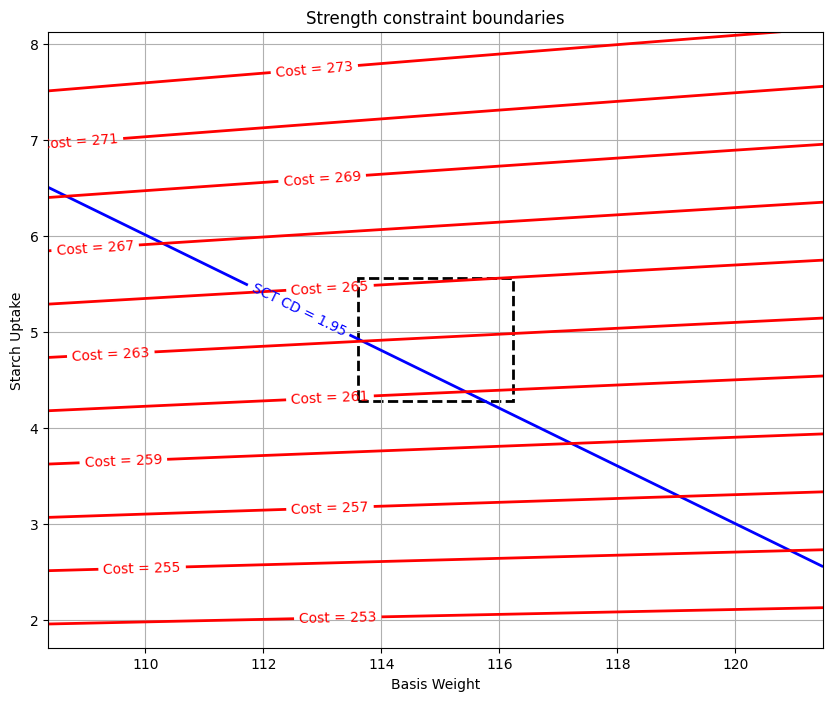

In [6]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_T,
    levels=np.arange(int(np.nanmin(COST_T)), int(np.nanmax(COST_T)),2),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()





In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reference operating point
base = turnup_data[turnup_data.MBS_Current_reel_ID==12604077].copy()

# Ranges
bw_grid = np.linspace(
    BW_min - 2*(BW_max-BW_min),
    BW_max + 2*(BW_max-BW_min),
    100,
)

starch_grid = np.linspace(
    SU_min - 2*(SU_max-SU_min),
    SU_max + 2*(SU_max-SU_min),
    100,
)

BW, STARCH = np.meshgrid(bw_grid, starch_grid)

SCT = np.zeros_like(BW)
BURST = np.zeros_like(BW)
COST_m2 = np.zeros_like(BW)

for i in range(BW.shape[0]):
    for j in range(BW.shape[1]):

        x = base.copy()

        x["Current_basis_weight"] = BW[i, j]
        x['Starch_uptake_by_paper_Bottom_Roll__g/m2_'] = STARCH[i, j]
        x['Starch_uptake_by_paper_Top_Roll__g/m2_'] = 0

        bw_value = float(x["Current_basis_weight"].iloc[0])

        X = pd.DataFrame(x)

        SCT[i, j] = float(sctcd_strength(X)[0])
        BURST[i, j] = float(burst_strength(X)[0])
        COST_m2[i, j] = float(total_cost(X)[0] * bw_value)



In [8]:
with open(f"COST_m2.pkl", 'wb') as f:
        pickle.dump(COST_m2, f)

In [9]:
print("SCT range:", np.nanmin(SCT), np.nanmax(SCT))
print("Burst range:", np.nanmin(BURST), np.nanmax(BURST))
print("Cost range:", np.nanmin(COST_m2), np.nanmax(COST_m2))

SCT range: 1.8448090426944885 2.072227851906691
Burst range: 234.06481820963953 285.0797647196039
Cost range: 27317.51877317855 33152.653924498736


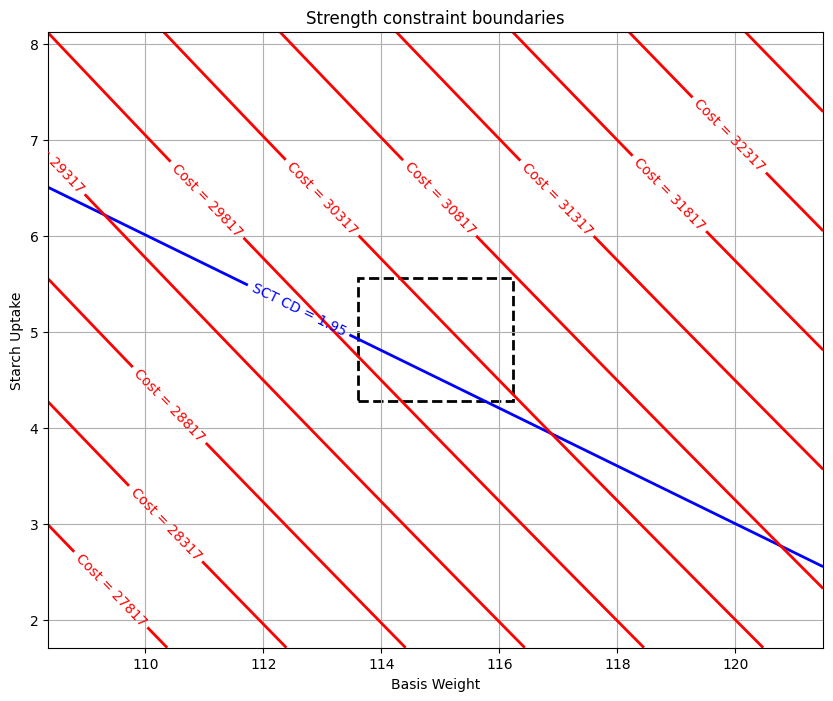

In [10]:
plt.figure(figsize=(10, 8))

# SCT CD = 1.95
cs1 = plt.contour(
    BW,
    STARCH,
    SCT,
    levels=[1.95],
    colors="blue",
    linewidths=2,
)

# Burst = 255
# cs2 = plt.contour(
#     BW,
#     STARCH,
#     BURST,
#     levels=[255],
#     colors="green",
#     linewidths=2,
# )

cs3 = plt.contour(
    BW,
    STARCH,
    COST_m2,
    levels=np.arange(int(np.nanmin(COST_m2)), int(np.nanmax(COST_m2)),500),
    colors="red",
    linewidths=2,
)

plt.clabel(cs1, fmt="SCT CD = %.2f")
#plt.clabel(cs2, fmt="Burst = %.0f")
plt.clabel(cs3, fmt="Cost = %.0f")

plt.xlabel("Basis Weight")
plt.ylabel("Starch Uptake")
plt.title("Strength constraint boundaries")

plt.grid(True)

from matplotlib.patches import Rectangle

ax = plt.gca()

rect = Rectangle(
    (BW_min, SU_min),
    BW_max - BW_min,
    SU_max - SU_min,
    fill=False,
    linewidth=2,
    linestyle="--",
    label="Feasible region"
)

ax.add_patch(rect)

plt.show()


# Knowledge

In [81]:
_,_ = run_query("Que es la retencion en el proceso de fabricacion de papel")

Connecting: ws://127.0.0.1:5000/v2/ws/ask-card
Job ee4bb82a-e385-4446-a2bf-8927cee7bbae: accepted
Job ee4bb82a-e385-4446-a2bf-8927cee7bbae: running
Job ee4bb82a-e385-4446-a2bf-8927cee7bbae: completed


# Retention in the Papermaking Process

## Definition

**Retention** in papermaking refers to the ability to keep solid materials—particularly **fibers, fines (small fiber fragments), and fillers (mineral pigments)**—in the paper sheet during the forming process, rather than losing them through drainage water as the wet web is formed.

## Key Mechanisms

Retention occurs through two primary means:

### 1. **Mechanical (Filtration) Retention**
- Physical trapping of particles as water drains through the forming fiber mat
- More effective for **coarse particles** which are easily filtered into the web
- Particle shape matters: clay and talc platelets show better retention than blocky chalk particles [papermaking_science_technology.pdf:d6f6f20ccb65b658:1217:0]

### 2. **Chemical Retention**
- Uses retention aid chemicals (polymers) to attach particles to fiber surfaces before web formation
- More effective for **fine particles** which have poor mechanical retention
- Creates co-flocculation of fillers with fibers and agglomeration of filler particles [papermaking_science_technology.pdf:d6f6f20ccb65b658:1217:0]

## Retention Mechanisms

Chemical retention operates through three principal categories [papermaking_science_technology.pdf:d6f6f20ccb65b658:1218:0]:

1. **Charge neutralization**
2. **Patch-flocculation** 
3. **Bridging** (most common in practice)

Modern paper machines typically use **dual- or multi-component retention systems** rather than single-polymer systems, as these provide better performance [papermaking_science_technology.pdf:d6f6f20ccb65b658:1218:0].

### Network Flocculation
A specialized mechanism based on hydrogen bonding interactions, useful in contaminated systems where high conductivity suppresses electrostatic interactions [papermaking_science_technology.pdf:d6f6f20ccb65b658:1254:0].

## Importance and Trade-offs

Retention is critically important because it:
- Reduces raw material losses
- Improves product economy
- Creates more homogeneous sheet structure
- Affects drainage and formation

However, **retention, drainage, and formation are all interrelated and opposed to each other**—improving one can impair the others [papermaking_science_technology.pdf:d6f6f20ccb65b658:1254:0].

## Factors Affecting Retention

Key parameters include [papermaking_science_technology.pdf:d6f6f20ccb65b658:1216:1]:
- Furnish composition
- Grammage
- Construction of dewatering elements
- Paper machine running strategy (speed, turbulence level)
- Particle size and shape
- Chemical environment

In [6]:
_,_ = run_query("A question about papermaking: If I want to reduce starch uptake to keep SCT CD and Burst just over some minimum values, it may happen that this reduction is limited by the strength property closer to the minimum. Does it make sense that, by increasing the basis weight I would have more room to more starch reduction?")

HTTP status: 200


Yes, your reasoning makes excellent sense from a papermaking engineering perspective. Let me explain why:

## The Logic Behind Your Approach

**The Fundamental Relationship:**

When you reduce starch uptake, you're weakening multiple strength properties simultaneously (SCT CD, Burst, etc.). Whichever property is closest to its minimum specification becomes your **limiting constraint** - you can't reduce starch any further without falling below spec on that property.

**Why Increasing Basis Weight Creates More Room:**

By increasing basis weight, you're adding more fiber to the sheet structure, which provides:

1. **Inherent strength improvement** - More fibers = stronger base sheet
2. **Higher baseline properties** - All strength properties (SCT, Burst, etc.) improve with the additional fiber
3. **Greater margin above minimums** - This creates a "buffer" that allows for more starch reduction

## Evidence from the Context

The context supports this relationship:

**Basis Weight and Strength Correlation:**
The document discusses trials with different basis weights (95 g/m² FLU vs 160 g/m² TL) and shows that "the amount of starch is by far the most important factor contributing to the strength properties of board" [starch_sizing.pdf:953f472e38cd35ea:9:0].

**Starch Amount Impact:**
The data shows clear relationships between starch pickup and strength properties: "strength properties continue to increase from 60 to 70 kN/m" with increased starch amounts [starch_sizing.pdf:953f472e38cd35ea:16:0], and "burst increase can be explained through differences in starch pick up" [starch_sizing.pdf:953f472e38cd35ea:16:0].

## Practical Optimization Strategy

Your approach would work as follows:

1. **Current state**: Limited starch reduction due to Property X being closest to minimum
2. **Increase basis weight**: All properties improve, including Property X
3. **New opportunity**: Property X now has more margin, allowing further starch reduction
4. **Net result**: Potentially lower total cost (more fiber, less starch) while maintaining specs

## Important Consideration

The economic viability depends on the **relative costs** of fiber vs. starch and the **magnitude of improvement** you can achieve. You'd need to calculate whether the cost of additional fiber is offset by the savings from reduced starch usage.

This is a sound engineering optimization approach that leverages the complementary contributions of fiber and starch to paper strength.

# Benchmark

In [29]:
response = requests.get(
    "http://localhost:5000/process-data/grades",
)

response.json()["grades"]


params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "y_variable_summary_secondary": "Speed",
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "grade",
    "color_variable_summary": "cost_grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": None,
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Current_reel_weight'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "grade",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)

params = {
    "y_variable_summary": ['Combined_cost__€/T_'],
    "x_variable_summary": "week",
    "color_variable_summary": "cost",
    "total_range": ["2026-03-01", "2026-04-30"],
    "output_format": "json",
}

tables, figures = ask_engine(
    params=params,
    endpoint="process-data/grouped",
    download_artifacts = False
)


tables, figures = ask_engine(params = {
    "grade": None,
    "target_range": ["2026-04-01", "2026-04-30"],
    "baseline_range": ["2026-03-01", "2026-03-31"],
    "levels": [2],
    "objects": ["cost"],
    "secondary_objects":["chemicals", "steam", "electricity"],
    "summary": False,
    "output_format": "json",
}, endpoint="diagnosis",run_async=True, download_artifacts= True)



Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,Wedge_Year,Wedge_Week,grammage,paper_type,Speed,cost,Cost__€/T_
0,12601665,2026,10,85,6010,1342.397705,Steam__€/T_,87.782578
1,12601666,2026,10,85,6010,1342.872314,Steam__€/T_,89.354004
2,12601667,2026,10,85,6010,1341.722290,Steam__€/T_,88.837769
3,12601668,2026,10,85,6010,1320.777100,Steam__€/T_,94.010635
4,12601669,2026,10,85,6010,1320.692871,Steam__€/T_,94.009995


grouped


,Wedge_Year,Wedge_Week,cost,Cost__€/T_,n
0,2026,9,Chemicals__€/T_,6.196404,25
1,2026,9,Electricity__€/T_,32.898804,25
2,2026,9,Fibre_cost__€/T_,127.373787,25
3,2026,9,Starch__€/T_,23.865166,25
4,2026,9,Steam__€/T_,87.489822,25


metadata
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Grouped process-data metadata:
{'color_map': {'Chemicals__€/T_': '#AB63FA', 'Electricity__€/T_': '#EF553B', 'Fibre_cost__€/T_': '#FFA15A', 'Starch__€/T_': '#00CC96', 'Steam__€/T_': '#636EFA'}, 'color_variable': 'cost', 'grouped_rows': 50, 'prepared_rows': 7815, 'x_variable': 'Wedge_Week'}
Calling: http://127.0.0.1:5000/process-data/grouped
Note: /process-data/grouped is being called synchronously because it returns DataFrames directly.
Output format: json
HTTP status: 200
process


,MBS_Current_reel_ID,AB_Grade_ID,grammage,paper_type,cost,Cost__€/T_
0,12601665,6010085,85,6010,Steam__€/T_,87.782578
1,12601666,6010085,85,6010,Steam__€/T_,89.354004
2,12601667,6010085,85,6010,Steam__€/T_,88.837769
3,12601668,6010085,85,6010,Steam__€/T_,94.010635
4,12601669,6010085,85,6010,Steam__€/T_,94.009995


... (24 outputs left out)

main


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


diagnosis_table_1


,target,AB_Grade_ID,current_cost,n,cost,previous_cost,pct_cost
0,current,3200115,433.960114,152,TOTAL,285.423035,148.537079
1,current,3300100,353.155365,47,TOTAL,281.258698,71.896667
2,current,3300110,278.191772,57,TOTAL,286.205566,-8.013794
3,current,3300120,275.125885,23,TOTAL,291.348145,-16.222260
4,current,6010085,291.831665,155,TOTAL,301.260162,-9.428497


In [32]:
import pandas as pd
df = pd.read_parquet("aggregated_turned_up_20260825.parquet")

In [33]:
df.tail()

,Wedge_Time,MBS_Current_reel_ID,AB_Grade_ID,MBS_SCT_CD,MBS_SCT_MD,MBS_Burst,MBS_CMT30,Stock_pump_power,Speed,Current_reel_weight,...,Dry_Strength_Agent__€/T_,Natriumhydroxide__€/T_,Electricity__€/T_,Steam__€/T_,Fibre_cost__€/T_,Combined_cost__€/T_,Total_SQM_cost__€/hm2_,source_file,turn_up_rows_used,ambient_temp_C
9,2026-08-25 10:43:00,12606009,6010120,2.13,3.86,277.48,NaN,662.946509,1052.602857,48744.040234,...,0.0,0.092698,30.115634,80.337117,127.844686,263.569635,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.090000
10,2026-08-25 11:04:00,12606010,6010120,NaN,NaN,NaN,NaN,661.557178,1053.481836,15121.545996,...,0.0,0.603153,35.155347,88.004205,127.980130,276.889407,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,17.726667
11,2026-08-25 12:24:00,12606011,6010120,2.21,4.22,284.05,206.0,663.052179,1052.616650,49710.223828,...,0.0,0.601574,35.978729,79.196955,128.290938,268.848218,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,20.100000
12,2026-08-25 13:20:00,12606012,6010120,2.24,3.97,281.96,NaN,662.788000,1052.683166,48655.791406,...,0.0,0.607324,35.556722,83.132453,127.953114,272.267623,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,22.533333
13,2026-08-25 14:15:00,12606013,6010120,NaN,NaN,NaN,NaN,662.852344,1052.687988,47152.318360,...,0.0,0.604682,35.313322,81.104353,127.817965,269.825053,999999.0,data-v2/aggregated/2026/08/25/aggregated_20260...,10,23.325000
